In [1]:
import pandas as pd # manejo de tablas
from pathlib import Path # rutas de archivos y carpetas de forma
import cv2 # procesamiento de imágenes
import matplotlib.pyplot as plt # mostrar imágenes y gráficos 
import numpy as np # operaciones con matrices.
from skimage.segmentation import morphological_chan_vese # contornos activos
from skimage.feature import graycomatrix, graycoprops # textura (GLCM)
from scipy.stats import wilcoxon, kruskal, mannwhitneyu, false_discovery_control # pruebas estadísticas


## Carga y visualización inicial de las imágenes

Se utilizan las 2000 imágenes dermatoscópicas de entrenamiento de
ISIC 2017. Los diagnósticos se obtienen del archivo CSV y se vinculan
con las fotografías mediante el identificador `image_id`.

El conjunto incluye 1372 imágenes de nevus, 374 de melanoma y 254 de
queratosis seborreica. Se verificó que las 2000 fotografías están disponibles en `Data`, que
cada una tiene su diagnóstico en el CSV y su máscara de referencia.

Una vez seleccionada la muestra de trabajo, se visualiza una imagen de
cada diagnóstico junto con su máscara de referencia, para inspeccionar
sus características y detectar elementos que puedan afectar el
procesamiento.

En esta etapa se conserva la resolución original y no se aplican filtros.
Las máscaras de referencia se mantienen separadas de las fotografías.

In [2]:
# Carpeta raíz del dataset. El notebook tiene que estar en la misma carpeta que "Data"
carpeta_data = Path("Data")

# Leer el CSV con los diagnósticos de ISIC 2017
# Tiene una fila por imagen y tres columnas:
# - image_id: identificador de la imagen 
# - melanoma: 1 si es melanoma, 0 si no
# - seborrheic_keratosis: 1 si es queratosis seborreica, 0 si no
# Si ambas columnas valen 0, la lesión es un nevus
df = pd.read_csv(
    carpeta_data / "ISIC-2017_Training_Part3_GroundTruth.csv"
)

# Verificar que las etiquetas sean válidas
# Se toman solo las dos columnas de diagnóstico
etiquetas = df[["melanoma", "seborrheic_keratosis"]]

# Comprueba, celda por celda, que el valor sea 0 o 1.
# Si hay algún valor vacío o distinto, se detiene con un error
if not etiquetas.isin([0, 1]).all().all():
    raise ValueError("Hay etiquetas vacías o diferentes de 0 y 1.")

# Suma las dos columnas en cada fila. Si da más de 1, la imagen tendría dos diagnósticos a la vez, lo cual no es válido
if (etiquetas.sum(axis=1) > 1).any():
    raise ValueError("Hay imágenes con ambos diagnósticos positivos.")

# Crear una columna "diagnostico" con el nombre de la clase.
df["diagnostico"] = np.select(
    [
        df["melanoma"] == 1,
        df["seborrheic_keratosis"] == 1,
    ],
    ["Melanoma", "Queratosis seborreica"],
    default="Nevus"
)

# Mostrar las primeras filas y la cantidad de imágenes por diagnóstico
display(df.head())
display(df["diagnostico"].value_counts())

,image_id,melanoma,seborrheic_keratosis,diagnostico
0,ISIC_0000000,0.0,0.0,Nevus
1,ISIC_0000001,0.0,0.0,Nevus
2,ISIC_0000002,1.0,0.0,Melanoma
3,ISIC_0000003,0.0,0.0,Nevus
4,ISIC_0000004,1.0,0.0,Melanoma


diagnostico
Nevus                    1372
Melanoma                  374
Queratosis seborreica     254
Name: count, dtype: int64

In [3]:
# IDs de las fotografías (.jpg) y de las máscaras de referencia (.png) que hay en las carpetas. 
ids_fotos = {
    ruta.stem
    for ruta in (carpeta_data / "ISIC-2017_Training_Data").glob("*.jpg")
}

# Las máscaras se llaman "ISIC_xxxxxxx_segmentation.png": se quita
# el sufijo "_segmentation" para obtener el mismo identificador
ids_mascaras = {
    ruta.stem.replace("_segmentation", "")
    for ruta in (carpeta_data / "ISIC-2017_Training_Part1_GroundTruth")
    .glob("*_segmentation.png")
}

ids_csv = set(df["image_id"])

# La resta de conjuntos devuelve los elementos del primero que no
# están en el segundo. Las tres cantidades deben dar 0
print(f"Imágenes del CSV sin fotografía: {len(ids_csv - ids_fotos)}")
print(f"Imágenes del CSV sin máscara:    {len(ids_csv - ids_mascaras)}")
print(f"Fotografías sin diagnóstico:     {len(ids_fotos - ids_csv)}")

Imágenes del CSV sin fotografía: 0
Imágenes del CSV sin máscara:    0
Fotografías sin diagnóstico:     0


## Caracterización técnica del conjunto de imágenes

Se recorren las fotografías disponibles en `Data` y se vincula cada una
con su diagnóstico mediante el identificador `image_id`.

Se registran formato, dimensiones, cantidad de canales, tipo de dato,
bits por canal de la matriz cargada y valores mínimo y máximo de intensidad.
Las máscaras PNG y los archivos auxiliares no se incluyen en este análisis.

El objetivo es identificar diferencias técnicas que puedan influir en
el procesamiento. Las diferencias de dimensiones no implican por sí
solas que sea necesario redimensionar las imágenes; cualquier ajuste
posterior deberá justificarse considerando su efecto sobre la forma
y la textura.

In [4]:
# Carpeta con fotografías y superpíxeles
carpeta_imagenes = Path("Data/ISIC-2017_Training_Data")

# Seleccionar solo fotografías JPG, sin incluir los superpíxeles PNG
# Diccionario image_id para abrir cada imagen a partir de su identificador
rutas = {
    ruta.stem: ruta
    for ruta in carpeta_imagenes.iterdir()
    if ruta.is_file() and ruta.suffix.lower() in {".jpg", ".jpeg"}
}

filas = []

# Vincular cada fotografía con el diagnóstico del CSV
for _, registro in df.iterrows():
    image_id = registro["image_id"]
    ruta = rutas[image_id]

    # Leer sin modificar canales ni profundidad
    imagen = cv2.imread(str(ruta), cv2.IMREAD_UNCHANGED)

    # cv2.imread no da error si falla: devuelve None
    if imagen is None:
        raise ValueError(f"No se pudo leer: {ruta}")

    # shape = (alto, ancho, canales) en color o (alto, ancho) en gris
    alto, ancho = imagen.shape[:2]
    canales = 1 if imagen.ndim == 2 else imagen.shape[2]

    filas.append({
        "image_id": image_id,
        "Diagnóstico": registro["diagnostico"],
        "Archivo": ruta.name,
        "Formato": ruta.suffix.lower(),
        "Ancho (px)": ancho,
        "Alto (px)": alto,
        "Canales": canales,
        "Tipo de dato": str(imagen.dtype),
        "Bits por canal": imagen.dtype.itemsize * 8,
        "Mínimo": int(imagen.min()),
        "Máximo": int(imagen.max()),
    })

# Tabla con las propiedades de cada imagen
caracteristicas = pd.DataFrame(filas)

print(f"Total de imágenes: {len(caracteristicas)}")
display(caracteristicas.head())

# Resumen por diagnóstico
# Para cada grupo se calculan mínimos y máximos de las dimensiones,
# y se listan los valores distintos de canales, tipo de dato, bits y formato 
resumen = caracteristicas.groupby("Diagnóstico").agg(
    Cantidad=("Archivo", "count"),
    Ancho_mínimo=("Ancho (px)", "min"),
    Ancho_máximo=("Ancho (px)", "max"),
    Alto_mínimo=("Alto (px)", "min"),
    Alto_máximo=("Alto (px)", "max"),
    Canales=("Canales", lambda x: sorted(x.unique())),
    Tipo_de_dato=("Tipo de dato", lambda x: sorted(x.unique())),
    Bits_por_canal=("Bits por canal", lambda x: sorted(x.unique())),
    Formato=("Formato", lambda x: sorted(x.unique())),
    Intensidad_mínima=("Mínimo", "min"),
    Intensidad_máxima=("Máximo", "max"),
)

display(resumen)

Total de imágenes: 2000


,image_id,Diagnóstico,Archivo,Formato,Ancho (px),Alto (px),Canales,Tipo de dato,Bits por canal,Mínimo,Máximo
0,ISIC_0000000,Nevus,ISIC_0000000.jpg,.jpg,1022,767,3,uint8,8,16,255
1,ISIC_0000001,Nevus,ISIC_0000001.jpg,.jpg,1022,767,3,uint8,8,5,255
2,ISIC_0000002,Melanoma,ISIC_0000002.jpg,.jpg,1022,767,3,uint8,8,0,255
3,ISIC_0000003,Nevus,ISIC_0000003.jpg,.jpg,1022,767,3,uint8,8,15,255
4,ISIC_0000004,Melanoma,ISIC_0000004.jpg,.jpg,1022,767,3,uint8,8,0,255


,Cantidad,Ancho_mínimo,Ancho_máximo,Alto_mínimo,Alto_máximo,Canales,Tipo_de_dato,Bits_por_canal,Formato,Intensidad_mínima,Intensidad_máxima
Diagnóstico,,,,,,,,,,,
Melanoma,374,679,6708,540,4459,[3],[uint8],[8],[.jpg],0,255
Nevus,1372,576,6748,542,4499,[3],[uint8],[8],[.jpg],0,255
Queratosis seborreica,254,1007,6708,704,4461,[3],[uint8],[8],[.jpg],0,255


In [5]:
# Lado mayor de cada imagen (el máximo entre ancho y alto)
caracteristicas["Lado mayor (px)"] = caracteristicas[
    ["Ancho (px)", "Alto (px)"]
].max(axis=1)

# Cantidad de resoluciones distintas en el conjunto
resoluciones = (
    caracteristicas["Ancho (px)"].astype(str) + " × "
    + caracteristicas["Alto (px)"].astype(str)
)
print(f"Resoluciones distintas: {resoluciones.nunique()}\n")

# Resolución por diagnóstico: mediana del lado mayor y porcentaje de
# imágenes grandes (lado mayor superior a 2000 píxeles)
resolucion_por_diagnostico = caracteristicas.groupby("Diagnóstico").agg(
    Lado_mayor_mediano=("Lado mayor (px)", "median"),
    Porcentaje_mayor_2000_px=(
        "Lado mayor (px)", lambda x: 100 * (x > 2000).mean()
    ),
)

display(resolucion_por_diagnostico.round(1))

Resoluciones distintas: 162



,Lado_mayor_mediano,Porcentaje_mayor_2000_px
Diagnóstico,,
Melanoma,3008.0,55.9
Nevus,2304.0,54.3
Queratosis seborreica,3872.0,99.2


### Resultado de la caracterización técnica

Las 2000 fotografías están en formato JPEG, con tres canales de color
(RGB) de 8 bits y valores de intensidad entre 0 y 255 en los tres
diagnósticos.

En cambio, la resolución es muy heterogénea: se identifican 162
resoluciones distintas, con un lado mayor de entre 576 y 6748 píxeles.
Las más frecuentes son 1024 × 768 y 4288 × 2848.

Además, la resolución no es independiente del diagnóstico: el 99 % de
las imágenes de queratosis seborreica tiene un lado mayor superior a
2000 píxeles, frente al 54–56 % de las de nevus y melanoma. Por lo
tanto, cualquier medida expresada en píxeles (área, perímetro, gradiente
o parámetros de textura) puede reflejar diferencias de adquisición y no
de las lesiones. Para la extracción de características se priorizarán
medidas adimensionales o se normalizará la resolución.

No se redimensionan las imágenes en esta etapa. Para las etapas
posteriores se selecciona una muestra aleatoria equilibrada de 50
imágenes por diagnóstico (150 en total).

In [6]:
# Seleccionar 50 imágenes por diagnóstico. Esto se hace al azar pero con una semilla fija para que siempre se elijan las mismas imágenes. 
df_muestra = (
    df.groupby("diagnostico", group_keys=False)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

display(df_muestra["diagnostico"].value_counts())
print(f"Total seleccionado: {len(df_muestra)}")

diagnostico
Melanoma                 50
Nevus                    50
Queratosis seborreica    50
Name: count, dtype: int64

Total seleccionado: 150


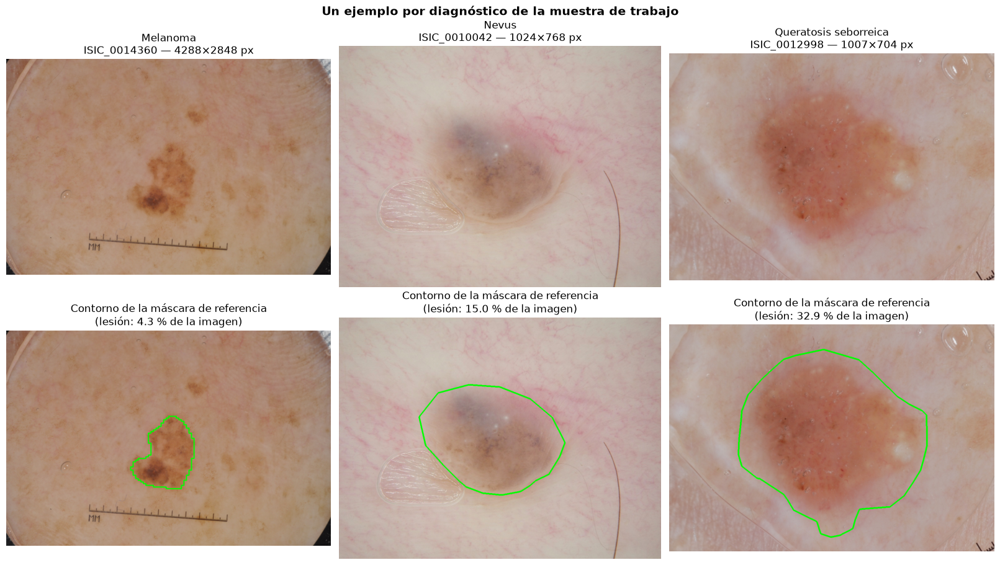

In [7]:
# Carpeta con las máscaras de referencia (segmentaciones de especialistas)
carpeta_mascaras = Path("Data/ISIC-2017_Training_Part1_GroundTruth")

# Primera imagen de cada diagnóstico dentro de la muestra como ejemplo
ejemplos = df_muestra.groupby("diagnostico", sort=False).head(1)

# Figura: arriba la imagen original y abajo el contorno de la máscara
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
fig.suptitle(
    "Un ejemplo por diagnóstico de la muestra de trabajo",
    fontsize=14, fontweight="bold"
)

for columna, (_, registro) in enumerate(ejemplos.iterrows()):
    image_id = registro["image_id"]

    # Leer la imagen y convertirla de BGR a RGB
    original = cv2.cvtColor(
        cv2.imread(str(rutas[image_id])), cv2.COLOR_BGR2RGB
    )

    # La máscara se lee en escala de grises: 255 = lesión, 0 = fondo
    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )

    alto, ancho = original.shape[:2]

    # Se obtiene el borde de la región blanca de la máscara.r
    contornos, _ = cv2.findContours(
        referencia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    # Dibujar el contorno en verde sobre una copia de la original.
    superpuesta = original.copy()
    grosor = max(2, round(max(alto, ancho) / 300))
    cv2.drawContours(superpuesta, contornos, -1, (0, 255, 0), grosor)

    # Porcentaje de la imagen ocupado por la lesión según la referencia
    porcentaje_lesion = 100 * (referencia > 0).mean()

    axes[0, columna].imshow(original)
    axes[0, columna].set_title(
        f"{registro['diagnostico']}\n{image_id} — {ancho}×{alto} px"
    )

    axes[1, columna].imshow(superpuesta)
    axes[1, columna].set_title(
        "Contorno de la máscara de referencia\n"
        f"(lesión: {porcentaje_lesion:.1f} % de la imagen)"
    )

    for ax in axes[:, columna]:
        ax.axis("off")

plt.show()

### Observaciones iniciales

En los ejemplos seleccionados se observan diferencias de tamaño,
color y apariencia, además de elementos que pueden interferir en
el procesamiento:

- **Melanoma (ISIC_0014360):** la lesión ocupa solo el 4,3 % de la
  imagen. Se observan una regla milimetrada, manchas pigmentadas fuera
  de la lesión y esquinas oscuras por el campo circular del dermatoscopio.
- **Nevus (ISIC_0010042):** la lesión ocupa el 15 % de la imagen y
  presenta una región gris azulada. Se observan un reflejo a la
  izquierda, un pelo grueso y vasos en la piel circundante.
- **Queratosis seborreica (ISIC_0012998):** la lesión ocupa el 32,9 %
  de la imagen. Se observan burbujas y reflejos blancos, en especial
  en el ángulo superior derecho.

Las esquinas oscuras y los elementos fuera de la lesión pueden ser
seleccionados por métodos basados en intensidad, y los reflejos y
pelos pueden alterar las mediciones de color y textura. Por ello, se
evaluarán técnicas de preprocesamiento procurando preservar las
características de las lesiones.

Estas observaciones corresponden únicamente a las imágenes mostradas
y no se consideran características generales de cada diagnóstico.

## Análisis de los canales RGB de la muestra

Se calcula la intensidad media de los canales R, G y B para cada una
de las 150 imágenes seleccionadas. Los resultados se agrupan por
diagnóstico y se representan mediante diagramas de caja, que permiten
comparar la mediana y la dispersión de los valores entre imágenes.

Cada observación corresponde a la media de un canal en una fotografía.
El cálculo se realiza sobre la imagen completa, por lo que incluye
la lesión, la piel circundante y los posibles artefactos. Las diferencias
observadas también pueden estar influidas por las condiciones de adquisición.

R                      G                      B  \
                         mean    std  median    mean    std  median    mean   
Diagnóstico                                                                   
Melanoma               176.16  30.90  178.12  144.93  24.90  148.20  133.21   
Nevus                  185.67  30.62  186.73  157.45  31.96  152.54  142.73   
Queratosis seborreica  176.99  23.12  177.31  146.21  24.51  149.42  136.28   

                                      
                         std  median  
Diagnóstico                           
Melanoma               24.30  132.40  
Nevus                  32.72  137.66  
Queratosis seborreica  27.10  136.11

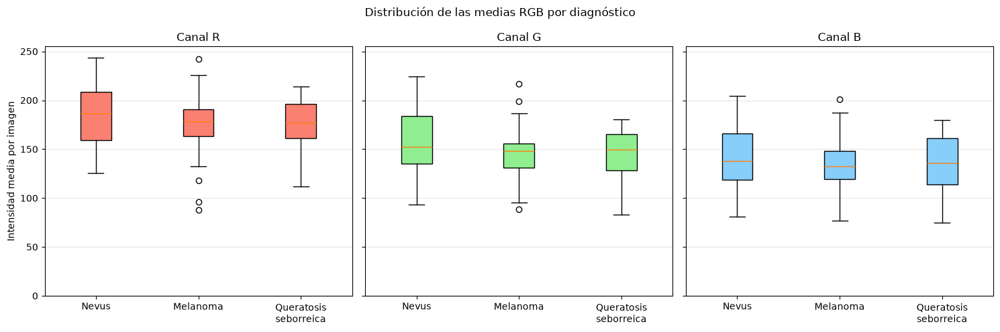

In [8]:
# Lista donde se acumula una fila por imagen con sus medias RGB
filas_rgb = []

# Recorrer las 150 imágenes de la muestra
for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]

    # Abrir la imagen a partir de su identificador
    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer: {rutas[image_id]}")

    # Se convierte a RGB
    rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Promedio de todos los píxeles, separado por canal
    medias = rgb.mean(axis=(0, 1))

    filas_rgb.append({
        "image_id": image_id,
        "Diagnóstico": registro["diagnostico"],
        "R": medias[0],
        "G": medias[1],
        "B": medias[2],
    })

rgb_medias = pd.DataFrame(filas_rgb)

# Resumen de las medias por imagen, agrupadas por diagnóstico
resumen_rgb = (
    rgb_medias.groupby("Diagnóstico")[["R", "G", "B"]]
    .agg(["mean", "std", "median"])
    .round(2)
)

display(resumen_rgb)

# Un diagrama de caja por canal
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]
colores = {"R": "salmon", "G": "lightgreen", "B": "lightskyblue"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, canal in zip(axes, ["R", "G", "B"]):
    # Lista con tres grupos de valores (uno por diagnóstico):
    valores = [
        rgb_medias.loc[rgb_medias["Diagnóstico"] == d, canal]
        for d in diagnosticos
    ]

    # Diagrama de caja
    cajas = ax.boxplot(valores, patch_artist=True)

    for caja in cajas["boxes"]:
        caja.set_facecolor(colores[canal])

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(
        ["Nevus", "Melanoma", "Queratosis\nseborreica"]
    )
    ax.set_title(f"Canal {canal}")
    ax.set_ylim(0, 255)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Intensidad media por imagen")
fig.suptitle("Distribución de las medias RGB por diagnóstico")

plt.tight_layout()
plt.show()

### Histogramas promedio por diagnóstico

Se calculan los histogramas RGB, HSV y de escala de grises de cada imagen.
Cada histograma se normaliza por su cantidad de píxeles y luego se
promedia entre las 50 imágenes de cada diagnóstico, otorgando igual
peso a cada fotografía.

El análisis se realiza sobre las imágenes completas.

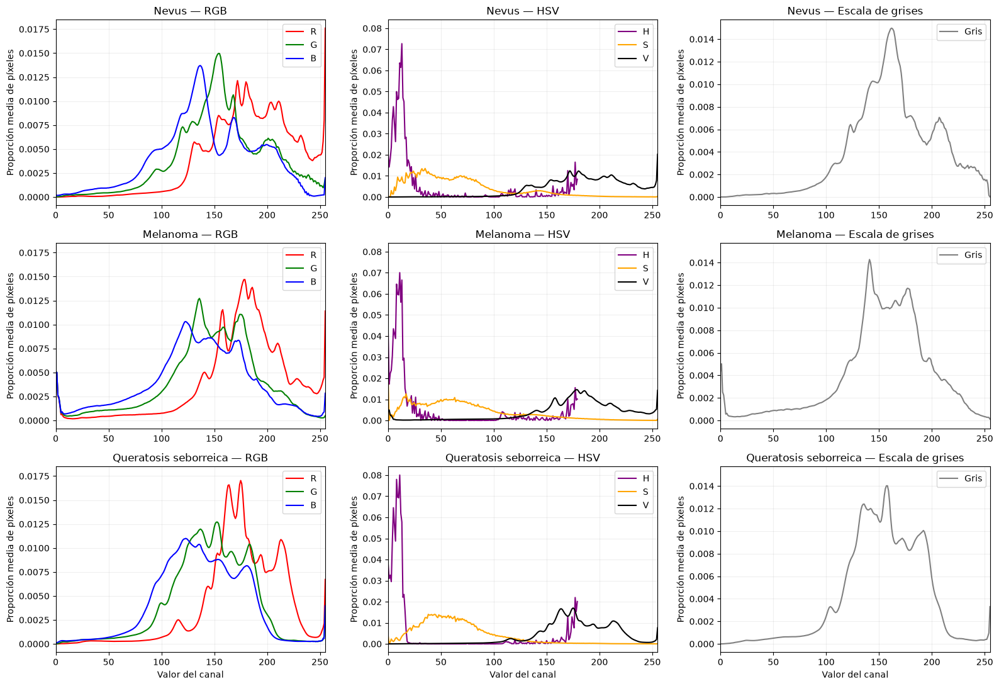

In [9]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

# Guardar histogramas individuales por diagnóstico y canal
canales = ["R", "G", "B", "H", "S", "V", "Gris"]

# Se guarda el histograma de cada imagen de ese grupo
histogramas = {
    diagnostico: {canal: [] for canal in canales}
    for diagnostico in diagnosticos
}

for _, registro in df_muestra.iterrows():
    imagen = cv2.imread(str(rutas[registro["image_id"]]))

    if imagen is None:
        raise ValueError(f"No se pudo leer: {registro['image_id']}")

    rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    # Lista de histogramas del diagnóstico de esta imagen
    grupo = histogramas[registro["diagnostico"]]

    # Cuántos píxeles tienen cada valor, normalizado
    for i, canal in enumerate("RGB"):
        hist = cv2.calcHist([rgb], [i], None, [256], [0, 256])
        grupo[canal].append(hist.ravel() / hist.sum())

    # H va de 0 a 179 (180 valores); S y V de 0 a 255
    for i, (canal, niveles) in enumerate(
        zip(["H", "S", "V"], [180, 256, 256])
    ):
        hist = cv2.calcHist(
            [hsv], [i], None, [niveles], [0, niveles]
        )
        grupo[canal].append(hist.ravel() / hist.sum())

    hist = cv2.calcHist([gris], [0], None, [256], [0, 256])
    grupo["Gris"].append(hist.ravel() / hist.sum())


# Mostrar los promedios: una fila por diagnóstico
fig, axes = plt.subplots(
    3, 3, figsize=(16, 11), sharey="col"
)

for fila, diagnostico in enumerate(diagnosticos):
    grupo = histogramas[diagnostico]

    # Cada panel: (canales a graficar, colores de las curvas, título)
    paneles = [
        (["R", "G", "B"], ["red", "green", "blue"], "RGB"),
        (["H", "S", "V"], ["purple", "orange", "black"], "HSV"),
        (["Gris"], ["gray"], "Escala de grises"),
    ]

    for columna, (nombres, colores, titulo) in enumerate(paneles):
        ax = axes[fila, columna]

        for canal, color in zip(nombres, colores):
            promedio = np.mean(grupo[canal], axis=0)
            ax.plot(promedio, color=color, label=canal)

        ax.set_xlim(0, 255)
        ax.set_title(f"{diagnostico} — {titulo}")
        ax.set_ylabel("Proporción media de píxeles")
        ax.legend()
        ax.grid(alpha=0.2)

for ax in axes[2]:
    ax.set_xlabel("Valor del canal")

plt.tight_layout()
plt.show()

### Estadísticas por canal y distribución de saturación y valor

Se calculan la media y el desvío estándar de los canales R, G, B, S, V
y de la escala de grises sobre cada fotografía completa. Se excluye el
tono H por su naturaleza circular.

Luego se representan mediante diagramas de caja las medias y los
desvíos de los canales S y V. Cada caja resume 50 imágenes de un
diagnóstico. La media describe el nivel promedio de saturación o valor,
mientras que el desvío estándar indica su variación dentro de cada imagen.

In [10]:
# Lista donde se acumula una fila por cada combinación imagen-canal
filas_canales = []

# Niveles posibles de intensidad (0 a 255), como números decimales
niveles = np.arange(256, dtype=float)

for diagnostico in diagnosticos:

    # IDs de las imágenes de este diagnóstico
    ids_grupo = df_muestra.loc[
        df_muestra["diagnostico"] == diagnostico, "image_id"
    ].tolist()

    # H no se incluye: es un ángulo y su media no es representativa
    for canal in ["R", "G", "B", "S", "V", "Gris"]:

        # histogramas[diagnostico][canal] tiene un histograma
        # normalizado por imagen: proporción de píxeles en cada nivel
        for image_id, proporciones in zip(
            ids_grupo, histogramas[diagnostico][canal]
        ):
            # Media 
            media = np.sum(niveles * proporciones)

            # Desvío
            desvio = np.sqrt(np.sum((niveles - media) ** 2 * proporciones))

            filas_canales.append({
                "image_id": image_id,
                "Diagnóstico": diagnostico,
                "Canal": canal,
                "Media": media,
                "Desvío": desvio,
            })

# Tabla con una fila por imagen y canal 
estadisticas_canales = pd.DataFrame(filas_canales)

# Resumen: promedio de la media y del desvío de las 50 imágenes de cada diagnóstico. 
resumen_canales = (
    estadisticas_canales
    .pivot_table(
        index="Canal", columns="Diagnóstico",
        values=["Media", "Desvío"], aggfunc="mean"
    )
    .reindex(["R", "G", "B", "S", "V", "Gris"])
    .round(1)
)

display(resumen_canales)

Desvío                                Media         \
Diagnóstico Melanoma Nevus Queratosis seborreica Melanoma  Nevus   
Canal                                                              
R               28.7  21.0                  22.2    176.2  185.7   
G               34.6  25.1                  24.2    144.9  157.5   
B               38.5  29.0                  24.9    133.2  142.7   
S               34.2  28.3                  22.3     69.2   64.7   
V               29.9  20.6                  21.4    178.4  187.3   
Gris            32.7  23.1                  23.1    152.9  164.2   

                                   
Diagnóstico Queratosis seborreica  
Canal                              
R                           177.0  
G                           146.2  
B                           136.3  
S                            63.2  
V                           177.5  
Gris                        154.3

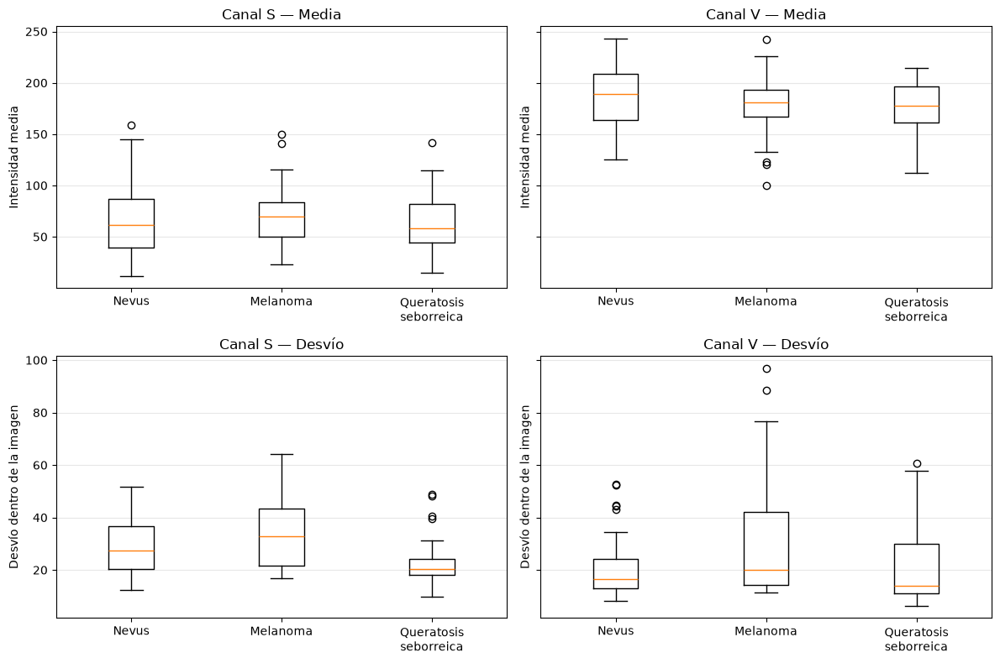

In [11]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

# Figura de 2x2
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey="row")

for columna, canal in enumerate(["S", "V"]):
    # Filas de la tabla correspondientes a este canal
    datos = estadisticas_canales[
        estadisticas_canales["Canal"] == canal
    ]

    for fila, estadistica in enumerate(["Media", "Desvío"]):
        # Un grupo de valores por diagnóstico
        valores = [
            datos.loc[datos["Diagnóstico"] == d, estadistica]
            for d in diagnosticos
        ]

        ax = axes[fila, columna]
        ax.boxplot(valores)

        ax.set_xticks([1, 2, 3])
        ax.set_xticklabels(
            ["Nevus", "Melanoma", "Queratosis\nseborreica"]
        )
        ax.set_title(f"Canal {canal} — {estadistica}")
        ax.set_ylabel(
            "Intensidad media" if fila == 0
            else "Desvío dentro de la imagen"
        )
        ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Observaciones del análisis de color e intensidad

En los tres diagnósticos, las intensidades medias siguen el orden
R > G > B. Las imágenes de nevus presentan medias RGB superiores a
las de los otros grupos y una mayor intensidad media en escala de
grises: 164,2 frente a 152,9 en melanoma y 154,3 en queratosis seborreica.

Sin embargo, los diagramas de caja muestran un amplio solapamiento
entre diagnósticos. Por lo tanto, las medias de intensidad no permiten
establecer una separación clara entre los grupos de esta muestra.

El melanoma presenta una mayor dispersión interna promedio en todos
los canales analizados. En escala de grises, esta alcanza 32,7,
frente a 23,1 en nevus y queratosis seborreica. Esto indica mayor
variación de intensidades dentro de las fotografías del grupo melanoma,
sin implicar necesariamente mayor heterogeneidad de la lesión.

Los histogramas promedio muestran diferencias en sus picos, pero
distribuciones ampliamente superpuestas. En el canal H se observan
concentraciones próximas a ambos extremos del rango, que representan
tonos cercanos debido a su naturaleza circular.

Estas mediciones incluyen lesión, piel circundante y artefactos, y pueden
estar influidas por las condiciones de adquisición. Posteriormente se
analizarán las características dentro de las máscaras para reducir
la contribución del fondo. No se han evaluado aún diferencias
estadísticamente significativas entre diagnósticos.

## Separación entre lesión y fondo por canal de color

Las mediciones anteriores se calculan sobre la imagen completa. Para
identificar qué representación facilita la segmentación, se compara
la intensidad dentro de la lesión con la del fondo, utilizando las
máscaras de referencia.

Primero se visualizan los canales R, G, B, H, S, V y la escala de grises
de un ejemplo por diagnóstico, con el contorno de la referencia
superpuesto. Luego, para cada una de las 150 imágenes y cada canal, se
calcula la separación lesión-fondo: la diferencia absoluta entre la
intensidad media dentro y fuera de la lesión, dividida por el desvío
estándar de toda la imagen. Valores mayores indican que la lesión se
distingue mejor de su entorno.

Las máscaras de referencia se utilizan únicamente para este análisis y
para la evaluación; no intervienen en la segmentación.

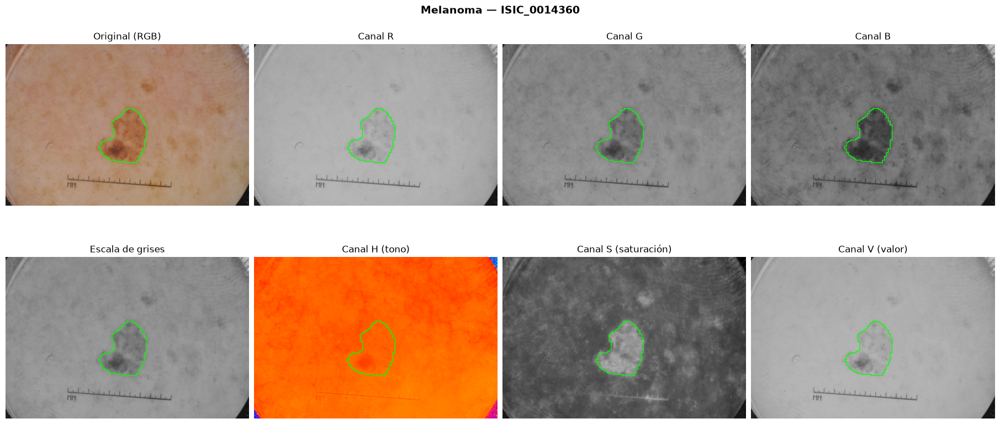

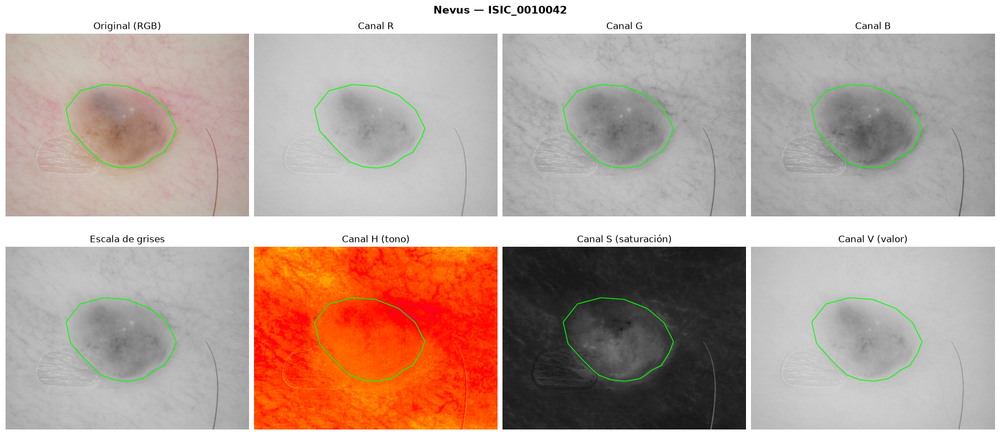

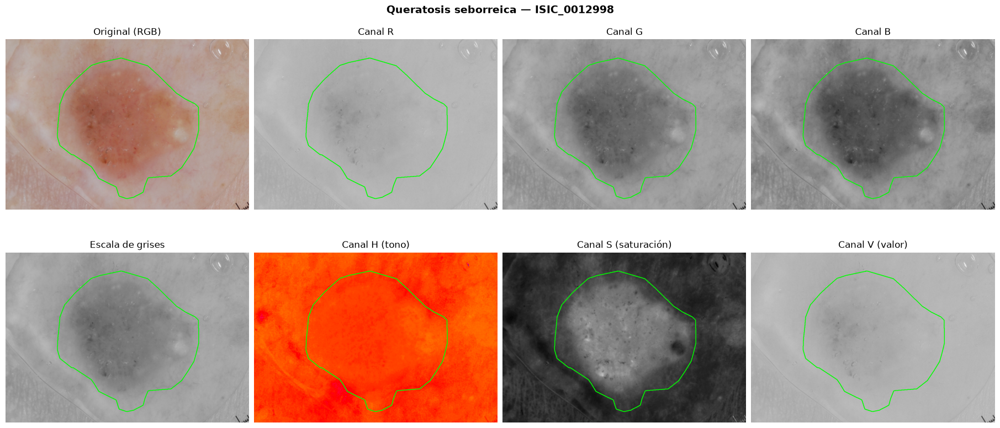

In [12]:
# Para cada ejemplo, se muestran sus canales por separado junto con el
# contorno de la máscara de referencia, para ver en cuál se distingue
# mejor la lesión
for _, registro in ejemplos.iterrows():
    image_id = registro["image_id"]

    original = cv2.cvtColor(
        cv2.imread(str(rutas[image_id])), cv2.COLOR_BGR2RGB
    )
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )

    # Contorno de la lesión, para dibujarlo sobre cada panel
    contornos, _ = cv2.findContours(
        referencia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    paneles = [
        ("Original (RGB)", original, None),
        ("Canal R", original[:, :, 0], "gray"),
        ("Canal G", original[:, :, 1], "gray"),
        ("Canal B", original[:, :, 2], "gray"),
        ("Escala de grises", gris, "gray"),
        ("Canal H (tono)", hsv[:, :, 0], "hsv"),
        ("Canal S (saturación)", hsv[:, :, 1], "gray"),
        ("Canal V (valor)", hsv[:, :, 2], "gray"),
    ]

    fig, axes = plt.subplots(
        2, 4, figsize=(18, 8), constrained_layout=True
    )
    fig.suptitle(
        f"{registro['diagnostico']} — {image_id}",
        fontsize=14, fontweight="bold"
    )

    for ax, (nombre, imagen, cmap) in zip(axes.ravel(), paneles):
        if cmap is None:
            ax.imshow(imagen)
        elif cmap == "hsv":
            # Mapa circular para el tono
            ax.imshow(imagen, cmap="hsv", vmin=0, vmax=179)
        else:
            # Escala fija 0-255 para poder comparar los canales
            ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)

        # Dibujar el contorno de la referencia sobre el panel.
        for contorno in contornos:
            puntos = contorno[:, 0, :]
            ax.plot(
                np.append(puntos[:, 0], puntos[0, 0]),
                np.append(puntos[:, 1], puntos[0, 1]),
                color="lime", linewidth=1
            )

        ax.set_title(nombre)
        ax.axis("off")

    plt.show()

In [13]:
def separacion_lesion_fondo(canal, lesion, fondo):
    """
    Diferencia absoluta entre la media del canal dentro de la lesión y
    fuera de ella, dividida por el desvío de toda la imagen.
    canal: imagen de un solo canal
    lesion, fondo: máscaras uint8 (1 = píxel incluido, 0 = excluido)
    Valores mayores indican que la lesión se distingue mejor del fondo.
    """
    # meanStdDev devuelve la media y el desvío de toda la imagen.
    # Calcula directamente sobre la imagen, sin crear una copia de los píxeles,
    # lo que es mucho más rápido en imágenes grandes
    _, desvio = cv2.meanStdDev(canal)
    desvio = desvio[0, 0]

    # El indicador no está definido si falta una de las dos regiones
    # o si la imagen tiene intensidad constante
    if not lesion.any() or not fondo.any() or desvio == 0:
        return np.nan

    # cv2.mean(canal, mascara) promedia solo los píxeles donde la
    # máscara vale 1. Devuelve 4 valores; el primero es el del canal
    media_lesion = cv2.mean(canal, lesion)[0]
    media_fondo = cv2.mean(canal, fondo)[0]

    return abs(media_lesion - media_fondo) / desvio


filas_separacion_canales = []

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]

    imagen = cv2.imread(str(rutas[image_id]))
    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )

    if imagen is None or referencia is None:
        raise ValueError(f"No se pudo leer la imagen o máscara: {image_id}")

    # Máscaras de lesión y fondo 
    lesion = (referencia > 0).astype(np.uint8)
    fondo = 1 - lesion

    rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    # cv2.split separa una imagen de 3 canales en 3 matrices
    r, g, b = cv2.split(rgb)
    _, s, v = cv2.split(hsv)

    canales_imagen = {"R": r, "G": g, "B": b, "S": s, "V": v, "Gris": gris}

    for canal, valores in canales_imagen.items():
        filas_separacion_canales.append({
            "image_id": image_id,
            "Diagnóstico": registro["diagnostico"],
            "Canal": canal,
            "Separación": separacion_lesion_fondo(valores, lesion, fondo),
        })

separacion_canales = pd.DataFrame(filas_separacion_canales)

orden_canales = ["R", "G", "B", "S", "V", "Gris"]

# Mediana de la separación por canal y diagnóstico
print("Mediana de la separación lesión-fondo:")
display(
    separacion_canales
    .pivot_table(
        index="Canal", columns="Diagnóstico",
        values="Separación", aggfunc="median"
    )
    .reindex(orden_canales)
    .round(2)
)

# Canal con mayor separación en cada imagen
mejor_canal = separacion_canales.loc[
    separacion_canales.groupby("image_id")["Separación"].idxmax()
]
print("Cantidad de imágenes en que cada canal presenta la mayor separación:")
display(pd.crosstab(mejor_canal["Canal"], mejor_canal["Diagnóstico"]))

# Comparación directa con la escala de grises, imagen por imagen
por_imagen = separacion_canales.pivot(
    index="image_id", columns="Canal", values="Separación"
)
for canal in ["G", "S"]:
    proporcion = 100 * (por_imagen[canal] > por_imagen["Gris"]).mean()
    print(f"{canal} supera a la escala de grises en el {proporcion:.0f} % de las imágenes")

Mediana de la separación lesión-fondo:


Diagnóstico,Melanoma,Nevus,Queratosis seborreica
Canal,,,
R,1.17,1.20,0.57
G,1.72,1.91,1.35
B,1.79,1.92,1.67
S,1.88,2.05,1.91
V,1.25,1.21,0.56
Gris,1.66,1.85,1.20


Cantidad de imágenes en que cada canal presenta la mayor separación:


Diagnóstico,Melanoma,Nevus,Queratosis seborreica
Canal,,,
B,13,4,5
G,4,5,2
Gris,0,5,0
R,1,0,3
S,31,35,37
V,1,1,3


G supera a la escala de grises en el 85 % de las imágenes
S supera a la escala de grises en el 79 % de las imágenes


### Resultado de la separación lesión-fondo por canal

En los ejemplos visualizados, la lesión apenas se distingue en los
canales R y V, que presentan valores altos tanto en la lesión como en
la piel: V toma el máximo de los tres canales, que en la piel suele ser
el rojo. En los canales G y B la lesión aparece más oscura que su
entorno, y en el canal S aparece más clara, ya que su color es más
saturado que el de la piel. En S, además, las esquinas oscuras producidas
por el campo circular del dermatoscopio no se confunden con la lesión,
a diferencia de lo que ocurre en la escala de grises.

En las 150 imágenes, el canal S presenta la mayor separación mediana en
los tres diagnósticos (1,88 en melanoma, 2,05 en nevus y 1,91 en
queratosis seborreica) y es el canal con mayor separación en 103 de las
150 imágenes. Los canales R y V presentan las menores separaciones,
en especial en queratosis seborreica (0,56–0,57). El canal G supera a
la escala de grises en el 85 % de las imágenes, y el canal S, en el 79 %.

Estos resultados indican que la escala de grises, utilizada habitualmente
como entrada para la segmentación, no es la representación que mejor
separa la lesión del fondo. Por ello, en la etapa de segmentación se
evaluará el canal S como alternativa a la escala de grises. El indicador
describe diferencias de intensidad media y no garantiza por sí solo una
mejor segmentación.

## Preprocesamiento: comparación de filtros de suavizado

Se aplican filtros de mediana y gaussiano, con ventanas de 3 × 3 píxeles,
a las 150 imágenes de la muestra (50 por diagnóstico).

Cada filtro se aplica de manera independiente sobre la imagen original,
utilizando los mismos parámetros para todos los diagnósticos.

Se registran la media y el desvío de las intensidades en escala de grises
para cada imagen y variante. Además, se muestran imágenes e histogramas
de un ejemplo por diagnóstico para inspeccionar los cambios visuales.

Estas medidas describen cambios en la distribución de intensidades;
su utilidad para la segmentación se evaluará posteriormente mediante
la comparación con las máscaras de referencia.

Estos filtros no constituyen un método específico de eliminación de pelos.

In [14]:
# Función que devuelve las tres variantes a comparar a partir de una
# imagen RGB. Permite reutilizar los mismos filtros más adelante
def aplicar_filtros(original):
    return {
        "Original": original,

        # Filtro de mediana
        "Mediana": cv2.medianBlur(original, 3),

        # Filtro gaussiano
        "Gaussiano": cv2.GaussianBlur(original, (3, 3), 1),
    }

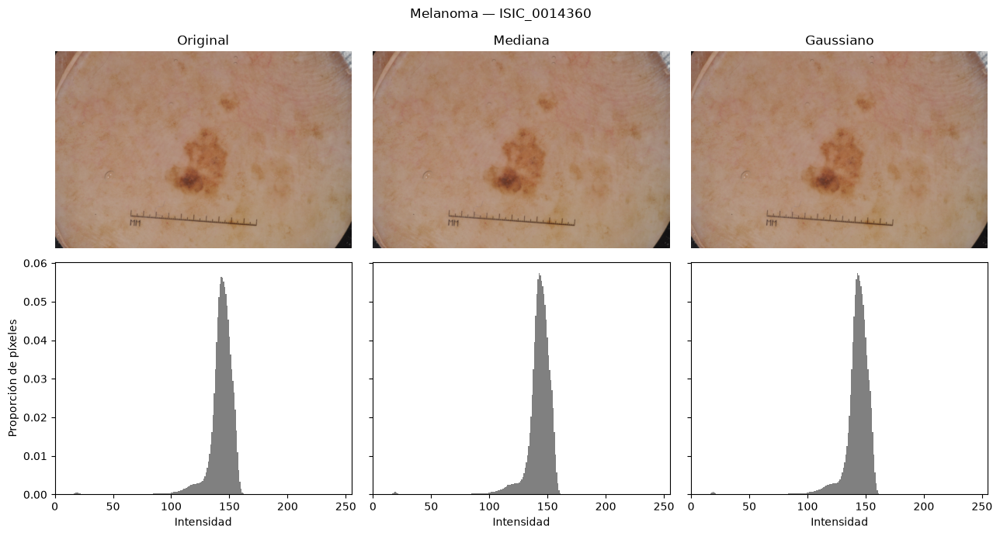

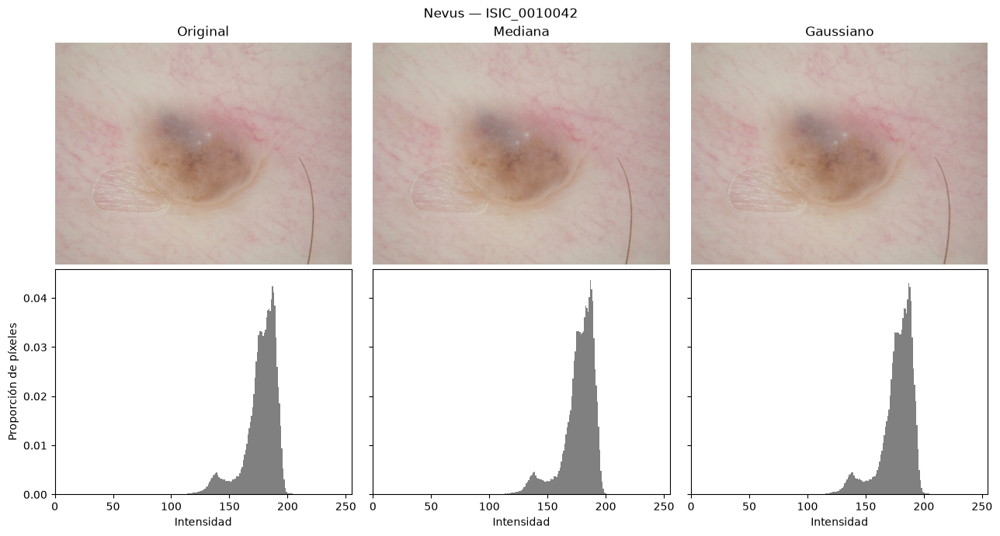

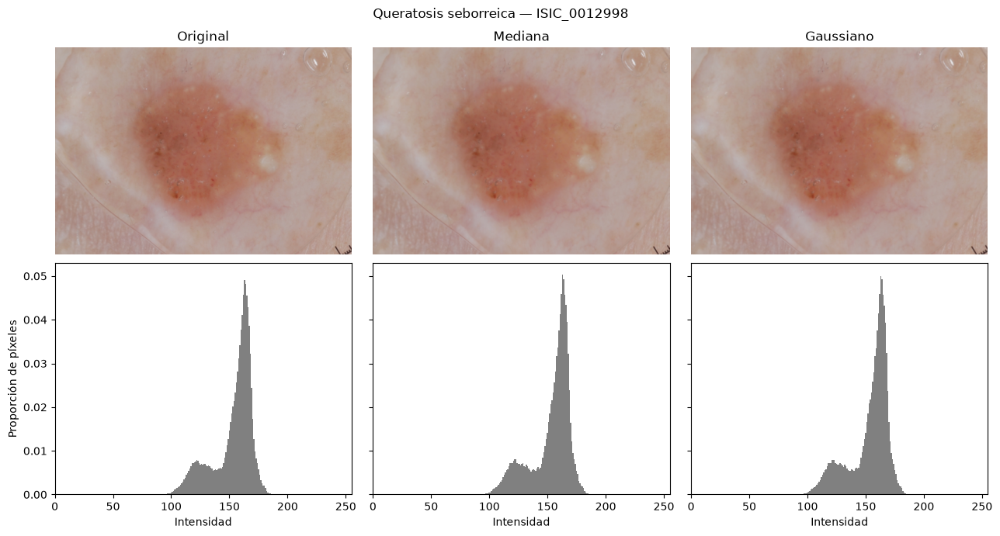

In [15]:
def reducir_para_mostrar(imagen, lado_maximo=800):
    """
    Devuelve una copia reducida de la imagen, solo para graficarla.
    Matplotlib tarda mucho en dibujar imágenes de millones de píxeles,
    y en pantalla no se notan las diferencias. Los cálculos siempre se
    hacen sobre la imagen completa, nunca sobre esta copia.
    """
    alto, ancho = imagen.shape[:2]
    escala = lado_maximo / max(alto, ancho)

    # Si la imagen ya es chica, se devuelve sin cambios
    if escala >= 1:
        return imagen

    # INTER_AREA promedia los píxeles al reducir: achicar imágenes sin generar artefactos
    return cv2.resize(
        imagen, (round(ancho * escala), round(alto * escala)),
        interpolation=cv2.INTER_AREA
    )


# Lista donde se acumula una fila por imagen y variante.
# Se reinician en cada ejecución para no acumular resultados repetidos
filas_filtros = []
diagnosticos_mostrados = set()

# Procesar las mismas 150 imágenes seleccionadas previamente.
for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    variantes = aplicar_filtros(original)

    # Mostrar solamente un ejemplo por diagnóstico: la primera imagen
    mostrar = diagnostico not in diagnosticos_mostrados

    if mostrar:
        # Arriba las imágenes, abajo sus histogramas en gris.
        fig, axes = plt.subplots(
            2, 3, figsize=(13, 7),
            sharex="row", sharey="row"
        )
        fig.suptitle(f"{diagnostico} — {image_id}")

    for columna, (nombre, resultado) in enumerate(variantes.items()):
        gris = cv2.cvtColor(resultado, cv2.COLOR_RGB2GRAY)

        # Media y desvío de la imagen en gris
        media, desvio = cv2.meanStdDev(gris)

        # Registrar estadísticas para TODAS las imágenes.
        filas_filtros.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Media": float(media[0, 0]),
            "Desvío": float(desvio[0, 0]),
        })

        if mostrar:
            # Se grafica una copia reducida (solo para visualizar)
            axes[0, columna].imshow(reducir_para_mostrar(resultado))
            axes[0, columna].set_title(nombre)
            axes[0, columna].axis("off")

            # Histograma normalizado
            hist = cv2.calcHist([gris], [0], None, [256], [0, 256]).ravel()
            axes[1, columna].bar(
                np.arange(256), hist / hist.sum(),
                width=1, color="gray"
            )
            axes[1, columna].set_xlabel("Intensidad")
            axes[1, columna].set_xlim(0, 255)

    if mostrar:
        axes[1, 0].set_ylabel("Proporción de píxeles")
        plt.tight_layout()
        plt.show()

        diagnosticos_mostrados.add(diagnostico)

# Una fila por imagen y variante: 150 × 3 = 450 filas.
estadisticas_filtros = pd.DataFrame(filas_filtros)

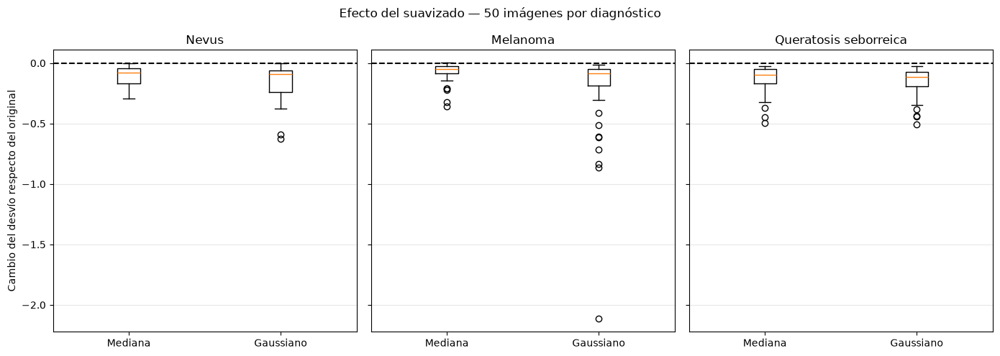

In [16]:
# Colocar las variantes de cada imagen en una misma fila.
comparacion = estadisticas_filtros.pivot(
    index=["image_id", "Diagnóstico"],
    columns="Variante",
    values="Desvío"
)

# Cambio respecto del desvío de la imagen original.
# Resta, fila por fila, el desvío de la original: un valor negativo indica que el filtro redujo la variabilidad
cambios = comparacion[["Mediana", "Gaussiano"]].sub(
    comparacion["Original"], axis=0
)

diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

for ax, diagnostico in zip(axes, diagnosticos):
    datos = cambios.xs(diagnostico, level="Diagnóstico")

    ax.boxplot([datos["Mediana"], datos["Gaussiano"]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Mediana", "Gaussiano"])

    # Línea de referencia en 0 (sin cambio respecto de la original).
    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(diagnostico)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Cambio del desvío respecto del original")
fig.suptitle("Efecto del suavizado — 50 imágenes por diagnóstico")

plt.tight_layout()
plt.show()

### Observaciones sobre los filtros de suavizado

Los filtros de mediana y gaussiano de 3 × 3 producen cambios pequeños
en las estadísticas globales de las imágenes. En los tres diagnósticos,
se observa una ligera disminución del desvío de intensidades respecto
del original.

El filtro gaussiano presenta reducciones más pronunciadas en algunas
imágenes, especialmente en el grupo melanoma. Sin embargo, existe
superposición entre los resultados de ambos filtros.

La disminución del desvío indica una menor variabilidad de intensidades,
pero no permite distinguir entre reducción de ruido y pérdida de detalles.
Por ello, la elección del filtro se apoyará en su efecto sobre la
segmentación, evaluado mediante las máscaras de referencia.

### Inspección ampliada y comparación cuantitativa del suavizado

Se comparan filtros de mediana y gaussianos con ventanas de 3 × 3
y 5 × 5 píxeles sobre las 150 imágenes, utilizando los mismos
parámetros para todos los diagnósticos.

Para observar los detalles locales, se muestra un recorte central de
150 × 150 píxeles de un ejemplo por diagnóstico. Este recorte se utiliza
solo para visualización y no representa necesariamente toda la lesión.
Los filtros se aplican sobre la imagen completa antes de recortarla.

La comparación cuantitativa se realiza sobre las imágenes completas
en escala de grises mediante:

- **Magnitud media del gradiente Sobel:** describe las variaciones locales
  de intensidad. Puede disminuir por suavizado de bordes, detalles o ruido;
  por sí sola no determina la calidad de la imagen.
- **PSNR respecto de la original:** cuantifica la similitud con la imagen
  sin filtrar. Un valor mayor indica menor modificación, pero no demuestra
  una mejor eliminación de ruido.

La media y el desvío de intensidades ya fueron analizados en el bloque
anterior. La utilidad de los filtros se evaluará posteriormente mediante
su efecto sobre la segmentación.

In [17]:
# Variantes para la comparación ampliada: se agregan ventanas de 5x5
# para observar cómo cambia el efecto al aumentar el tamaño del filtro.
def variantes_suavizado(original):
    return {
        "Original": original,
        "Mediana 3×3": cv2.medianBlur(original, 3),
        "Gaussiano 3×3": cv2.GaussianBlur(original, (3, 3), 1),
        "Mediana 5×5": cv2.medianBlur(original, 5),
        "Gaussiano 5×5": cv2.GaussianBlur(original, (5, 5), 1.5),
    }

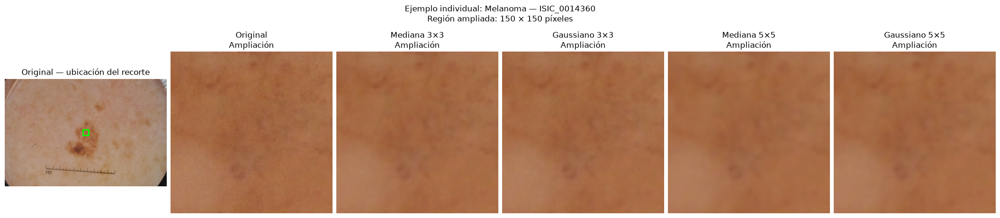

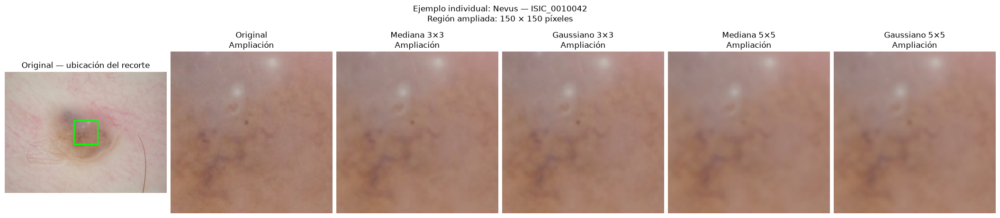

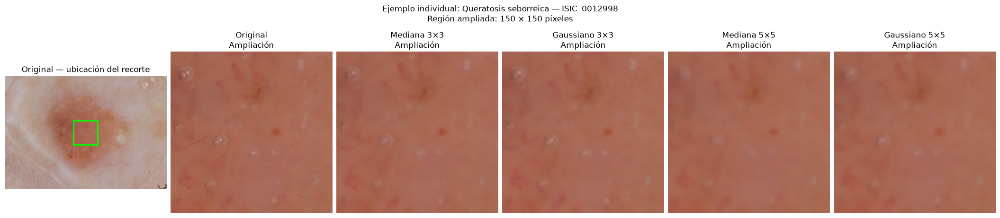

In [18]:
filas_detalle = []
diagnosticos_mostrados = set()

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    gris_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    variantes = variantes_suavizado(original)

    # Las métricas se calculan para las 150 imágenes completas.
    for nombre, resultado in variantes.items():
        gris = cv2.cvtColor(resultado, cv2.COLOR_RGB2GRAY)

        # Gradiente con el operador de Sobel
        gx = cv2.Sobel(gris, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gris, cv2.CV_32F, 0, 1, ksize=3)
        gradiente = cv2.magnitude(gx, gy).mean(dtype=np.float64)

        # PSNR = 10·log10(255² / MSE), donde MSE es el error cuadrático
        # medio respecto de la original. Cuanto MAYOR, más parecida.
        if np.array_equal(gris, gris_original):
            psnr = np.inf
        else:
            psnr = cv2.PSNR(gris_original, gris)

        filas_detalle.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Gradiente medio": gradiente,
            "PSNR (dB)": psnr,
        })

    # Mostrar un ejemplo por diagnóstico.
    if diagnostico not in diagnosticos_mostrados:
        alto, ancho = original.shape[:2]

        # Recorte cuadrado central de 150 px (o menos, si la imagen es más chica)
        lado = min(150, alto, ancho)
        y0 = (alto - lado) // 2
        x0 = (ancho - lado) // 2

        fig, axes = plt.subplots(
            1, 6, figsize=(21, 5), constrained_layout=True
        )
        fig.suptitle(
            f"Ejemplo individual: {diagnostico} — {image_id}\n"
            f"Región ampliada: {lado} × {lado} píxeles"
        )

        # Original completa con el recuadro de la región ampliada
        axes[0].imshow(
            reducir_para_mostrar(original), extent=(0, ancho, alto, 0)
        )

        recuadro = plt.Rectangle(
            (x0, y0), lado, lado,
            edgecolor="lime",
            facecolor="none",
            linewidth=2
        )
        axes[0].add_patch(recuadro)
        axes[0].set_title("Original — ubicación del recorte")
        axes[0].axis("off")

        # Misma región para todas las variantes, en resolución completa
        for ax, (nombre, resultado) in zip(axes[1:], variantes.items()):
            recorte = resultado[y0:y0 + lado, x0:x0 + lado]

            ax.imshow(recorte, interpolation="nearest")
            ax.set_title(f"{nombre}\nAmpliación")
            ax.axis("off")

        plt.show()
        diagnosticos_mostrados.add(diagnostico)

estadisticas_detalle = pd.DataFrame(filas_detalle)

In [19]:
# Reutilizar las métricas calculadas sobre las 150 imágenes
metricas_suavizado = estadisticas_detalle.copy()

# El PSNR de imágenes idénticas es infinito: se excluye del resumen para evitar promediar infinitos.
metricas_suavizado["PSNR (dB)"] = (
    metricas_suavizado["PSNR (dB)"].replace(np.inf, np.nan)
)

orden = [
    "Original",
    "Mediana 3×3",
    "Gaussiano 3×3",
    "Mediana 5×5",
    "Gaussiano 5×5",
]

# Promedios por diagnóstico y variante 
resumen_suavizado = metricas_suavizado.groupby(
    ["Diagnóstico", "Variante"]
).agg(
    Cantidad=("image_id", "nunique"),
    Gradiente_promedio=("Gradiente medio", "mean"),
    PSNR_promedio_dB=("PSNR (dB)", "mean"),
)

# Mostrar las variantes en el orden de las figuras.
resumen_suavizado = resumen_suavizado.reindex(
    pd.MultiIndex.from_product(
        [sorted(metricas_suavizado["Diagnóstico"].unique()), orden],
        names=["Diagnóstico", "Variante"]
    )
)

display(resumen_suavizado.round(2))

Cantidad  Gradiente_promedio  \
Diagnóstico           Variante                                      
Melanoma              Original             50               13.89   
                      Mediana 3×3          50               10.60   
                      Gaussiano 3×3        50               10.59   
                      Mediana 5×5          50                7.99   
                      Gaussiano 5×5        50                8.51   
Nevus                 Original             50               12.84   
                      Mediana 3×3          50                9.58   
                      Gaussiano 3×3        50                9.82   
                      Mediana 5×5          50                7.33   
                      Gaussiano 5×5        50                7.86   
Queratosis seborreica Original             50               13.64   
                      Mediana 3×3          50               10.02   
                      Gaussiano 3×3        50               10.36   
                      Mediana 5×5          50                7.54   
                      Gaussiano 5×5        50                8.23   

                                     PSNR_promedio_dB  
Diagnóstico           Variante                         
Melanoma              Original                    NaN  
                      Mediana 3×3               46.05  
                      Gaussiano 3×3             44.50  
                      Mediana 5×5               41.66  
                      Gaussiano 5×5             41.46  
Nevus                 Original                    NaN  
                      Mediana 3×3               46.10  
                      Gaussiano 3×3             46.30  
                      Mediana 5×5               42.64  
                      Gaussiano 5×5             43.07  
Queratosis seborreica Original                    NaN  
                      Mediana 3×3               45.81  
                      Gaussiano 3×3             46.33  
                      Mediana 5×5               42.26  
                      Gaussiano 5×5             42.93

### Resultado de la comparación cuantitativa

La comparación incluye las 150 imágenes, con 50 muestras por diagnóstico.
Los filtros producen cambios pequeños en la media y el desvío global
de intensidades, pero reducen la magnitud media del gradiente Sobel.

Respecto del gradiente promedio original de cada diagnóstico, la reducción
es aproximadamente del 23–27 % con las ventanas de 3 × 3 y del 39–45 %
con las de 5 × 5. Esto indica una atenuación de las variaciones locales
de intensidad, que pueden corresponder a bordes, textura o ruido.

El PSNR promedio se encuentra entre 44,5 y 46,3 dB para los filtros
de 3 × 3, y entre 41,5 y 43,1 dB para los de 5 × 5. Las ventanas
mayores introducen una modificación más marcada respecto de la original.
Estos valores describen similitud y no demuestran una mejora de calidad.

El tamaño de la ventana se expresa en píxeles, por lo que su efecto
depende de la resolución: en una imagen de 4288 × 2848 píxeles, una
ventana de 3 × 3 abarca una región de la lesión mucho menor que en una
de 1024 × 768. Por ello, en el recorte ampliado del ejemplo de melanoma
(imagen de alta resolución) las diferencias entre variantes son poco
visibles. Por la misma razón, los valores absolutos del gradiente no son
comparables entre diagnósticos con distinta distribución de resoluciones;
solo se comparan las reducciones relativas dentro de cada imagen.

Las diferencias entre mediana y gaussiano dependen de la imagen y del
tamaño de ventana; no se identifica un filtro superior para todos los
diagnósticos a partir de estas medidas.

Se priorizan inicialmente las ventanas de 3 × 3 por introducir menores
modificaciones. La elección definitiva se realizará evaluando su efecto
sobre la segmentación mediante las máscaras de referencia. Para la
caracterización de color y textura se conservarán las imágenes originales.

## Pruebas de mejora de contraste

Se comparan la ecualización global del histograma y la ecualización
adaptativa con limitación de contraste (CLAHE) sobre las 150 imágenes,
con 50 muestras por diagnóstico.

Ambos métodos se aplican de forma independiente sobre la imagen original
en escala de grises, sin suavizado previo y utilizando los mismos
parámetros para todos los diagnósticos.

Se muestran los mismos ejemplos individuales de la comparación de filtros.
Para el conjunto completo se registran la media y el desvío de intensidades.

El objetivo es estudiar los cambios de contraste y su efecto sobre detalles
y artefactos. Su utilidad para la segmentación se evaluará posteriormente
mediante las máscaras de referencia. Las imágenes originales se conservan
para la caracterización de color y textura.

In [20]:
# Objeto CLAHE (ecualización adaptativa con limitación de contraste).
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)  # Grilla de 8 × 8 regiones.
)

In [21]:
# Devuelve las tres variantes a comparar a partir de una imagen en gris
def aplicar_contraste(gris):
    return {
        "Original en gris": gris,

        # Ecualización global
        "Ecualización global": cv2.equalizeHist(gris),

        # CLAHE: aplica el objeto definido en la celda anterior
        "CLAHE": clahe.apply(gris),
    }

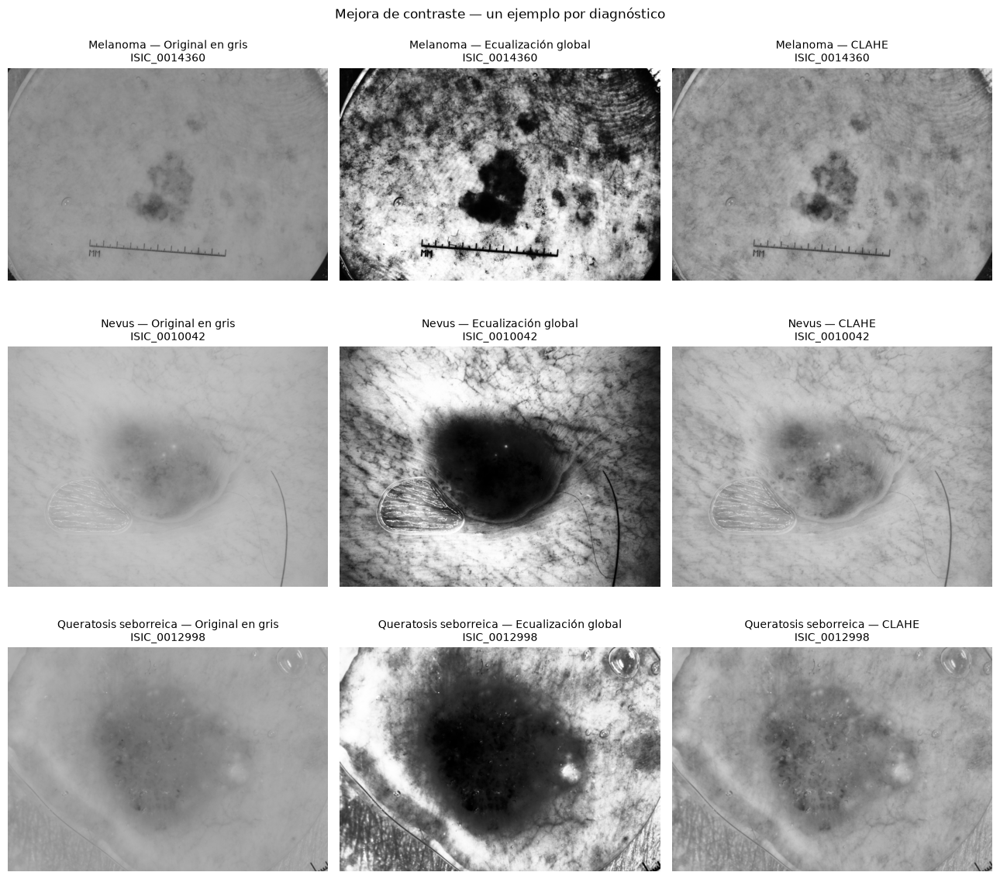

In [22]:
filas_contraste = []

# Guardar solo los ejemplos para visualizarlos y reutilizarlos.
contraste = {}

# Histogramas acumulados por diagnóstico y variante, y cantidad de
# imágenes de cada diagnóstico (para luego calcular el promedio).
histogramas_contraste = {}
cantidades = {}

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    # Conversión directa de BGR (orden de OpenCV) a escala de grises
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    variantes = aplicar_contraste(gris)

    # Al encontrar el primer ejemplo de un diagnóstico, se crean sus histogramas acumulados
    if diagnostico not in histogramas_contraste:
        histogramas_contraste[diagnostico] = {
            nombre: np.zeros(256) for nombre in variantes
        }
        cantidades[diagnostico] = 0

    # Estadísticas de las 150 imágenes.
    for nombre, resultado in variantes.items():
        # Media y desvío 
        media, desvio = cv2.meanStdDev(resultado)

        filas_contraste.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Media": float(media[0, 0]),
            "Desvío": float(desvio[0, 0]),
        })

        # Histograma de esta imagen: se normaliza antes de acumular
        hist = cv2.calcHist(
            [resultado], [0], None, [256], [0, 256]
        ).ravel()
        histogramas_contraste[diagnostico][nombre] += hist / hist.sum()

    cantidades[diagnostico] += 1

    # Mostrar la primera imagen de cada diagnóstico
    if diagnostico not in contraste:
        fila = len(contraste)
        contraste[diagnostico] = variantes

        for columna, (nombre, resultado) in enumerate(variantes.items()):
            # Copia reducida solo para graficar
            axes[fila, columna].imshow(
                reducir_para_mostrar(resultado),
                cmap="gray", vmin=0, vmax=255
            )
            axes[fila, columna].set_title(
                f"{diagnostico} — {nombre}\n{image_id}",
                fontsize=10
            )
            axes[fila, columna].axis("off")

fig.suptitle("Mejora de contraste — un ejemplo por diagnóstico")
plt.tight_layout()
plt.show()

# Una fila por imagen y variante: 150 × 3 = 450 filas
estadisticas_contraste = pd.DataFrame(filas_contraste)

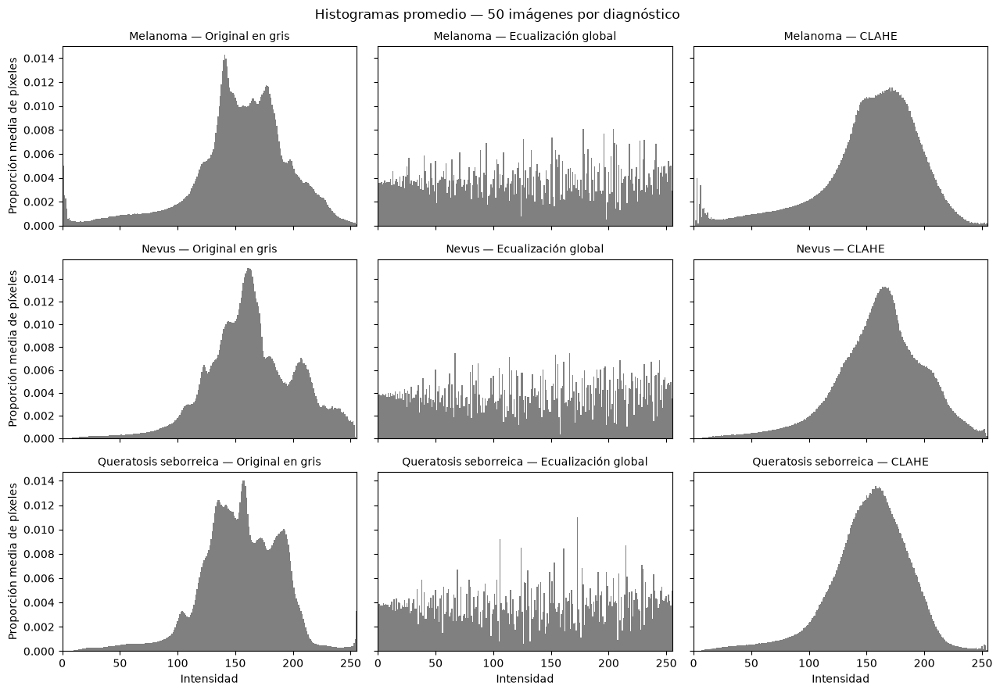

In [23]:
# Histogramas promedio por diagnóstico, a partir de los histogramas acumulados en la celda anterior 
fig, axes = plt.subplots(
    3, 3, figsize=(13, 9),
    sharex=True, sharey="row"
)

for fila, (diagnostico, variantes) in enumerate(
    histogramas_contraste.items()
):
    for columna, (nombre, suma_hist) in enumerate(variantes.items()):
        ax = axes[fila, columna]

        # Promedio: suma de histogramas dividida por la cantidad
        hist_promedio = suma_hist / cantidades[diagnostico]

        ax.bar(
            np.arange(256), hist_promedio,
            width=1, color="gray"
        )
        ax.set_title(f"{diagnostico} — {nombre}", fontsize=10)
        ax.set_xlim(0, 255)

        if fila == 2:
            ax.set_xlabel("Intensidad")
        if columna == 0:
            ax.set_ylabel("Proporción media de píxeles")

fig.suptitle(
    "Histogramas promedio — 50 imágenes por diagnóstico"
)
plt.tight_layout()
plt.show()

### Resultados de las pruebas de mejora de contraste

En los histogramas promedio de las 50 imágenes por diagnóstico, la
ecualización global redistribuye las intensidades sobre un rango más
amplio y genera distribuciones más uniformes, aunque con picos y
discontinuidades propios de la transformación de niveles discretos.

En los ejemplos individuales, esta transformación aumenta marcadamente
el contraste de las lesiones, pero también realza la textura de la piel,
las marcas de escala, los pelos y los reflejos. Por lo tanto, un mayor
contraste visual no implica necesariamente una mejor segmentación.

CLAHE produce un realce más moderado en los ejemplos mostrados. Sus
histogramas promedio conservan una concentración de intensidades más
marcada que los obtenidos mediante ecualización global. También se
acentúan detalles de la piel y artefactos, aunque visualmente con menor
intensidad en estos ejemplos.

Se mantienen la imagen sin ecualizar y ambas alternativas para comparar
su efecto sobre la segmentación mediante Dice y Jaccard respecto de las
máscaras de referencia. Estos resultados aún no permiten establecer
qué método ofrece el mejor desempeño.

### Comparación cuantitativa de la mejora de contraste

Se comparan las variantes sin ecualizar, con ecualización global y con
CLAHE sobre las 150 imágenes, con 50 muestras por diagnóstico.

Se reutilizan la media y el desvío de intensidades calculados previamente.
Como análisis adicional, se mide la separación de intensidades entre la
lesión y el fondo, definidos mediante la máscara de referencia.

El indicador se calcula como la diferencia absoluta entre sus intensidades
medias, dividida por el desvío global de la imagen. Esta normalización
permite comparar la separación relativa entre regiones.

El fondo puede incluir artefactos y no se considera exclusivamente piel
sana. El indicador describe una separación de intensidades y no mide
directamente la precisión de la segmentación.

Las máscaras de referencia se utilizan únicamente para este análisis
y para evaluar los resultados; no intervienen en el preprocesamiento
ni en la generación de las segmentaciones.

In [24]:
# Se utiliza la función separacion_lesion_fondo definida en la sección
# de color (separación lesión-fondo por canal), con la misma fórmula
filas_separacion = []

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    ruta_mascara = carpeta_mascaras / f"{image_id}_segmentation.png"
    mascara = cv2.imread(str(ruta_mascara), cv2.IMREAD_GRAYSCALE)

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    if mascara is None:
        raise FileNotFoundError(f"No se pudo leer la máscara: {ruta_mascara}")

    # Máscaras de lesión y fondo 
    lesion = (mascara > 0).astype(np.uint8)
    fondo = 1 - lesion

    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

    # Misma función y parámetros utilizados en las figuras anteriores.
    variantes = aplicar_contraste(gris)

    for nombre, resultado in variantes.items():
        filas_separacion.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Separación lesión-fondo": separacion_lesion_fondo(
                resultado, lesion, fondo
            ),
        })

# Agregar la separación a las estadísticas previamente calculadas.
metricas_contraste = estadisticas_contraste.merge(
    pd.DataFrame(filas_separacion),
    on=["image_id", "Diagnóstico", "Variante"],
    validate="one_to_one"
)

# Cada fila del resumen corresponde a 50 imágenes.
resumen_contraste = metricas_contraste.groupby(
    ["Diagnóstico", "Variante"]
).agg(
    Cantidad=("image_id", "nunique"),
    Media_promedio=("Media", "mean"),
    Desvío_interno_promedio=("Desvío", "mean"),
    Separación_promedio=("Separación lesión-fondo", "mean"),
    Separación_mediana=("Separación lesión-fondo", "median"),
)

display(resumen_contraste.round(2))

Cantidad  Media_promedio  \
Diagnóstico           Variante                                        
Melanoma              CLAHE                      50          152.88   
                      Ecualización global        50          129.90   
                      Original en gris           50          152.93   
Nevus                 CLAHE                      50          161.42   
                      Ecualización global        50          131.36   
                      Original en gris           50          164.22   
Queratosis seborreica CLAHE                      50          152.35   
                      Ecualización global        50          131.23   
                      Original en gris           50          154.29   

                                           Desvío_interno_promedio  \
Diagnóstico           Variante                                       
Melanoma              CLAHE                                  37.54   
                      Ecualización global                    74.65   
                      Original en gris                       32.67   
Nevus                 CLAHE                                  29.85   
                      Ecualización global                    74.58   
                      Original en gris                       23.12   
Queratosis seborreica CLAHE                                  29.47   
                      Ecualización global                    74.50   
                      Original en gris                       23.08   

                                           Separación_promedio  \
Diagnóstico           Variante                                   
Melanoma              CLAHE                               1.35   
                      Ecualización global                 1.32   
                      Original en gris                    1.56   
Nevus                 CLAHE                               1.70   
                      Ecualización global                 1.40   
                      Original en gris                    1.92   
Queratosis seborreica CLAHE                               1.12   
                      Ecualización global                 1.23   
                      Original en gris                    1.31   

                                           Separación_mediana  
Diagnóstico           Variante                                 
Melanoma              CLAHE                              1.41  
                      Ecualización global                1.56  
                      Original en gris                   1.66  
Nevus                 CLAHE                              1.61  
                      Ecualización global                1.52  
                      Original en gris                   1.85  
Queratosis seborreica CLAHE                              1.05  
                      Ecualización global                1.41  
                      Original en gris                   1.20

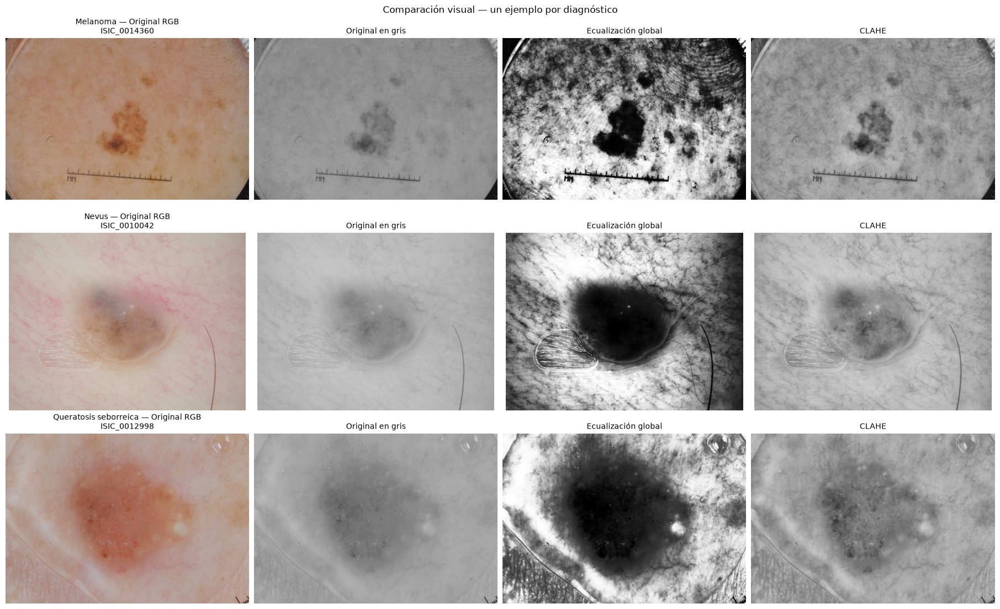

In [25]:
fig, axes = plt.subplots(
    3, 4, figsize=(18, 11), constrained_layout=True
)

for fila, (diagnostico, variantes) in enumerate(contraste.items()):
    # Recuperar el mismo ejemplo mostrado en el bloque de contraste.
    registro = df_muestra[
        df_muestra["diagnostico"] == diagnostico
    ].iloc[0]

    image_id = registro["image_id"]
    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Primera columna: original en color 
    axes[fila, 0].imshow(reducir_para_mostrar(original))
    axes[fila, 0].set_title(
        f"{diagnostico} — Original RGB\n{image_id}", fontsize=10
    )

    # Columnas restantes: variantes ya calculadas.
    for columna, (nombre, resultado) in enumerate(variantes.items(), 1):
        axes[fila, columna].imshow(
            reducir_para_mostrar(resultado),
            cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(nombre, fontsize=10)

    for ax in axes[fila]:
        ax.axis("off")

fig.suptitle("Comparación visual — un ejemplo por diagnóstico")
plt.show()

### Resultado de la comparación cuantitativa del contraste

En las 150 imágenes analizadas, la ecualización global aumenta el
desvío interno promedio desde 23,1–32,7 hasta aproximadamente 74,5
niveles de gris y desplaza la intensidad media hacia valores de
130–131. CLAHE produce cambios más moderados: el desvío interno
promedio alcanza valores de 29,5–37,5 y la media permanece más
próxima a la original.

Sin embargo, ambos métodos reducen la separación promedio normalizada
entre lesión y fondo, calculada mediante las máscaras de referencia.
En melanoma, pasa de 1,56 a 1,35 con CLAHE y 1,32 con ecualización
global; en nevus, de 1,92 a 1,70 y 1,40; y en queratosis seborreica,
de 1,31 a 1,12 y 1,23, respectivamente.

El efecto no es uniforme entre imágenes: en queratosis seborreica, la
separación mediana con ecualización global (1,41) supera a la de la
imagen sin ecualizar (1,20), mientras que el promedio disminuye. Esto
indica que la ecualización mejora la separación en algunas imágenes y
la empeora marcadamente en otras.

Estos resultados pueden compararse con los obtenidos previamente en la
sección *Separación entre lesión y fondo por canal de color*, donde se
calculó el mismo indicador para cada canal sin ecualizar. Allí, el canal
S alcanzó una separación mediana de 1,88 en melanoma, 2,05 en nevus y
1,91 en queratosis seborreica, superior a la de cualquiera de las
variantes en escala de grises evaluadas en esta sección. Esto sugiere
que la elección del canal tiene un efecto mayor sobre la separación
que la ecualización del contraste.

Por lo tanto, el aumento del contraste global no se traduce en una
mayor separación relativa de las intensidades medias de lesión y fondo.
Estas comparaciones son descriptivas y no se ha evaluado su
significación estadística.

En los ejemplos visuales, la ecualización global realza marcadamente
tanto las lesiones como la textura de la piel y los artefactos.
CLAHE presenta un realce más moderado, aunque también acentúa
estructuras del fondo.

Se compararán las tres variantes —sin ecualizar, con ecualización
global y con CLAHE— en la segmentación posterior, evaluando sus
resultados mediante Dice y Jaccard. Las características de color y textura
se calcularán sobre las imágenes originales, dentro de las regiones
seleccionadas por las máscaras.

## Detección de posibles pelos y artefactos oscuros

Los pelos y otros artefactos oscuros pueden generar bordes que interfieren
en la segmentación. Se explora su detección mediante la transformación
black-hat sobre la imagen original en escala de grises, sin ecualización
ni suavizado previo.

El black-hat se calcula como la diferencia entre el cierre morfológico
y la imagen original. Resalta estructuras oscuras más finas que el
elemento estructurante. Su respuesta se umbraliza para obtener una
máscara de posibles artefactos, que se refina morfológicamente y se
corrige mediante inpainting.

Como el tamaño del elemento estructurante se expresa en píxeles, su
efecto depende de la resolución. En las imágenes de mayor resolución
(por ejemplo, 4288 × 2848 píxeles), los pelos son más anchos que un
elemento de 9 × 9 y solo se detectan sus bordes. Por ello, la detección
se realiza sobre una copia reducida a una resolución de trabajo de
1024 píxeles de lado mayor (la resolución más frecuente del conjunto).
La máscara obtenida se lleva luego al tamaño original y el inpainting
se aplica sobre la imagen completa.

Los parámetros se eligen en dos etapas:

1. **Exploración visual** sobre cuatro imágenes seleccionadas
   manualmente por presentar distintos tipos de pelo.
2. **Barrido cuantitativo**: para cada combinación de parámetros se
   evalúa el efecto de la corrección sobre la segmentación (Dice de
   Otsu respecto de la máscara de referencia) en 30 imágenes de ajuste,
   distintas de la muestra de 150 imágenes utilizada para la evaluación.

### Ejemplos para la inspección de pelos

Se seleccionan las imágenes ISIC_0000018, ISIC_0000012, ISIC_0000019
e ISIC_0000032 por la presencia visible de pelos, para inspeccionar
las máscaras de detección y los resultados de la corrección.

Estos cuatro casos constituyen ejemplos de exploración visual.
La evaluación general del procesamiento se mantiene sobre la muestra
balanceada de 150 imágenes.

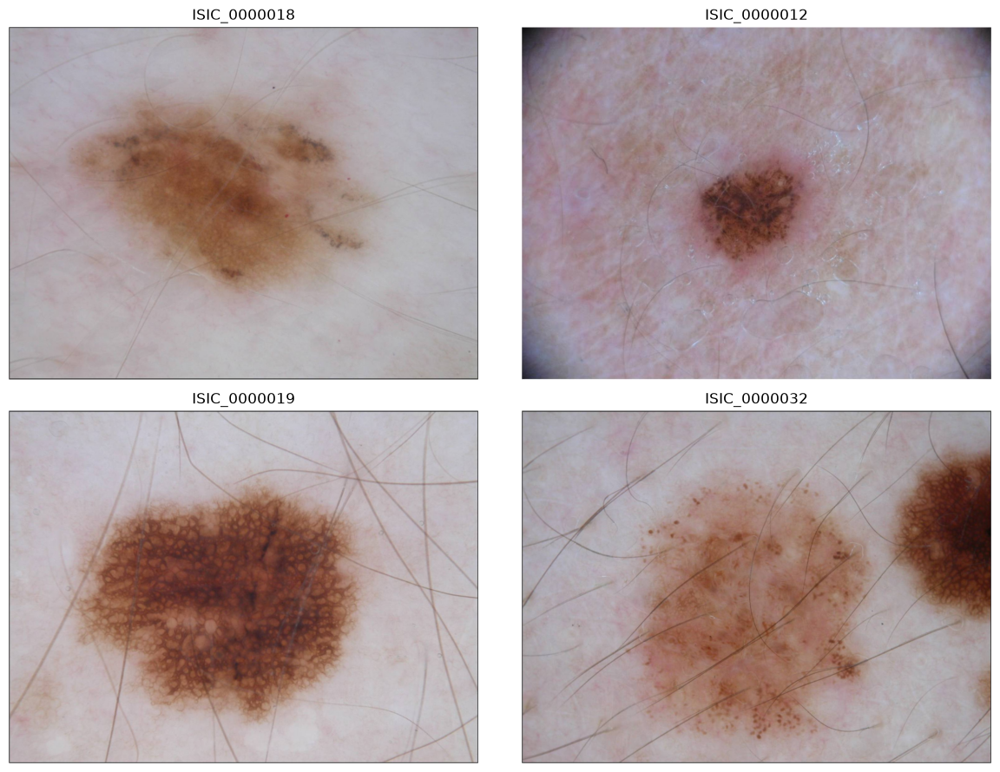

In [26]:
# Resolución de trabajo para la detección de pelos: lado mayor de 1024
# píxeles, la resolución más frecuente del conjunto (1024 × 768).
lado_trabajo = 1024


def reducir_lado_mayor(imagen, lado_maximo):
    """
    Reduce la imagen para que su lado mayor sea lado_maximo, manteniendo
    la proporción. Si ya es más chica, la devuelve sin cambios (nunca
    se agranda). INTER_AREA promedia los píxeles al reducir.
    """
    alto, ancho = imagen.shape[:2]
    escala = lado_maximo / max(alto, ancho)

    if escala >= 1:
        return imagen

    return cv2.resize(
        imagen, (round(ancho * escala), round(alto * escala)),
        interpolation=cv2.INTER_AREA
    )


# Ejemplos específicos para inspeccionar pelos.
# Fueron seleccionados manualmente por presentar distintos tipos de pelo
ids_pelos = [
    "ISIC_0000018",
    "ISIC_0000012",
    "ISIC_0000019",
    "ISIC_0000032",
]

imagenes_pelos = {}

for image_id in ids_pelos:
    if image_id not in rutas:
        raise FileNotFoundError(f"No se encontró {image_id} en rutas.")

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    # Se guardan en RGB y a la resolución de trabajo, porque el barrido
    # exploratorio se realiza en las mismas condiciones que la detección
    imagenes_pelos[image_id] = reducir_lado_mayor(
        cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), lado_trabajo
    )

# Mostrar los cuatro ejemplos.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (image_id, original) in zip(axes.ravel(), imagenes_pelos.items()):
    ax.imshow(original)
    ax.set_title(image_id)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# Combinaciones a evaluar: tamaño del elemento estructurante (en píxeles,
# a la resolución de trabajo) y umbral de la respuesta del black-hat
tamanios_kernel = [5, 9, 13]
umbrales = [10, 15, 20, 30]

filas_artefactos = []

# Evaluar los cuatro ejemplos seleccionados por presencia de pelos.
for image_id, original in imagenes_pelos.items():
    # Las imágenes de este diccionario están en RGB.
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    for tamanio in tamanios_kernel:
        # Elemento estructurante circular: el black-hat resalta las
        # estructuras oscuras MÁS FINAS que este círculo
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (tamanio, tamanio)
        )

        # Black-hat = cierre(imagen) - imagen. El cierre "tapa" las
        # estructuras oscuras finas; al restar la original, solo quedan
        # con valores altos esas estructuras (pelos, marcas, bordes)
        blackhat = cv2.morphologyEx(
            gris, cv2.MORPH_BLACKHAT, kernel
        )

        for umbral in umbrales:
            filas_artefactos.append({
                "image_id": image_id,
                "Kernel": tamanio,
                "Umbral": umbral,
                # Porcentaje de píxeles cuya respuesta supera el umbral
                "Porcentaje marcado": 100 * (blackhat > umbral).mean(),
            })

barrido_parametros = pd.DataFrame(filas_artefactos)

# Cada fila corresponde a una imagen y un tamaño de kernel.
tabla_barrido = barrido_parametros.pivot(
    index=["image_id", "Kernel"],
    columns="Umbral",
    values="Porcentaje marcado"
)

print("Porcentaje de píxeles marcados como posibles artefactos:")
display(tabla_barrido.round(2))

Porcentaje de píxeles marcados como posibles artefactos:


Umbral                  10    15    20    30
image_id     Kernel                         
ISIC_0000012 5        0.56  0.16  0.05  0.00
             9        2.03  0.61  0.22  0.03
             13       4.19  1.27  0.46  0.08
ISIC_0000018 5        0.68  0.50  0.46  0.46
             9        1.30  0.63  0.50  0.46
             13       1.86  0.74  0.54  0.46
ISIC_0000019 5        2.11  1.17  0.77  0.49
             9        6.57  3.61  2.19  0.90
             13      11.06  6.00  3.37  1.22
ISIC_0000032 5        2.99  2.02  1.42  0.72
             9        6.14  3.80  2.65  1.33
             13       8.53  4.93  3.30  1.65

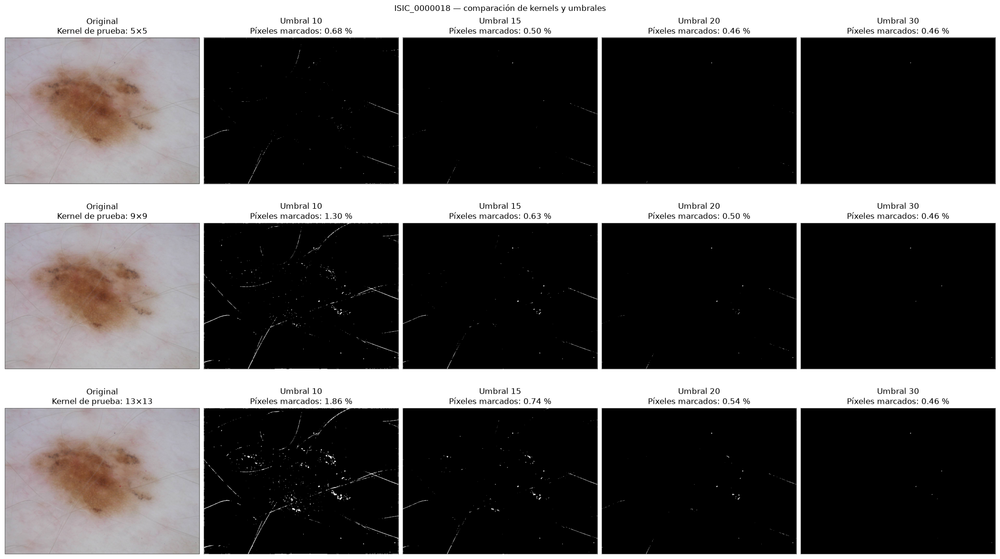

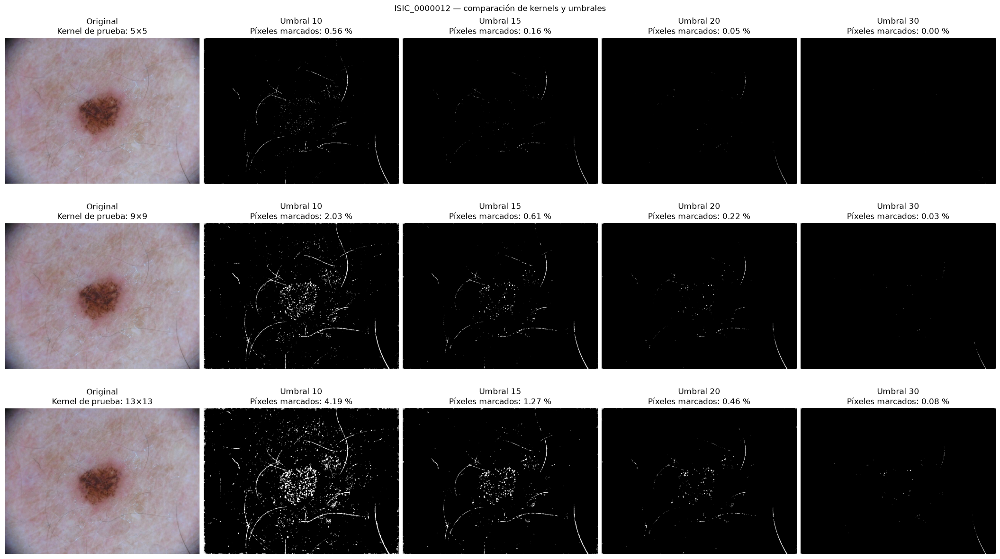

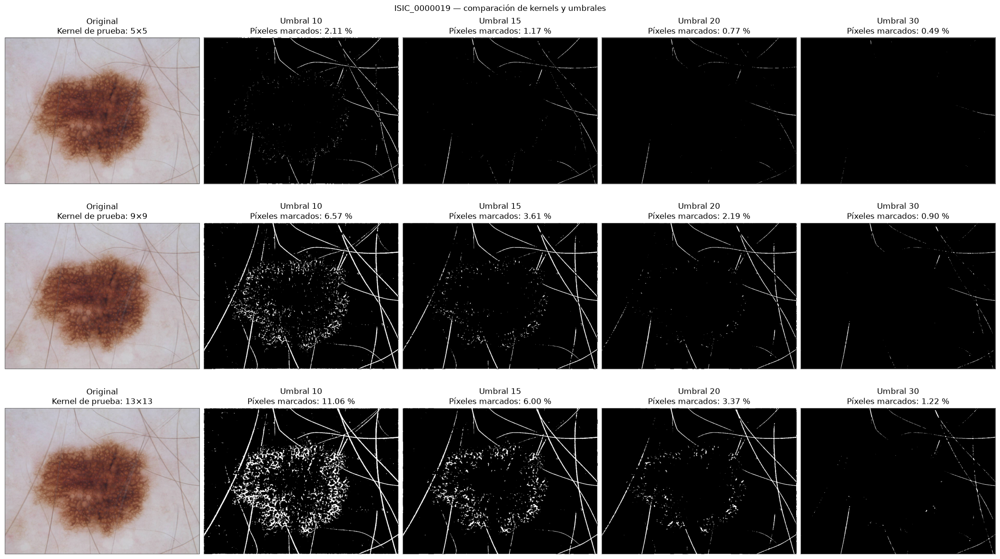

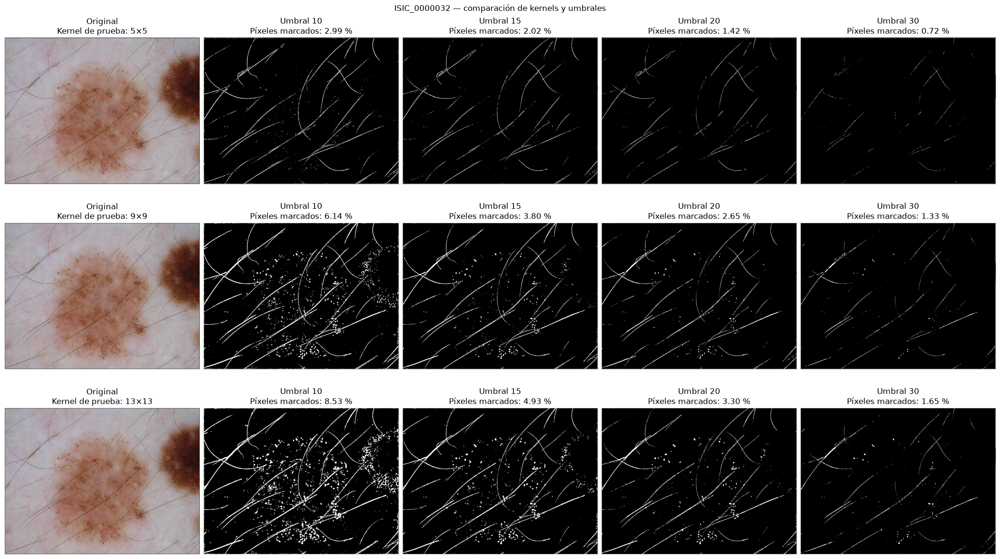

In [28]:
# Mismas combinaciones que en la tabla anterior
tamanios_prueba = tamanios_kernel
umbrales_prueba = umbrales

for image_id, original in imagenes_pelos.items():
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Una fila por kernel
    fig, axes = plt.subplots(
        len(tamanios_prueba),
        len(umbrales_prueba) + 1,
        figsize=(21, 4 * len(tamanios_prueba)),
        constrained_layout=True,
        squeeze=False
    )
    fig.suptitle(f"{image_id} — comparación de kernels y umbrales")

    for fila, tamanio in enumerate(tamanios_prueba):
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (tamanio, tamanio)
        )

        blackhat = cv2.morphologyEx(
            gris, cv2.MORPH_BLACKHAT, kernel
        )

        # Original como referencia en cada fila.
        axes[fila, 0].imshow(original)
        axes[fila, 0].set_title(
            f"Original\nKernel de prueba: {tamanio}×{tamanio}"
        )
        axes[fila, 0].axis("off")

        for columna, umbral in enumerate(umbrales_prueba, start=1):
            # Máscara binaria: 255 (blanco) donde se supera el umbral
            mascara = (blackhat > umbral).astype(np.uint8) * 255
            porcentaje = 100 * (mascara > 0).mean()

            axes[fila, columna].imshow(
                mascara, cmap="gray", vmin=0, vmax=255
            )
            axes[fila, columna].set_title(
                f"Umbral {umbral}\n"
                f"Píxeles marcados: {porcentaje:.2f} %"
            )
            axes[fila, columna].axis("off")

    plt.show()

### Resultado del barrido exploratorio

La detección presenta diferencias entre los cuatro ejemplos. Con el
umbral de 30 se omite gran parte de los pelos visibles (por ejemplo,
se marca solo el 0,03 % de ISIC_0000012 con un kernel de 9 × 9). Al
aumentar el kernel y reducir el umbral, el porcentaje marcado crece,
pero también se incorporan estructuras propias de la lesión: con un
kernel de 13 × 13 y umbral 10 se marca el 11,1 % de ISIC_0000019,
incluyendo puntos y glóbulos dentro de la lesión.

Visualmente, un kernel de 9 × 9 con umbral 15 representa un compromiso
entre la detección de pelos y la preservación de la lesión. Sin
embargo, el porcentaje de píxeles marcados describe la extensión de la
detección y no su precisión, por lo que la elección se evalúa a
continuación mediante su efecto sobre la segmentación.

### Barrido de parámetros según su efecto sobre la segmentación

Para elegir los parámetros con un criterio cuantitativo, se evalúa si
la corrección mejora la segmentación. Para cada combinación de kernel
(5, 9 y 13 píxeles), umbral (10, 15, 20 y 30) y refinamiento (solo
cierre, o cierre seguido de apertura), se corrige la imagen, se segmenta
mediante Otsu inverso sobre la escala de grises y se calcula el
coeficiente de Dice respecto de la máscara de referencia. Se incluye
además la segmentación sin corrección como línea de base.

El barrido se realiza sobre un conjunto de ajuste de 30 imágenes
(10 por diagnóstico), seleccionadas al azar entre las que no forman parte
de la muestra de 150 imágenes. De esta forma, los parámetros no se
ajustan con las mismas imágenes que luego se utilizan para evaluar la
segmentación, lo que evita una estimación optimista del desempeño.
Todo el barrido se realiza a la resolución de trabajo.

In [29]:
def corregir_artefactos(
    imagen_rgb,
    tamanio_kernel=9,
    umbral=15,
    refinamiento="Solo cierre",
    lado_trabajo=1024
):
    """
    Detecta pelos y artefactos oscuros y los corrige mediante inpainting.
    La detección se realiza a la resolución de trabajo (lado mayor de
    lado_trabajo píxeles) y la corrección, sobre la imagen original.
    Devuelve la imagen corregida y la máscara utilizada, ambas con el
    tamaño de la imagen de entrada.
    """
    alto, ancho = imagen_rgb.shape[:2]

    # 1) Detectar estructuras oscuras mediante black-hat
    gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)
    gris_trabajo = reducir_lado_mayor(gris, lado_trabajo)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (tamanio_kernel, tamanio_kernel)
    )
    blackhat = cv2.morphologyEx(
        gris_trabajo, cv2.MORPH_BLACKHAT, kernel
    )

    # 2) Umbralizar la respuesta: 255 = posible artefacto.
    mascara = (blackhat > umbral).astype(np.uint8) * 255

    # 3) Refinar la máscara con un elemento de 3x3.
    #    El cierre une pequeños cortes a lo largo de los pelos; la
    #    apertura opcional elimina puntos aislados, pero también pelos finos
    kernel_chico = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    mascara = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel_chico
    )

    if refinamiento == "Cierre → apertura":
        mascara = cv2.morphologyEx(
            mascara, cv2.MORPH_OPEN, kernel_chico
        )
    elif refinamiento != "Solo cierre":
        raise ValueError("Opción de refinamiento no reconocida.")

    # Llevar la máscara al tamaño original
    if mascara.shape != (alto, ancho):
        mascara = cv2.resize(
            mascara, (ancho, alto), interpolation=cv2.INTER_NEAREST
        )

    # 4) Corregir únicamente los píxeles marcados: el inpainting estima
    #    su valor a partir de los vecinos 
    corregida = cv2.inpaint(
        imagen_rgb, mascara, 3, cv2.INPAINT_TELEA
    )

    return corregida, mascara


def calcular_dice_jaccard(mascara, referencia):
    """
    Compara una máscara obtenida con la máscara de referencia.
    Dice = 2·|A ∩ B| / (|A| + |B|)   Jaccard = |A ∩ B| / |A ∪ B|
    Ambos valen 1 si las máscaras coinciden y 0 si no se superponen.
    """
    prediccion = mascara > 0
    verdad = referencia > 0

    if prediccion.shape != verdad.shape:
        raise ValueError("La predicción y la referencia tienen distinto tamaño.")

    interseccion = np.count_nonzero(prediccion & verdad)
    union = np.count_nonzero(prediccion | verdad)
    suma = np.count_nonzero(prediccion) + np.count_nonzero(verdad)

    # Si ambas máscaras están vacías, se consideran coincidentes
    dice = 2 * interseccion / suma if suma > 0 else 1.0
    jaccard = interseccion / union if union > 0 else 1.0

    return dice, jaccard

In [30]:
# Conjunto de ajuste: 10 imágenes por diagnóstico que NO forman parte de
# la muestra de evaluación.  Así, los parámetros no se eligen con las mismas
# imágenes que luego se usan para evaluar la segmentación
df_ajuste = (
    df[~df["image_id"].isin(df_muestra["image_id"])]
    .groupby("diagnostico", group_keys=False)
    .sample(n=10, random_state=0)
    .reset_index(drop=True)
)

# Combinaciones a evaluar (más la opción sin corrección)
refinamientos = ["Solo cierre", "Cierre → apertura"]
combinaciones = [
    (tamanio, umbral, refinamiento)
    for tamanio in tamanios_kernel
    for umbral in umbrales
    for refinamiento in refinamientos
]


def segmentar_otsu(imagen_rgb):
    """Otsu inverso sobre la escala de grises: lesión = regiones oscuras."""
    gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)
    _, mascara = cv2.threshold(
        gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    return mascara


filas_ajuste = []

for _, registro in df_ajuste.iterrows():
    image_id = registro["image_id"]

    # Imagen y referencia a la resolución de trabajo 
    imagen = cv2.imread(str(rutas[image_id]))
    imagen = reducir_lado_mayor(
        cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), lado_trabajo
    )

    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )
    referencia = cv2.resize(
        referencia, (imagen.shape[1], imagen.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Línea de base: segmentación sin corrección de artefactos
    dice, _ = calcular_dice_jaccard(segmentar_otsu(imagen), referencia)
    filas_ajuste.append({
        "image_id": image_id,
        "Diagnóstico": registro["diagnostico"],
        "Kernel": "—", "Umbral": "—", "Refinamiento": "Sin corrección",
        "% corregido": 0.0,
        "Dice": dice,
    })

    # Segmentación después de corregir con cada combinación
    for tamanio, umbral, refinamiento in combinaciones:
        corregida, mascara = corregir_artefactos(
            imagen, tamanio, umbral, refinamiento, lado_trabajo
        )
        dice, _ = calcular_dice_jaccard(segmentar_otsu(corregida), referencia)

        filas_ajuste.append({
            "image_id": image_id,
            "Diagnóstico": registro["diagnostico"],
            "Kernel": tamanio, "Umbral": umbral,
            "Refinamiento": refinamiento,
            "% corregido": 100 * (mascara > 0).mean(),
            "Dice": dice,
        })

resultados_ajuste = pd.DataFrame(filas_ajuste)

# Resumen por combinación, ordenado de mayor a menor Dice medio
resumen_ajuste = (
    resultados_ajuste
    .groupby(["Kernel", "Umbral", "Refinamiento"])
    .agg(
        Dice_medio=("Dice", "mean"),
        Dice_mediano=("Dice", "median"),
        Porcentaje_corregido=("% corregido", "mean"),
    )
    .sort_values("Dice_medio", ascending=False)
)

print(f"Imágenes de ajuste: {df_ajuste['image_id'].nunique()}")
display(resumen_ajuste.round(3))

Imágenes de ajuste: 30


Dice_medio  Dice_mediano  \
Kernel Umbral Refinamiento                                  
13     10     Solo cierre             0.543         0.596   
              Cierre → apertura       0.542         0.593   
       15     Solo cierre             0.542         0.593   
              Cierre → apertura       0.541         0.590   
9      10     Solo cierre             0.541         0.580   
13     20     Solo cierre             0.540         0.577   
9      10     Cierre → apertura       0.539         0.585   
       15     Solo cierre             0.539         0.581   
              Cierre → apertura       0.538         0.578   
13     20     Cierre → apertura       0.538         0.572   
9      20     Solo cierre             0.537         0.576   
13     30     Solo cierre             0.537         0.579   
5      10     Solo cierre             0.536         0.567   
9      20     Cierre → apertura       0.535         0.570   
       30     Solo cierre             0.535         0.570   
5      10     Cierre → apertura       0.535         0.565   
       15     Solo cierre             0.534         0.567   
13     30     Cierre → apertura       0.531         0.562   
5      20     Solo cierre             0.530         0.557   
       15     Cierre → apertura       0.530         0.562   
9      30     Cierre → apertura       0.528         0.560   
5      30     Solo cierre             0.525         0.561   
       20     Cierre → apertura       0.525         0.550   
       30     Cierre → apertura       0.519         0.547   
—      —      Sin corrección          0.509         0.515   

                                 Porcentaje_corregido  
Kernel Umbral Refinamiento                             
13     10     Solo cierre                      12.293  
              Cierre → apertura                10.964  
       15     Solo cierre                       6.734  
              Cierre → apertura                 5.880  
9      10     Solo cierre                       7.647  
13     20     Solo cierre                       4.224  
9      10     Cierre → apertura                 6.335  
       15     Solo cierre                       4.075  
              Cierre → apertura                 3.297  
13     20     Cierre → apertura                 3.621  
9      20     Solo cierre                       2.643  
13     30     Solo cierre                       2.230  
5      10     Solo cierre                       3.008  
9      20     Cierre → apertura                 2.101  
       30     Solo cierre                       1.429  
5      10     Cierre → apertura                 1.994  
       15     Solo cierre                       1.718  
13     30     Cierre → apertura                 1.839  
5      20     Solo cierre                       1.158  
       15     Cierre → apertura                 1.114  
9      30     Cierre → apertura                 1.061  
5      30     Solo cierre                       0.608  
       20     Cierre → apertura                 0.687  
       30     Cierre → apertura                 0.299  
—      —      Sin corrección                    0.000

In [31]:
# Comparación imagen por imagen entre la combinación elegida y la
# segmentación sin corrección
parametros_elegidos = (9, 15, "Solo cierre")

# Tabla con una fila por imagen y una columna por combinación
por_imagen = resultados_ajuste.pivot_table(
    index=["image_id", "Diagnóstico"],
    columns=["Kernel", "Umbral", "Refinamiento"],
    values="Dice"
)
sin_correccion = por_imagen[("—", "—", "Sin corrección")]
con_correccion = por_imagen[parametros_elegidos]
diferencia = con_correccion - sin_correccion

print(f"Parámetros elegidos: kernel {parametros_elegidos[0]}×{parametros_elegidos[0]}, "
      f"umbral {parametros_elegidos[1]}, {parametros_elegidos[2].lower()}\n")
print(f"Mejora el Dice en más de 0,01:  {(diferencia > 0.01).sum()} imágenes")
print(f"Empeora el Dice en más de 0,01: {(diferencia < -0.01).sum()} imágenes")
print(f"Sin cambios relevantes:         {(diferencia.abs() <= 0.01).sum()} imágenes\n")

# Dice medio por diagnóstico, sin y con corrección
display(pd.DataFrame({
    "Sin corrección": sin_correccion.groupby(level="Diagnóstico").mean(),
    "Con corrección": con_correccion.groupby(level="Diagnóstico").mean(),
}).round(3))

Parámetros elegidos: kernel 9×9, umbral 15, solo cierre

Mejora el Dice en más de 0,01:  9 imágenes
Empeora el Dice en más de 0,01: 2 imágenes
Sin cambios relevantes:         19 imágenes



,Sin corrección,Con corrección
Diagnóstico,,
Melanoma,0.646,0.683
Nevus,0.509,0.532
Queratosis seborreica,0.374,0.402


### Resultado del barrido y elección de parámetros

Todas las combinaciones evaluadas mejoran la segmentación respecto de
no corregir: el Dice medio pasa de 0,509 a valores entre 0,519 y 0,543,
y el Dice mediano, de 0,515 a valores entre 0,547 y 0,596. Las
diferencias entre combinaciones son pequeñas (como máximo 0,024 en el
Dice medio), por lo que el resultado depende más de aplicar la
corrección a una resolución adecuada que de los valores exactos de
los parámetros.

La combinación con mayor Dice medio (kernel de 13 × 13 y umbral 10;
0,543) corrige en promedio el 12,3 % de cada imagen, lo que incluye
estructuras de la lesión. Con un kernel de 9 × 9 y umbral 15 se obtiene
un Dice medio prácticamente igual (0,539; mediana 0,581) corrigiendo
solo el 4,1 % de la imagen. Se seleccionan estos parámetros, que además
coinciden con la elección visual, ya que preservan mejor las
características de la lesión. Para cada kernel y umbral, el refinamiento
con solo cierre obtiene un Dice igual o mayor que el cierre seguido de
apertura, por lo que se adopta solo cierre.

Con los parámetros elegidos, la corrección mejora el Dice en más de 0,01
en 9 de las 30 imágenes de ajuste, lo empeora en 2 y no lo modifica
sustancialmente en las 19 restantes. El Dice medio aumenta en los tres
diagnósticos: de 0,646 a 0,683 en melanoma, de 0,509 a 0,532 en nevus y
de 0,374 a 0,402 en queratosis seborreica. Aun con la corrección, la
segmentación mediante Otsu presenta limitaciones que se analizan en la
sección siguiente.

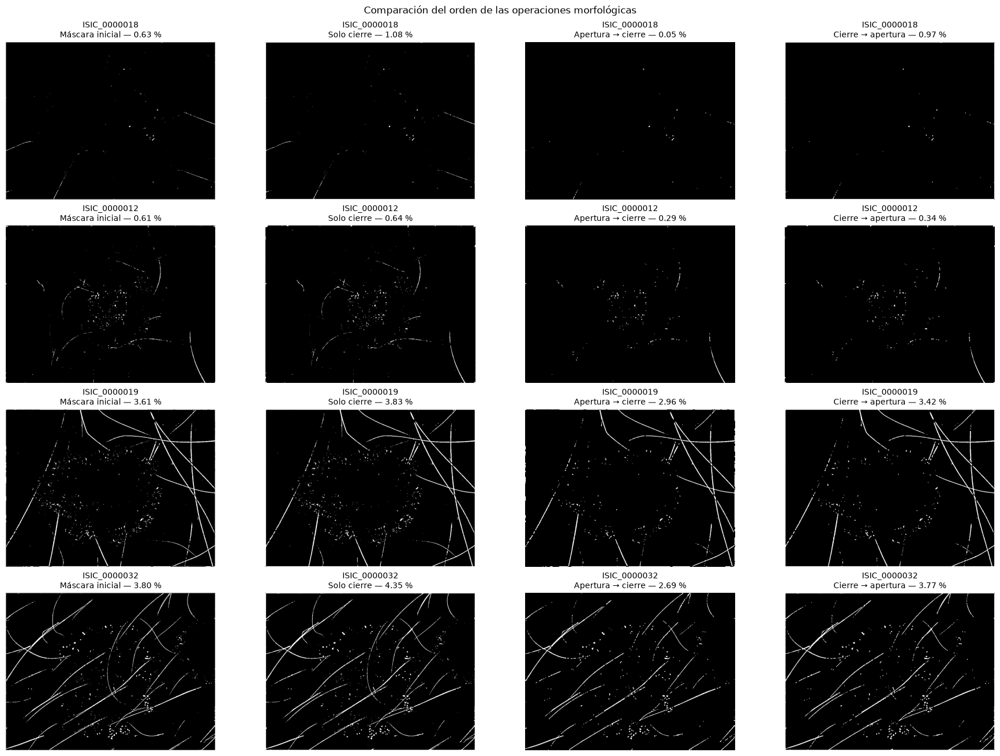

In [32]:
# Parámetros elegidos en el barrido 
tamanio_elegido, umbral_elegido, _ = parametros_elegidos

kernel_blackhat = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (tamanio_elegido, tamanio_elegido)
)
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

mascaras_refinadas = {}

fig, axes = plt.subplots(
    len(imagenes_pelos), 4,
    figsize=(18, 13),
    constrained_layout=True
)

fig.suptitle("Comparación del orden de las operaciones morfológicas")

for fila, (image_id, original) in enumerate(imagenes_pelos.items()):
    # Máscara inicial: black-hat umbralizado con los parámetros elegidos
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    blackhat = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, kernel_blackhat)
    mascara = (blackhat > umbral_elegido).astype(np.uint8) * 255

    # Apertura seguida de cierre.
    # La apertura (erosión + dilatación) elimina componentes chicos,
    # pero también puede borrar pelos de 1-2 píxeles de ancho
    apertura = cv2.morphologyEx(
        mascara, cv2.MORPH_OPEN, kernel
    )
    apertura_cierre = cv2.morphologyEx(
        apertura, cv2.MORPH_CLOSE, kernel
    )

    # Cierre seguido de apertura.
    # El cierre (dilatación + erosión) une pequeños cortes en los pelos
    cierre = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel
    )
    cierre_apertura = cv2.morphologyEx(
        cierre, cv2.MORPH_OPEN, kernel
    )

    paneles = {
        "Máscara inicial": mascara,
        "Solo cierre": cierre,
        "Apertura → cierre": apertura_cierre,
        "Cierre → apertura": cierre_apertura,
    }

    mascaras_refinadas[image_id] = paneles

    for columna, (nombre, resultado) in enumerate(paneles.items()):
        porcentaje = 100 * (resultado > 0).mean()

        axes[fila, columna].imshow(
            resultado, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(
            f"{image_id}\n{nombre} — {porcentaje:.2f} %",
            fontsize=10
        )
        axes[fila, columna].axis("off")

plt.show()

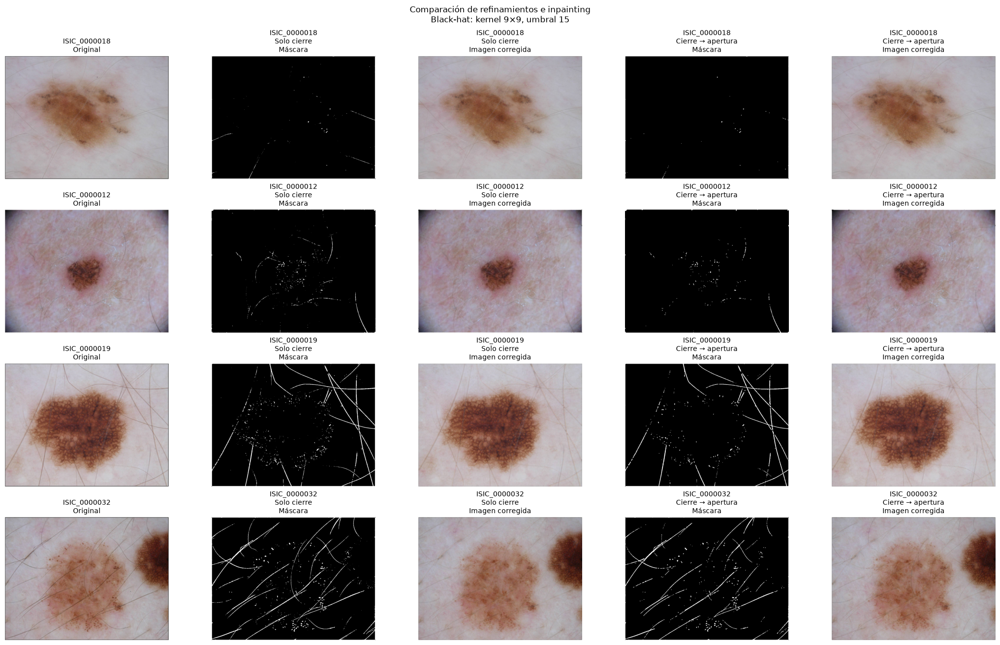

In [33]:
imagenes_corregidas = {}
mascaras_correccion = {}

fig, axes = plt.subplots(
    len(imagenes_pelos), 5,
    figsize=(21, 13),
    constrained_layout=True
)
fig.suptitle(
    "Comparación de refinamientos e inpainting\n"
    f"Black-hat: kernel {tamanio_elegido}×{tamanio_elegido}, "
    f"umbral {umbral_elegido}"
)

for fila, (image_id, original) in enumerate(imagenes_pelos.items()):
    imagenes_corregidas[image_id] = {}
    mascaras_correccion[image_id] = {}

    paneles = [("Original", original)]

    # Se aplica la corrección completa con cada refinamiento
    for refinamiento in refinamientos:
        corregida, mascara = corregir_artefactos(
            original,
            tamanio_kernel=tamanio_elegido,
            umbral=umbral_elegido,
            refinamiento=refinamiento
        )

        imagenes_corregidas[image_id][refinamiento] = corregida
        mascaras_correccion[image_id][refinamiento] = mascara

        paneles.extend([
            (f"{refinamiento}\nMáscara", mascara),
            (f"{refinamiento}\nImagen corregida", corregida),
        ])

    for columna, (nombre, resultado) in enumerate(paneles):
        ax = axes[fila, columna]

        # ndim == 2: máscara (un canal); si no, imagen color
        if resultado.ndim == 2:
            ax.imshow(resultado, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(resultado)

        ax.set_title(f"{image_id}\n{nombre}", fontsize=10)
        ax.axis("off")

plt.show()

### Resultado de la corrección de artefactos

En la comparación de refinamientos, la apertura elimina gran parte de
los pelos finos: aplicada antes del cierre, reduce la máscara de
ISIC_0000018 del 1,08 % al 0,05 % de la imagen. El cierre seguido de
apertura conserva más trazos, pero solo cierre mantiene la detección
más completa, en concordancia con el barrido cuantitativo.

Con los parámetros seleccionados (kernel de 9 × 9 a la resolución de
trabajo, umbral 15, solo cierre e inpainting con radio de 3 píxeles),
se eliminan la mayoría de los pelos oscuros en ISIC_0000019 e
ISIC_0000032. En cambio, los pelos finos y claros de ISIC_0000018 e
ISIC_0000012 se detectan solo parcialmente. Además, las máscaras
incluyen puntos y glóbulos dentro de las lesiones, por lo que el
inpainting también modifica estructuras reales.

Por este motivo, la imagen corregida se utiliza únicamente como entrada
para la segmentación. Las características de color y textura se
calcularán sobre las imágenes originales, dentro de las regiones
seleccionadas, para evitar incorporar valores estimados por el inpainting.

## Segmentación de las lesiones

Todas las pruebas de segmentación se realizan a la resolución de trabajo
(lado mayor de 1024 píxeles), la misma utilizada para la detección de
pelos. Esto evita leer y corregir 150 imágenes de hasta 30 megapíxeles en
cada prueba y hace que todas las imágenes queden a una escala comparable.
La reducción prácticamente no afecta la segmentación: el umbral de Otsu
depende del histograma, que casi no cambia al reducir la imagen, y las
máscaras de referencia se reducen al mismo tamaño para calcular las
métricas. Las imágenes, sus versiones corregidas y las referencias se
preparan una sola vez y se reutilizan en todos los pasos.

La segmentación se desarrolla en tres pasos:

1. **Elección de la entrada:** Se utiliza Otsu como método de prueba
   para evaluar cómo las decisiones de preprocesamiento (corrección de
   artefactos, mejora de contraste y canal de color) modifican la
   segmentación, y se elige la entrada con mejores resultados.
2. **Refinamiento de las máscaras:** Se define un posprocesamiento
   morfológico común para eliminar regiones externas a la lesión y
   rellenar huecos.
3. **Comparación de métodos:** Sobre la entrada elegida y con el mismo
   refinamiento, se comparan los métodos de umbral global fijo, Otsu, 
   crecimiento de regiones, Cannyy el método de contornos activos de 
   Chan–Vese, y se selecciona el de mejor desempeño.

Todas las segmentaciones se evalúan mediante el coeficiente de Dice y el
índice de Jaccard respecto de las máscaras de referencia, que se
utilizan exclusivamente para la evaluación.

In [34]:
# En un único recorrido se guardan, para cada imagen:
# - la escala de grises sin corregir y corregida,
# - el canal S (saturación) de la imagen corregida,
# - la máscara de referencia reducida.
# Para los tres ejemplos que se grafican se guarda además la imagen RGB
datos_segmentacion = {}
ids_ejemplo = set(ejemplos["image_id"])

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]

    imagen = cv2.imread(str(rutas[image_id]))
    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )

    if imagen is None or referencia is None:
        raise ValueError(f"No se pudo leer la imagen o máscara: {image_id}")

    # Imagen RGB a la resolución de trabajo
    original = reducir_lado_mayor(
        cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), lado_trabajo
    )
    alto, ancho = original.shape[:2]

    # Referencia al mismo tamaño. INTER_NEAREST conserva los valores
    # 0 y 255 sin generar valores intermedios
    referencia = cv2.resize(
        referencia, (ancho, alto), interpolation=cv2.INTER_NEAREST
    )

    # Corrección de artefactos con los parámetros elegidos en el barrido
    corregida, _ = corregir_artefactos(
        original,
        tamanio_kernel=tamanio_elegido,
        umbral=umbral_elegido,
        refinamiento="Solo cierre",
        lado_trabajo=lado_trabajo
    )

    datos_segmentacion[image_id] = {
        "Diagnóstico": registro["diagnostico"],
        "Gris sin corrección": cv2.cvtColor(original, cv2.COLOR_RGB2GRAY),
        "Gris": cv2.cvtColor(corregida, cv2.COLOR_RGB2GRAY),
        # Canal S del espacio HSV (índice 1)
        "S": cv2.cvtColor(corregida, cv2.COLOR_RGB2HSV)[:, :, 1],
        "Referencia": referencia,
        "RGB": original if image_id in ids_ejemplo else None,
    }

print(f"Imágenes preparadas: {len(datos_segmentacion)}")


def otsu(canal, invertir=True):
    """
    Umbralización de Otsu: elige automáticamente el umbral que mejor
    separa el histograma en dos clases. Con invertir=True, la lesión es
    la clase oscura (escala de grises); con invertir=False, la clase
    clara (canal S, donde la lesión es más saturada que la piel).
    Devuelve el umbral elegido y la máscara (255 = lesión).
    """
    tipo = cv2.THRESH_BINARY_INV if invertir else cv2.THRESH_BINARY
    umbral, mascara = cv2.threshold(canal, 0, 255, tipo + cv2.THRESH_OTSU)
    return umbral, mascara


def contorno_sobre_imagen(rgb, mascara):
    """Dibuja en verde el contorno exterior de la máscara sobre la imagen."""
    contornos, _ = cv2.findContours(
        mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    superpuesta = rgb.copy()
    cv2.drawContours(superpuesta, contornos, -1, (0, 255, 0), 2)
    return superpuesta

Imágenes preparadas: 150


### Paso 1: elección de la entrada

Para evaluar cómo las decisiones de preprocesamiento modifican la
segmentación, se aplica Otsu sobre cinco entradas:

- **Gris sin corrección:** escala de grises de la imagen original, como
  línea de base.
- **Gris:** escala de grises de la imagen corregida de artefactos, para
  evaluar el efecto de la corrección de pelos.
- **Ecualización global** y **CLAHE** sobre la imagen corregida, para
  evaluar el efecto de la mejora de contraste.
- **Canal S** de la imagen corregida, que en la sección de color presentó
  la mayor separación entre lesión y fondo.

En la escala de grises se utiliza Otsu con umbralización inversa, ya que
la lesión es más oscura que la piel. En el canal S se utiliza Otsu
directo, ya que la lesión es más saturada que la piel y aparece más clara.

Las máscaras se evalúan mediante Dice y Jaccard respecto de las referencias.
Se muestran máscaras y contornos de un ejemplo por diagnóstico. En esta
etapa no se aplica limpieza morfológica ni selección de componentes.

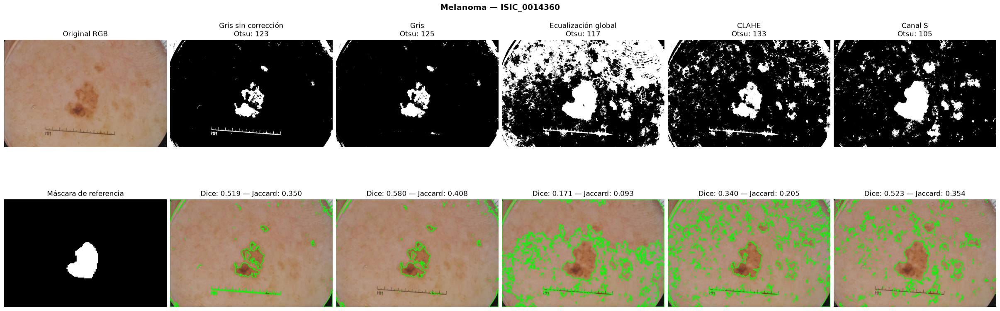

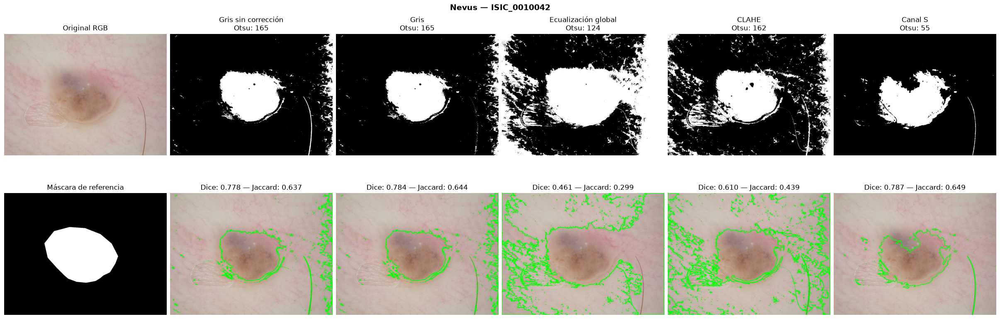

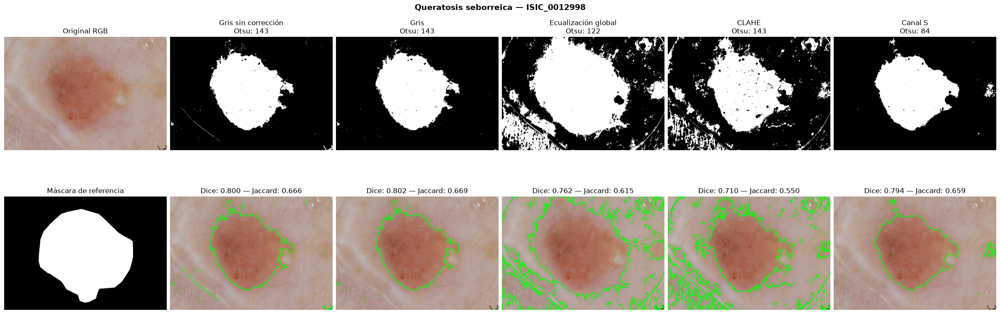

Dice_promedio  Dice_mediano  \
Diagnóstico           Entrada                                            
Melanoma              Gris sin corrección          0.584         0.672   
                      Gris                         0.611         0.711   
                      Ecualización global          0.497         0.423   
                      CLAHE                        0.548         0.575   
                      Canal S                      0.729         0.798   
Nevus                 Gris sin corrección          0.514         0.577   
                      Gris                         0.533         0.612   
                      Ecualización global          0.326         0.283   
                      CLAHE                        0.487         0.484   
                      Canal S                      0.676         0.755   
Queratosis seborreica Gris sin corrección          0.403         0.414   
                      Gris                         0.431         0.435   
                      Ecualización global          0.336         0.316   
                      CLAHE                        0.386         0.400   
                      Canal S                      0.553         0.617   

                                           Jaccard_promedio  Jaccard_mediano  
Diagnóstico           Entrada                                                 
Melanoma              Gris sin corrección             0.463            0.507  
                      Gris                            0.490            0.552  
                      Ecualización global             0.373            0.268  
                      CLAHE                           0.412            0.404  
                      Canal S                         0.608            0.664  
Nevus                 Gris sin corrección             0.400            0.405  
                      Gris                            0.424            0.441  
                      Ecualización global             0.215            0.165  
                      CLAHE                           0.352            0.319  
                      Canal S                         0.567            0.606  
Queratosis seborreica Gris sin corrección             0.306            0.261  
                      Gris                            0.330            0.278  
                      Ecualización global             0.223            0.188  
                      CLAHE                           0.264            0.250  
                      Canal S                         0.434            0.446

La corrección mejora el Dice en más de 0,01 en 55 imágenes y lo empeora en 15
El canal S supera a la escala de grises en el 78 % de las imágenes


In [35]:
# Entradas a comparar para Otsu. Cada una es un par
# (imagen de un canal, invertir): en escala de grises la lesión es
# oscura (Otsu inverso) y en el canal S es clara (Otsu directo).
# Salvo la primera, todas parten de la imagen corregida de artefactos
def entradas_otsu(datos):
    return {
        "Gris sin corrección": (datos["Gris sin corrección"], True),
        "Gris": (datos["Gris"], True),
        "Ecualización global": (cv2.equalizeHist(datos["Gris"]), True),
        "CLAHE": (clahe.apply(datos["Gris"]), True),
        "Canal S": (datos["S"], False),
    }


filas_entradas_otsu = []

for image_id, datos in datos_segmentacion.items():
    referencia = datos["Referencia"]
    resultados_imagen = {}

    for nombre, (entrada, invertir) in entradas_otsu(datos).items():
        umbral, mascara = otsu(entrada, invertir)
        dice, jaccard = calcular_dice_jaccard(mascara, referencia)
        resultados_imagen[nombre] = (mascara, umbral, dice, jaccard)

        filas_entradas_otsu.append({
            "image_id": image_id,
            "Diagnóstico": datos["Diagnóstico"],
            "Entrada": nombre,
            "Umbral Otsu": umbral,
            "Dice": dice,
            "Jaccard": jaccard,
        })

    # Figura de los ejemplos: original y referencia en la primera
    if image_id in ids_ejemplo:
        fig, axes = plt.subplots(
            2, 6, figsize=(24, 8), constrained_layout=True
        )
        fig.suptitle(
            f"{datos['Diagnóstico']} — {image_id}",
            fontsize=14, fontweight="bold"
        )

        axes[0, 0].imshow(datos["RGB"])
        axes[0, 0].set_title("Original RGB")

        axes[1, 0].imshow(referencia, cmap="gray", vmin=0, vmax=255)
        axes[1, 0].set_title("Máscara de referencia")

        for columna, (nombre, (mascara, umbral, dice, jaccard)) in enumerate(
            resultados_imagen.items(), start=1
        ):
            axes[0, columna].imshow(mascara, cmap="gray", vmin=0, vmax=255)
            axes[0, columna].set_title(f"{nombre}\nOtsu: {umbral:.0f}")

            axes[1, columna].imshow(
                contorno_sobre_imagen(datos["RGB"], mascara)
            )
            axes[1, columna].set_title(f"Dice: {dice:.3f} — Jaccard: {jaccard:.3f}")

        for ax in axes.ravel():
            ax.axis("off")

        plt.show()

# Resultados de las 150 imágenes × 5 entradas
resultados_entradas_otsu = pd.DataFrame(filas_entradas_otsu)

orden_entradas = [
    "Gris sin corrección", "Gris", "Ecualización global", "CLAHE", "Canal S",
]

resumen_entradas_otsu = (
    resultados_entradas_otsu
    .groupby(["Diagnóstico", "Entrada"])
    .agg(
        Dice_promedio=("Dice", "mean"),
        Dice_mediano=("Dice", "median"),
        Jaccard_promedio=("Jaccard", "mean"),
        Jaccard_mediano=("Jaccard", "median"),
    )
    .reindex(orden_entradas, level="Entrada")
)

display(resumen_entradas_otsu.round(3))

# Comparaciones imagen por imagen (Dice de cada entrada por imagen)
por_imagen = resultados_entradas_otsu.pivot(
    index="image_id", columns="Entrada", values="Dice"
)

diferencia = por_imagen["Gris"] - por_imagen["Gris sin corrección"]
print(f"La corrección mejora el Dice en más de 0,01 en {(diferencia > 0.01).sum()} "
      f"imágenes y lo empeora en {(diferencia < -0.01).sum()}")

mejora_s = (por_imagen["Canal S"] > por_imagen["Gris"]).mean()
print(f"El canal S supera a la escala de grises en el {100 * mejora_s:.0f} % de las imágenes")

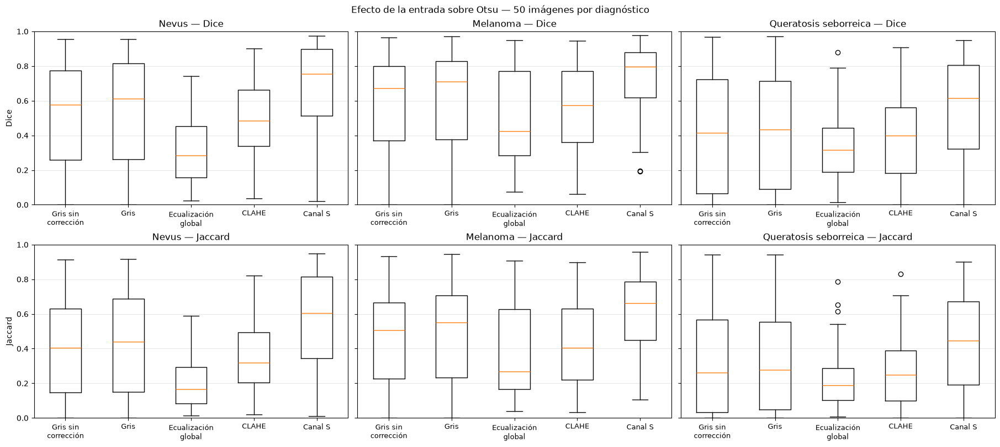

In [36]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]
etiquetas = [
    "Gris sin\ncorrección", "Gris", "Ecualización\nglobal", "CLAHE", "Canal S",
]

# Figura de 2 filas (Dice, Jaccard) x 3 columnas (diagnósticos).
fig, axes = plt.subplots(
    2, 3, figsize=(18, 8), sharey="row", constrained_layout=True
)

for columna, diagnostico in enumerate(diagnosticos):
    datos = resultados_entradas_otsu[
        resultados_entradas_otsu["Diagnóstico"] == diagnostico
    ]

    for fila, metrica in enumerate(["Dice", "Jaccard"]):
        # Un grupo de valores (50 imágenes) por entrada
        valores = [
            datos.loc[datos["Entrada"] == entrada, metrica]
            for entrada in orden_entradas
        ]

        ax = axes[fila, columna]
        ax.boxplot(valores)
        ax.set_xticks(range(1, len(orden_entradas) + 1))
        ax.set_xticklabels(etiquetas, fontsize=9)
        ax.set_ylim(0, 1)
        ax.set_title(f"{diagnostico} — {metrica}")
        ax.grid(axis="y", alpha=0.3)

        if columna == 0:
            ax.set_ylabel(metrica)

fig.suptitle("Efecto de la entrada sobre Otsu — 50 imágenes por diagnóstico")
plt.show()

#### Resultado del paso 1

**Corrección de artefactos:** Sobre la escala de grises, la corrección
mejora la segmentación en los tres diagnósticos: el Dice medio pasa de
0,584 a 0,611 en melanoma, de 0,514 a 0,533 en nevus y de 0,403 a 0,431
en queratosis seborreica, y el Dice mediano, de 0,672 a 0,711, de 0,577
a 0,612 y de 0,414 a 0,435, respectivamente. A nivel individual, mejora
el Dice en más de 0,01 en 55 de las 150 imágenes y lo empeora en 15.
La mejora es mayor en imágenes de alta resolución, como el ejemplo de
melanoma (de 0,519 a 0,580).

**Mejora de contraste:** Tanto CLAHE (Dice medio de 0,548, 0,487 y 0,386)
como la ecualización global (0,497, 0,326 y 0,336) empeoran la
segmentación respecto de la escala de grises sin ecualizar. Ambos
métodos realzan la textura de la piel, los pelos remanentes y los
artefactos, y generan numerosas regiones externas a la lesión, en
concordancia con la menor separación lesión-fondo observada en la
sección de contraste.

**Canal S:** El canal S presenta los mayores valores de Dice y Jaccard en los
tres diagnósticos: Dice medio de 0,729 en melanoma, 0,676 en nevus y
0,553 en queratosis seborreica, con medianas de 0,798, 0,755 y 0,617. A
nivel individual, supera a la escala de grises corregida en el 78 % de
las imágenes, lo que confirma la mayor separación lesión-fondo observada
para este canal en la sección de color.

En los ejemplos se observa una limitación de cada entrada: en escala de
grises se seleccionan las esquinas oscuras del campo del dermatoscopio,
mientras que en el canal S estas no se seleccionan, pero sí las manchas
pigmentadas fuera de la lesión. En el ejemplo de melanoma, el Dice del
canal S (0,523) es menor que el de la escala de grises (0,580). Por lo
tanto, la ventaja del canal S es general pero no se cumple en todas las
imágenes, y existe superposición entre las distribuciones. Estos
resultados son descriptivos y no se ha evaluado su significación
estadística.

Se selecciona el canal S de la imagen corregida como entrada para los pasos siguientes.

### Paso 2: refinamiento de las máscaras

Las máscaras obtenidas con Otsu presentan dos tipos de errores: pequeñas
regiones dispersas en la piel (textura, reflejos o artefactos remanentes)
y regiones externas de mayor tamaño, como las esquinas oscuras del campo
del dermatoscopio o manchas pigmentadas fuera de la lesión. Además, la
lesión puede quedar fragmentada o con huecos en zonas más claras de su
interior.

Para corregirlos se aplican tres etapas sucesivas, con los mismos
parámetros para todas las imágenes:

1. **Cierre y apertura morfológicos:** El cierre (elemento elíptico de
   9 × 9 píxeles) une regiones cercanas y rellena pequeñas discontinuidades
   de la lesión; la apertura (3 × 3) elimina puntos aislados.
2. **Selección de componentes:** Se etiquetan las regiones conectadas y se
   conserva la de mayor área, bajo el supuesto de que corresponde a la
   lesión principal. También se conservan las regiones cercanas a ella (a
   menos del 3 % del lado menor de la imagen) que tengan al menos el 10 %
   de su área, para no descartar partes de una lesión fragmentada.
3. **Relleno de huecos:** Se rellenan las regiones de fondo completamente
   encerradas por la lesión.

Cada etapa se evalúa por separado mediante Dice y Jaccard, para identificar
cuál aporta la mejora. El refinamiento se aplica sobre el canal S y, para
comparación, sobre la escala de grises.

In [37]:
def refinar_mascara_otsu(mascara):
    """
    Refina la máscara de Otsu en dos pasos:
    1) Morfología: cierre (9x9) para unir regiones cercanas y rellenar
       pequeños huecos, y apertura (3x3) para eliminar puntos aislados.
    2) Selección de componentes: se conserva la región conectada de
       mayor área y las regiones cercanas a ella que sean
       suficientemente grandes. Se supone que la lesión es la región
       principal y que lo demás son artefactos o piel.
    Devuelve la máscara después del paso 1 y después del paso 2.
    """
    kernel_apertura = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )
    kernel_cierre = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (9, 9)
    )

    cierre = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel_cierre
    )
    morfologica = cv2.morphologyEx(
        cierre, cv2.MORPH_OPEN, kernel_apertura
    )

    # Etiquetar las regiones conectadas (conectividad 8)
    # "propiedades" contiene el área de cada región
    cantidad, etiquetas, propiedades, _ = (
        cv2.connectedComponentsWithStats(
            morfologica, connectivity=8
        )
    )

    seleccionada = np.zeros_like(mascara)

    # Si no hay ninguna región blanca, se devuelve la máscara vacía
    if cantidad <= 1:
        return morfologica, seleccionada

    # Región de mayor área (se suma 1 porque se excluye el fondo)
    areas = propiedades[:, cv2.CC_STAT_AREA]
    mayor = 1 + np.argmax(areas[1:])
    componente_mayor = etiquetas == mayor

    # Distancia de cada píxel al componente mayor
    distancias = cv2.distanceTransform(
        (~componente_mayor).astype(np.uint8),
        cv2.DIST_L2, cv2.DIST_MASK_PRECISE
    )

    # Criterios iniciales iguales para todas las imágenes, relativos al
    # tamaño de la imagen y de la región principal:
    # - cercana: a menos del 3 % del lado menor de la imagen
    # - grande: al menos el 10 % del área del componente mayor
    distancia_maxima = 0.03 * min(mascara.shape)
    area_minima = 0.10 * areas[mayor]

    seleccionada[componente_mayor] = 255

    for etiqueta in range(1, cantidad):
        if etiqueta == mayor or areas[etiqueta] < area_minima:
            continue

        componente = etiquetas == etiqueta

        # Se incorpora si su punto más cercano está dentro de la distancia
        if distancias[componente].min() <= distancia_maxima:
            seleccionada[componente] = 255

    return morfologica, seleccionada

In [38]:
def rellenar_huecos(mascara):
    """
    Rellena los huecos encerrados dentro de la máscara (regiones negras
    rodeadas de blanco), como los que dejan zonas claras de la lesión.
    """
    # Agregar un borde negro para asegurar un fondo exterior conectado.
    ampliada = cv2.copyMakeBorder(
        mascara, 1, 1, 1, 1,
        cv2.BORDER_CONSTANT, value=0
    )

    # Pintar de blanco el fondo conectado al exterior.
    fondo = ampliada.copy()
    cv2.floodFill(fondo, None, (0, 0), 255)

    # Al invertir quedan blancos solo los huecos encerrados.
    huecos = cv2.bitwise_not(fondo)

    # Incorporar los huecos a la máscara y quitar el borde agregado.
    rellena = cv2.bitwise_or(ampliada, huecos)

    return rellena[1:-1, 1:-1]

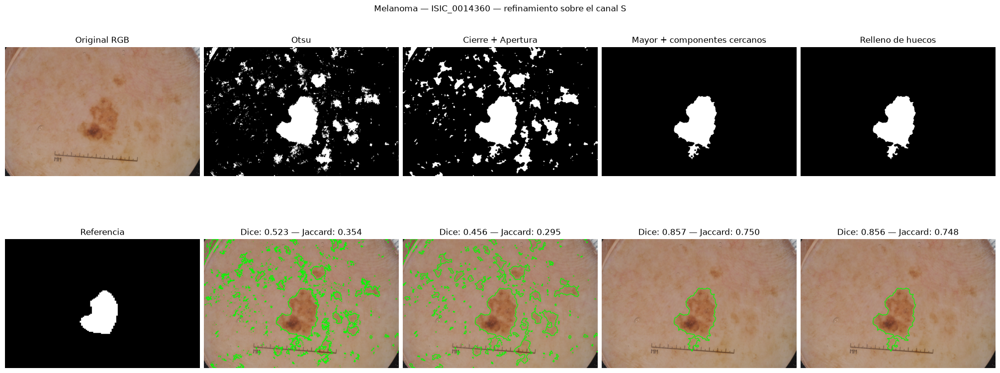

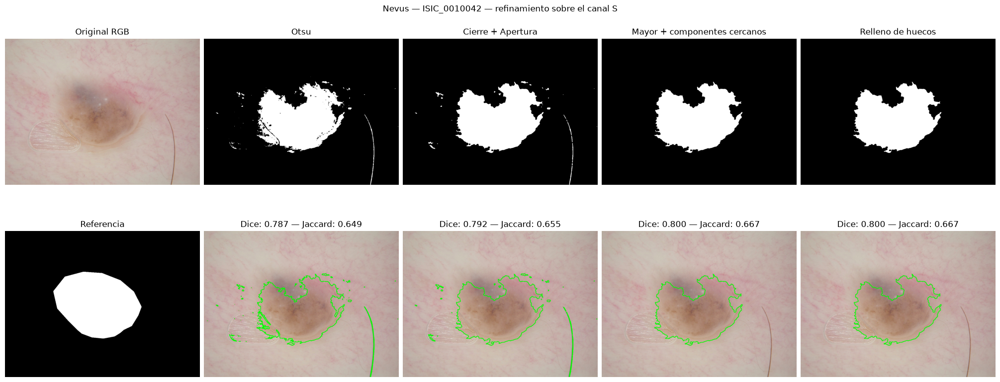

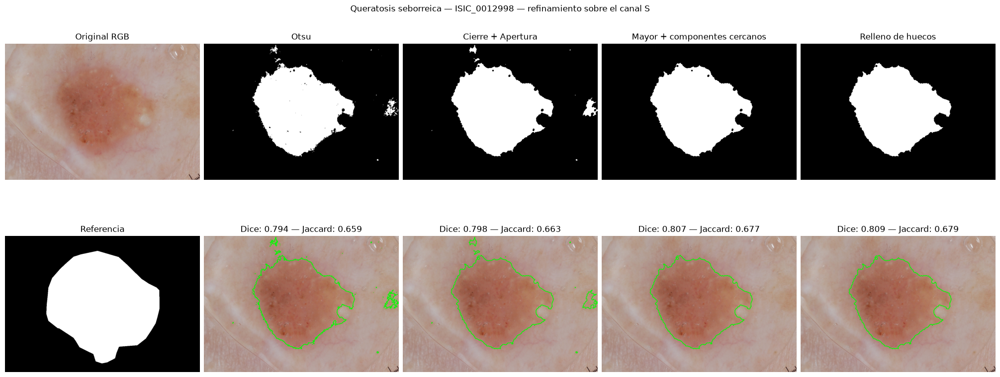

Dice_promedio  \
Entrada Diagnóstico           Etapa                                         
Gris    Melanoma              Otsu                                  0.611   
                              Cierre + Apertura                     0.622   
                              Mayor + componentes cercanos          0.627   
                              Relleno de huecos                     0.634   
        Nevus                 Otsu                                  0.533   
                              Cierre + Apertura                     0.533   
                              Mayor + componentes cercanos          0.538   
                              Relleno de huecos                     0.537   
        Queratosis seborreica Otsu                                  0.431   
                              Cierre + Apertura                     0.428   
                              Mayor + componentes cercanos          0.477   
                              Relleno de huecos                     0.475   
S       Melanoma              Otsu                                  0.729   
                              Cierre + Apertura                     0.730   
                              Mayor + componentes cercanos          0.779   
                              Relleno de huecos                     0.814   
        Nevus                 Otsu                                  0.676   
                              Cierre + Apertura                     0.679   
                              Mayor + componentes cercanos          0.651   
                              Relleno de huecos                     0.657   
        Queratosis seborreica Otsu                                  0.553   
                              Cierre + Apertura                     0.544   
                              Mayor + componentes cercanos          0.596   
                              Relleno de huecos                     0.600   

                                                            Dice_mediano  \
Entrada Diagnóstico           Etapa                                        
Gris    Melanoma              Otsu                                 0.711   
                              Cierre + Apertura                    0.709   
                              Mayor + componentes cercanos         0.811   
                              Relleno de huecos                    0.823   
        Nevus                 Otsu                                 0.612   
                              Cierre + Apertura                    0.624   
                              Mayor + componentes cercanos         0.745   
                              Relleno de huecos                    0.751   
        Queratosis seborreica Otsu                                 0.435   
                              Cierre + Apertura                    0.430   
                              Mayor + componentes cercanos         0.421   
                              Relleno de huecos                    0.387   
S       Melanoma              Otsu                                 0.798   
                              Cierre + Apertura                    0.821   
                              Mayor + componentes cercanos         0.841   
                              Relleno de huecos                    0.869   
        Nevus                 Otsu                                 0.755   
                              Cierre + Apertura                    0.747   
                              Mayor + componentes cercanos         0.850   
                              Relleno de huecos                    0.870   
        Queratosis seborreica Otsu                                 0.617   
                              Cierre + Apertura                    0.621   
                              Mayor + componentes cercanos         0.758   
                              Relleno de huecos                    0.773   

                                                            Jaccard_promedio  \


In [39]:
filas_refinamiento = []
ejemplos_refinamiento = {}

# El refinamiento se aplica a las dos entradas sin ecualizar: escala de
# grises (Otsu inverso) y canal S (Otsu directo)
entradas_refinamiento = {"Gris": True, "S": False}

for image_id, datos in datos_segmentacion.items():
    referencia = datos["Referencia"]

    for entrada, invertir in entradas_refinamiento.items():
        _, mascara_otsu = otsu(datos[entrada], invertir)

        morfologica, seleccionada = refinar_mascara_otsu(mascara_otsu)
        rellena = rellenar_huecos(seleccionada)

        # Etapas sucesivas del refinamiento
        variantes = {
            "Otsu": mascara_otsu,
            "Cierre + Apertura": morfologica,
            "Mayor + componentes cercanos": seleccionada,
            "Relleno de huecos": rellena,
        }

        for nombre, mascara in variantes.items():
            dice, jaccard = calcular_dice_jaccard(mascara, referencia)

            filas_refinamiento.append({
                "image_id": image_id,
                "Diagnóstico": datos["Diagnóstico"],
                "Entrada": entrada,
                "Etapa": nombre,
                "Dice": dice,
                "Jaccard": jaccard,
            })

        # Figura de los ejemplos, solo para el canal S
        if entrada == "S" and image_id in ids_ejemplo:
            ejemplos_refinamiento[image_id] = variantes

            fig, axes = plt.subplots(
                2, 5, figsize=(20, 8), constrained_layout=True
            )
            fig.suptitle(
                f"{datos['Diagnóstico']} — {image_id} — refinamiento sobre el canal S"
            )

            axes[0, 0].imshow(datos["RGB"])
            axes[0, 0].set_title("Original RGB")

            axes[1, 0].imshow(referencia, cmap="gray", vmin=0, vmax=255)
            axes[1, 0].set_title("Referencia")

            for columna, (nombre, mascara) in enumerate(
                variantes.items(), start=1
            ):
                dice, jaccard = calcular_dice_jaccard(mascara, referencia)

                axes[0, columna].imshow(mascara, cmap="gray", vmin=0, vmax=255)
                axes[0, columna].set_title(nombre)

                axes[1, columna].imshow(
                    contorno_sobre_imagen(datos["RGB"], mascara)
                )
                axes[1, columna].set_title(
                    f"Dice: {dice:.3f} — Jaccard: {jaccard:.3f}"
                )

            for ax in axes.ravel():
                ax.axis("off")

            plt.show()

resultados_refinamiento = pd.DataFrame(filas_refinamiento)

orden_etapas = [
    "Otsu", "Cierre + Apertura",
    "Mayor + componentes cercanos", "Relleno de huecos",
]

resumen_refinamiento = (
    resultados_refinamiento
    .groupby(["Entrada", "Diagnóstico", "Etapa"])
    .agg(
        Dice_promedio=("Dice", "mean"),
        Dice_mediano=("Dice", "median"),
        Jaccard_promedio=("Jaccard", "mean"),
        Jaccard_mediano=("Jaccard", "median"),
    )
    .reindex(orden_etapas, level="Etapa")
)

display(resumen_refinamiento.round(3))

#### Resultado del paso 2

Sobre el canal S, el cierre y la apertura producen cambios pequeños. La
mejora principal proviene de la selección de componentes, que elimina las
regiones externas a la lesión: el Dice mediano pasa de 0,798 a 0,841 en
melanoma, de 0,755 a 0,850 en nevus y de 0,617 a 0,758 en queratosis
seborreica. Con el relleno de huecos alcanza 0,869, 0,870 y 0,773,
respectivamente. El Dice medio final es de 0,814 en melanoma, 0,657 en
nevus y 0,600 en queratosis seborreica. El refinamiento completo mejora
el Dice en más de 0,01 en 106 de las 150 imágenes y lo empeora en 22.

En el ejemplo de melanoma, la selección de componentes elimina las
manchas pigmentadas externas y el Dice pasa de 0,523 a 0,856.

Sobre la escala de grises, el mismo refinamiento alcanza medianas de
0,823 en melanoma, 0,751 en nevus y 0,387 en queratosis seborreica,
inferiores a las del canal S, en especial en queratosis seborreica.

La diferencia entre medias y medianas indica que el método funciona bien
en la mayoría de las imágenes, pero falla marcadamente en algunas: con el
canal S refinado, 34 de las 150 imágenes presentan un Dice menor que 0,5.
Esto ocurre principalmente cuando la región de mayor área no corresponde
a la lesión o cuando la lesión queda fragmentada, ya que la selección
supone una única lesión principal. En el paso 3, este mismo refinamiento 
se aplica a todos los métodos comparados.

### Paso 3: comparación de métodos de segmentación

Se comparan cinco métodos de segmentación sobre las 150 imágenes, todos
aplicados sobre el canal S de la imagen corregida de artefactos y a la
resolución de trabajo (lado mayor de 1024 píxeles):

- **Umbral global fijo:** se utiliza el mismo umbral para todas las
  imágenes. Su valor se elige con el conjunto de ajuste de 30 imágenes,
  como el que maximiza el Dice medio.
- **Otsu:** el umbral se calcula automáticamente para cada imagen a
  partir de su histograma.
- **Canny:** se detectan los bordes de la imagen suavizada, se unen
  mediante un cierre morfológico y se rellenan las regiones encerradas.
  Los umbrales de histéresis se fijan a partir de la distribución del
  gradiente de cada imagen.
- **Crecimiento de regiones (Region Growing):** a partir de una semilla,
  se incorporan iterativamente los píxeles vecinos cuya saturación
  difiere de la media de la región en menos de una tolerancia. La
  semilla es el punto más interior de la máscara de Otsu refinada y la
  tolerancia se elige con el conjunto de ajuste.
- **Chan–Vese:** método de contornos activos. A diferencia de los
  métodos basados en umbrales, ajusta iterativamente un contorno que
  divide la imagen en dos regiones lo más homogéneas posible: en cada
  iteración, cada píxel se asigna a la región cuya intensidad media está
  más próxima a la suya, y luego el contorno se suaviza. Al no depender
  de bordes nítidos, puede resultar útil en lesiones con bordes poco
  definidos. Se inicializa con una elipse central (semiejes del 30 % del
  alto y del ancho) y se realizan 150 iteraciones con suavizado 2. Por
  ser iterativo, se aplica a 512 píxeles de lado mayor y la máscara se
  lleva luego a la resolución de trabajo. Como el método separa dos
  regiones sin indicar cuál es la lesión, se toma como lesión la región
  de mayor saturación media.

Para que la comparación refleje el criterio de cada método y no el
posprocesamiento, a todas las máscaras se les aplica el mismo
refinamiento definido en el paso 2: cierre y apertura, selección de
componentes y relleno de huecos.

Los parámetros que requieren ajuste (umbral fijo, percentil de Canny y
tolerancia del crecimiento de regiones) se eligen sobre las 30 imágenes
de ajuste, que no forman parte de la muestra de evaluación. Las máscaras
de referencia se utilizan únicamente para elegir estos parámetros en el
conjunto de ajuste y para evaluar los resultados.

In [40]:
def segmentar_chan_vese(gris, iteraciones=150, suavizado=2):
    """
    Aplica Chan–Vese morfológico sobre una imagen de un canal.
    La inicialización es una elipse central, sin usar la referencia.
    Devuelve una máscara binaria de valores 0 y 255.
    """
    alto, ancho = gris.shape

    # Grilla de coordenadas:
    y, x = np.ogrid[:alto, :ancho]

    # Contorno inicial: elipse centrada, con semiejes del 30 % del alto
    # y del ancho. Un píxel está dentro si cumple la ecuación de la
    # elipse: ((y - centro_y) / a)² + ((x - centro_x) / b)² <= 1
    inicial = (
        ((y - (alto - 1) / 2) / (0.30 * alto)) ** 2
        + ((x - (ancho - 1) / 2) / (0.30 * ancho)) ** 2
        <= 1
    )

    # Chan–Vese 
    # - num_iter: cantidad de iteraciones
    # - init_level_set: región inicial (la elipse)
    # - smoothing: cuántas veces se suaviza el contorno en cada iteración
    # - lambda1, lambda2: peso de la homogeneidad de la región interior y
    #   exterior; con valores iguales, ambas regiones pesan lo mismo
    resultado = morphological_chan_vese(
        gris.astype(np.float32) / 255.0,
        num_iter=iteraciones,
        init_level_set=inicial,
        smoothing=suavizado,
        lambda1=1,
        lambda2=1,
    )

    # El resultado es una matriz de 0 y 1: se pasa a 0 y 255
    return resultado.astype(np.uint8) * 255


def seleccionar_lesion(mascara):
    """
    Refinamiento final común a todos los métodos: cierre y apertura,
    selección de componentes y relleno de huecos (funciones definidas
    en el paso 2).
    """
    # refinar_mascara_otsu devuelve dos máscaras (después de la morfología
    # y después de la selección de componentes); se usa la segunda
    _, seleccionada = refinar_mascara_otsu(mascara)
    return rellenar_huecos(seleccionada)


def segmentar_umbral_fijo(canal, umbral):
    """Umbral global fijo: lesión = píxeles con saturación mayor al umbral."""
    _, mascara = cv2.threshold(canal, umbral, 255, cv2.THRESH_BINARY)
    return mascara


def segmentar_canny(canal, percentil=90):
    """
    Segmentación a partir de bordes de Canny.
    1) Suavizado gaussiano, para que el ruido no genere bordes.
    2) Umbrales de histéresis relativos a cada imagen: el umbral alto es
       el percentil indicado de la magnitud del gradiente y el bajo, la
       mitad. Así, los umbrales se adaptan al contraste de cada imagen.
    3) Cierre morfológico para unir los tramos de borde y relleno de las
       regiones que quedan encerradas.
    """
    # Suavizado gaussiano de 5x5 
    suavizado = cv2.GaussianBlur(canal, (5, 5), 0)

    # Magnitud del gradiente
    gx = cv2.Sobel(suavizado, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(suavizado, cv2.CV_32F, 0, 1, ksize=3)
    magnitud = np.abs(gx) + np.abs(gy)

    # Umbral alto: valor que supera solo el (100 - percentil) % de los
    # píxeles con mayor gradiente. Canny con histéresis conserva los
    # bordes por encima del umbral alto y los que, estando por encima del
    # bajo, están conectados a ellos
    umbral_alto = np.percentile(magnitud, percentil)
    bordes = cv2.Canny(suavizado, 0.5 * umbral_alto, umbral_alto)

    # El elemento de cierre es proporcional al tamaño de la imagen
    lado = max(3, round(0.015 * max(canal.shape)) | 1)
    kernel_cierre = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (lado, lado)
    )
    cerrados = cv2.morphologyEx(bordes, cv2.MORPH_CLOSE, kernel_cierre)

    # Las regiones encerradas por bordes pasan a formar parte de la máscara;
    # la apertura elimina los bordes sueltos que no encierran nada
    rellena = rellenar_huecos(cerrados)
    return cv2.morphologyEx(rellena, cv2.MORPH_OPEN, kernel_cierre)


def semilla_interior(mascara):
    """
    Punto más interior de una máscara: el píxel con mayor distancia al
    fondo. Se usa como semilla del crecimiento de regiones.
    """
    # distanceTransform asigna a cada píxel de la máscara su distancia al
    # píxel de fondo más cercano (DIST_L2: distancia euclidiana)
    distancias = cv2.distanceTransform(
        (mascara > 0).astype(np.uint8), cv2.DIST_L2, 5
    )

    # argmax da la posición del máximo en la matriz "aplanada";
    fila, columna = np.unravel_index(np.argmax(distancias), distancias.shape)
    return fila, columna


def crecer_region(canal, semilla, factor_tolerancia=1.0, max_iteraciones=3000):
    """
    Crecimiento de regiones con criterio de similitud a la media.
    En cada iteración se dilata la región (vecindad 8) y se incorporan
    los vecinos cuya saturación difiere de la media actual de la región
    en menos de la tolerancia. La tolerancia es factor_tolerancia veces
    el desvío de la imagen, para adaptarse al contraste de cada imagen.
    El proceso termina cuando no se incorporan píxeles nuevos.
    """
    # Se suaviza para que el ruido no detenga el crecimiento
    suavizado = cv2.GaussianBlur(canal, (5, 5), 0).astype(np.float32)
    tolerancia = factor_tolerancia * float(suavizado.std())

    # Región inicial: pequeño disco alrededor de la semilla, para que la
    # media inicial no dependa de un único píxel
    region = np.zeros(canal.shape, np.uint8)
    fila, columna = semilla
    radio = max(2, round(0.005 * max(canal.shape)))
    cv2.circle(region, (int(columna), int(fila)), radio, 1, -1)

    # Elemento de 3x3: la dilatación agrega los 8 vecinos de cada píxel
    kernel_vecindad = np.ones((3, 3), np.uint8)
    cantidad = int(region.sum())

    for _ in range(max_iteraciones):
        # Media actual de la región 
        media = cv2.mean(suavizado, region)[0]

        # Píxeles de toda la imagen cuyo valor es similar a la media
        similares = (np.abs(suavizado - media) <= tolerancia).astype(np.uint8)

        # Se incorporan solo los similares que son vecinos de la región:
        # dilatar la región y quedarse con la intersección con "similares"
        region = cv2.bitwise_or(
            region, cv2.bitwise_and(cv2.dilate(region, kernel_vecindad), similares)
        )

        # Si no se agregó ningún píxel, el crecimiento terminó
        nueva_cantidad = int(region.sum())
        if nueva_cantidad == cantidad:
            break
        cantidad = nueva_cantidad

    return region * 255


def segmentar_region_growing(canal, factor):
    """
    Crecimiento de regiones completo: la semilla es el punto más interior
    de la máscara de Otsu refinada, y desde ella se hace crecer la región
    con la tolerancia indicada.
    """
    _, mascara_otsu = otsu(canal, invertir=False)
    semilla = semilla_interior(seleccionar_lesion(mascara_otsu))
    return crecer_region(canal, semilla, factor)


def segmentar_chan_vese_s(canal, lado_maximo=512, iteraciones=150, suavizado=2):
    """
    Chan–Vese sobre el canal S, a lado_maximo píxeles de lado mayor.
    Se reutiliza segmentar_chan_vese y se toma como lesión la región de
    mayor saturación media. La máscara se devuelve al tamaño de entrada.
    """
    alto, ancho = canal.shape
    reducido = reducir_lado_mayor(canal, lado_maximo)
    mascara = segmentar_chan_vese(reducido, iteraciones, suavizado)

    # Chan–Vese separa dos regiones, pero no indica cuál es la lesión. Como
    # en el canal S la lesión es más saturada que la piel, si la región
    # marcada (blanca) tiene menor saturación media que el resto, se invierte
    dentro = mascara > 0
    if dentro.any() and (~dentro).any():
        if reducido[dentro].mean() < reducido[~dentro].mean():
            mascara = 255 - mascara

    # Volver al tamaño de entrada sin generar valores intermedios
    return cv2.resize(mascara, (ancho, alto), interpolation=cv2.INTER_NEAREST)

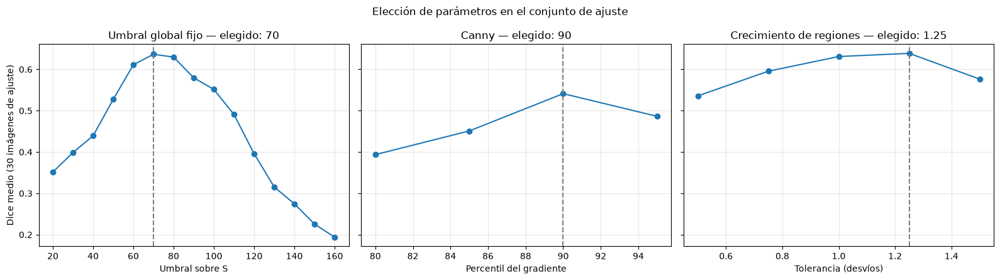

Umbral fijo elegido: 70 (Dice medio 0.637)
Percentil de Canny elegido: 90 (Dice medio 0.541)
Tolerancia elegida: 1.25 desvíos (Dice medio 0.639)


In [41]:
# Preparar el conjunto de ajuste igual que la muestra de evaluación:
# resolución de trabajo, corrección de artefactos y canal S.
# Son las mismas 30 imágenes usadas para elegir los parámetros de la
# corrección de pelos, que no forman parte de la muestra de 150
datos_ajuste = {}

for _, registro in df_ajuste.iterrows():
    image_id = registro["image_id"]

    imagen = cv2.imread(str(rutas[image_id]))
    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )
    original = reducir_lado_mayor(
        cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), lado_trabajo
    )
    alto, ancho = original.shape[:2]

    corregida, _ = corregir_artefactos(
        original, tamanio_kernel=tamanio_elegido, umbral=umbral_elegido,
        refinamiento="Solo cierre", lado_trabajo=lado_trabajo
    )

    # Se guardan solo el canal S y la referencia reducida
    datos_ajuste[image_id] = {
        "S": cv2.cvtColor(corregida, cv2.COLOR_RGB2HSV)[:, :, 1],
        "Referencia": cv2.resize(
            referencia, (ancho, alto), interpolation=cv2.INTER_NEAREST
        ),
    }


def dice_medio_ajuste(segmentar):
    """
    Dice medio en el conjunto de ajuste para una función de segmentación.
    A cada máscara se le aplica el mismo refinamiento final que en la
    comparación, para elegir los parámetros en las mismas condiciones.
    """
    valores = [
        calcular_dice_jaccard(seleccionar_lesion(segmentar(d["S"])), d["Referencia"])[0]
        for d in datos_ajuste.values()
    ]
    return np.mean(valores)


# Para cada parámetro se prueba una lista de valores y se guarda el Dice
# medio de cada uno en un diccionario 

# 1) Umbral global fijo: de 20 a 160, de 10 en 10
umbrales_fijos = list(range(20, 161, 10))
dice_umbral = {
    u: dice_medio_ajuste(lambda s, u=u: segmentar_umbral_fijo(s, u))
    for u in umbrales_fijos
}

# 2) Percentil del gradiente para el umbral alto de Canny
percentiles = [80, 85, 90, 95]
dice_canny = {
    p: dice_medio_ajuste(lambda s, p=p: segmentar_canny(s, p))
    for p in percentiles
}

# 3) Tolerancia del crecimiento de regiones
factores = [0.5, 0.75, 1.0, 1.25, 1.5]
dice_region = {
    f: dice_medio_ajuste(lambda s, f=f: segmentar_region_growing(s, f))
    for f in factores
}

# Valor elegido: el de mayor Dice medio 
umbral_fijo_elegido = max(dice_umbral, key=dice_umbral.get)
percentil_elegido = max(dice_canny, key=dice_canny.get)
factor_elegido = max(dice_region, key=dice_region.get)

# Figura: Dice medio en función de cada parámetro; la línea punteada
# marca el valor elegido
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (titulo, resultados, elegido, etiqueta) in zip(axes, [
    ("Umbral global fijo", dice_umbral, umbral_fijo_elegido, "Umbral sobre S"),
    ("Canny", dice_canny, percentil_elegido, "Percentil del gradiente"),
    ("Crecimiento de regiones", dice_region, factor_elegido, "Tolerancia (desvíos)"),
]):
    ax.plot(list(resultados), list(resultados.values()), marker="o")
    ax.axvline(elegido, color="gray", linestyle="--")
    ax.set_title(f"{titulo} — elegido: {elegido}")
    ax.set_xlabel(etiqueta)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Dice medio (30 imágenes de ajuste)")
fig.suptitle("Elección de parámetros en el conjunto de ajuste")
plt.tight_layout()
plt.show()

print(f"Umbral fijo elegido: {umbral_fijo_elegido} (Dice medio {dice_umbral[umbral_fijo_elegido]:.3f})")
print(f"Percentil de Canny elegido: {percentil_elegido} (Dice medio {dice_canny[percentil_elegido]:.3f})")
print(f"Tolerancia elegida: {factor_elegido} desvíos (Dice medio {dice_region[factor_elegido]:.3f})")

#### Resultado de la elección de parámetros

En el conjunto de ajuste se eligieron un umbral fijo de 70 sobre el canal S (Dice medio de 0,637), el percentil 90 de la magnitud del gradiente como umbral alto de Canny (0,541) y una tolerancia de 1,25 desvíos para el crecimiento de regiones (0,639). Estos valores se utilizan sin cambios en la muestra de evaluación.

In [42]:
# Aplicar los cinco métodos a las 150 imágenes, con los parámetros elegidos.
# Cada método es una función que recibe el canal S y devuelve una máscara.
metodos = {
    "Umbral fijo": lambda s: segmentar_umbral_fijo(s, umbral_fijo_elegido),
    "Otsu": lambda s: otsu(s, invertir=False)[1],
    "Canny": lambda s: segmentar_canny(s, percentil_elegido),
    "Region Growing": lambda s: segmentar_region_growing(s, factor_elegido),
    "Chan–Vese": segmentar_chan_vese_s,
}

filas_metodos = []

# Se guardan todas las máscaras: mascaras_metodos[método][image_id].
# Se usan en la figura de contornos y en la extracción de características
mascaras_metodos = {nombre: {} for nombre in metodos}

# Se trabaja sobre el canal S ya preparado (resolución de trabajo y
# corrección de artefactos), sin volver a leer las imágenes.
for numero, (image_id, datos) in enumerate(datos_segmentacion.items(), start=1):
    for nombre, segmentar in metodos.items():
        # Segmentación seguida del refinamiento común a todos los métodos
        mascara = seleccionar_lesion(segmentar(datos["S"]))
        dice, jaccard = calcular_dice_jaccard(mascara, datos["Referencia"])

        mascaras_metodos[nombre][image_id] = mascara
        filas_metodos.append({
            "image_id": image_id,
            "Diagnóstico": datos["Diagnóstico"],
            "Método": nombre,
            "Dice": dice,
            "Jaccard": jaccard,
        })

    # Mensaje de avance cada 50 imágenes
    if numero % 50 == 0:
        print(f"Procesadas {numero}/{len(datos_segmentacion)} imágenes", flush=True)

resultados_metodos = pd.DataFrame(filas_metodos)
orden_metodos = list(metodos)

# Resumen por diagnóstico y método. "Fallas" cuenta las imágenes con
# Dice menor que 0,5, es decir, segmentaciones claramente incorrectas
resumen_metodos = (
    resultados_metodos
    .groupby(["Diagnóstico", "Método"])
    .agg(
        Dice_promedio=("Dice", "mean"),
        Dice_mediano=("Dice", "median"),
        Jaccard_promedio=("Jaccard", "mean"),
        Jaccard_mediano=("Jaccard", "median"),
        Fallas_Dice_menor_05=("Dice", lambda x: int((x < 0.5).sum())),
    )
    .reindex(orden_metodos, level="Método")
)
display(resumen_metodos.round(3))

# Resumen global (150 imágenes)
resumen_global = (
    resultados_metodos
    .groupby("Método")
    .agg(
        Dice_promedio=("Dice", "mean"),
        Dice_mediano=("Dice", "median"),
        Jaccard_promedio=("Jaccard", "mean"),
        Fallas_Dice_menor_05=("Dice", lambda x: int((x < 0.5).sum())),
    )
    .reindex(orden_metodos)
)
display(resumen_global.round(3))

Procesadas 50/150 imágenes
Procesadas 100/150 imágenes
Procesadas 150/150 imágenes


Dice_promedio  Dice_mediano  \
Diagnóstico           Método                                        
Melanoma              Umbral fijo             0.678         0.845   
                      Otsu                    0.814         0.869   
                      Canny                   0.628         0.730   
                      Region Growing          0.690         0.799   
                      Chan–Vese               0.811         0.864   
Nevus                 Umbral fijo             0.529         0.568   
                      Otsu                    0.657         0.870   
                      Canny                   0.427         0.319   
                      Region Growing          0.565         0.740   
                      Chan–Vese               0.655         0.855   
Queratosis seborreica Umbral fijo             0.517         0.590   
                      Otsu                    0.600         0.773   
                      Canny                   0.345         0.326   
                      Region Growing          0.530         0.613   
                      Chan–Vese               0.672         0.803   

                                      Jaccard_promedio  Jaccard_mediano  \
Diagnóstico           Método                                              
Melanoma              Umbral fijo                0.583            0.732   
                      Otsu                       0.714            0.768   
                      Canny                      0.527            0.575   
                      Region Growing             0.587            0.665   
                      Chan–Vese                  0.709            0.760   
Nevus                 Umbral fijo                0.444            0.397   
                      Otsu                       0.589            0.769   
                      Canny                      0.342            0.190   
                      Region Growing             0.477            0.588   
                      Chan–Vese                  0.583            0.746   
Queratosis seborreica Umbral fijo                0.422            0.419   
                      Otsu                       0.512            0.630   
                      Canny                      0.252            0.195   
                      Region Growing             0.445            0.442   
                      Chan–Vese                  0.574            0.671   

                                      Fallas_Dice_menor_05  
Diagnóstico           Método                                
Melanoma              Umbral fijo                       15  
                      Otsu                               3  
                      Canny                             18  
                      Region Growing                    14  
                      Chan–Vese                          4  
Nevus                 Umbral fijo                       24  
                      Otsu                              13  
                      Canny                             28  
                      Region Growing                    17  
                      Chan–Vese                         13  
Queratosis seborreica Umbral fijo                       22  
                      Otsu                              18  
                      Canny                             37  
                      Region Growing                    22  
                      Chan–Vese                         15

,Dice_promedio,Dice_mediano,Jaccard_promedio,Fallas_Dice_menor_05
Método,,,,
Umbral fijo,0.575,0.636,0.483,61
Otsu,0.690,0.839,0.605,34
Canny,0.467,0.459,0.374,83
Region Growing,0.595,0.738,0.503,53
Chan–Vese,0.713,0.850,0.622,32


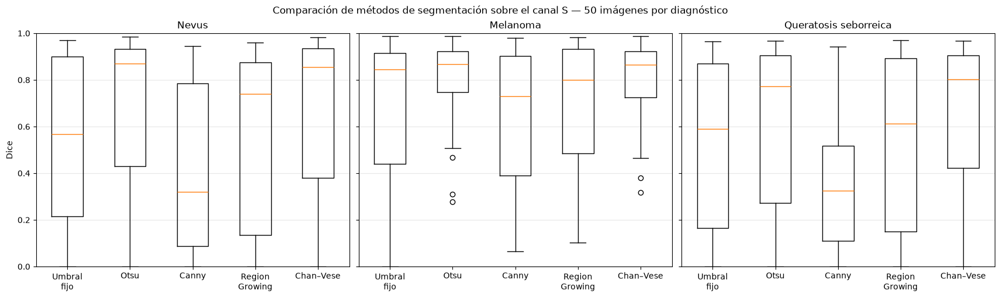

,"Mejora a Otsu (>0,01)","Empeora (<-0,01)",Diferencia mediana,p (Wilcoxon)
Método,,,,
Umbral fijo,49,81,-0.0180,0.0002
Canny,33,99,-0.1158,0.0000
Region Growing,39,87,-0.0306,0.0000
Chan–Vese,50,29,0.0007,0.0398


In [43]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

# Diagramas de caja del Dice de cada método, uno por diagnóstico
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True, constrained_layout=True)

for ax, diagnostico in zip(axes, diagnosticos):
    datos = resultados_metodos[resultados_metodos["Diagnóstico"] == diagnostico]
    ax.boxplot([datos.loc[datos["Método"] == m, "Dice"] for m in orden_metodos])
    ax.set_xticks(range(1, len(orden_metodos) + 1))
    ax.set_xticklabels([m.replace(" ", "\n") for m in orden_metodos])
    ax.set_ylim(0, 1)
    ax.set_title(diagnostico)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Dice")
fig.suptitle("Comparación de métodos de segmentación sobre el canal S — 50 imágenes por diagnóstico")
plt.show()

# Comparación imagen por imagen de cada método con Otsu (método de
# referencia de los pasos anteriores). Como los dos métodos se aplican a
# las mismas imágenes, se comparan sus Dice de a pares.
# Prueba de rangos con signo de Wilcoxon: no supone distribución normal y
# evalúa si las diferencias pareadas se distribuyen simétricamente
# alrededor de 0. Un p menor que 0,05 indica que la diferencia entre los
# métodos no se explica por azar
dice_por_imagen = resultados_metodos.pivot(index="image_id", columns="Método", values="Dice")
filas_pareadas = []
for metodo in orden_metodos:
    if metodo == "Otsu":
        continue
    diferencia = dice_por_imagen[metodo] - dice_por_imagen["Otsu"]
    filas_pareadas.append({
        "Método": metodo,
        "Mejora a Otsu (>0,01)": int((diferencia > 0.01).sum()),
        "Empeora (<-0,01)": int((diferencia < -0.01).sum()),
        "Diferencia mediana": diferencia.median(),
        "p (Wilcoxon)": wilcoxon(dice_por_imagen[metodo], dice_por_imagen["Otsu"]).pvalue,
    })
display(pd.DataFrame(filas_pareadas).set_index("Método").round(4))

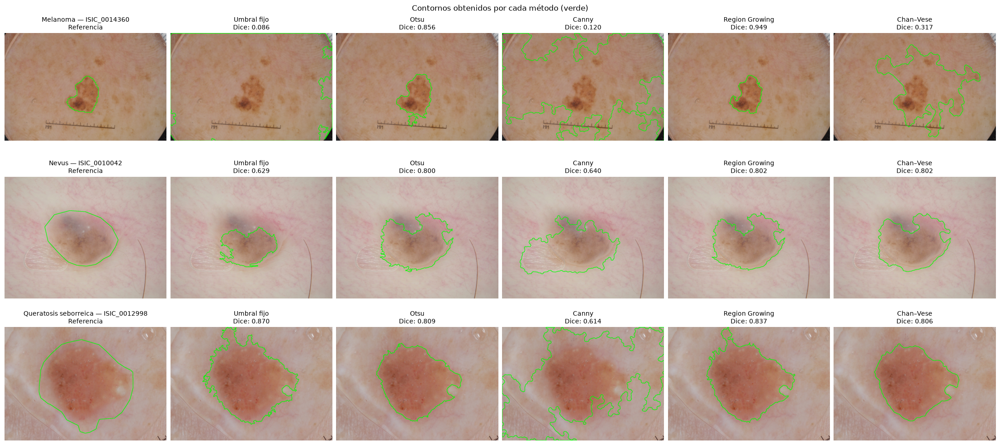

In [44]:
# Contornos de los cinco métodos en el ejemplo de cada diagnóstico
ids_ejemplo_muestra = list(ejemplos["image_id"])

fig, axes = plt.subplots(
    len(ids_ejemplo_muestra), len(orden_metodos) + 1,
    figsize=(22, 10), constrained_layout=True
)

for fila, image_id in enumerate(ids_ejemplo_muestra):
    datos = datos_segmentacion[image_id]
    rgb = datos["RGB"]

    # Primera columna: referencia
    axes[fila, 0].imshow(contorno_sobre_imagen(rgb, datos["Referencia"]))
    axes[fila, 0].set_title(f"{datos['Diagnóstico']} — {image_id}\nReferencia", fontsize=10)

    for columna, metodo in enumerate(orden_metodos, start=1):
        mascara = mascaras_metodos[metodo][image_id]
        dice, _ = calcular_dice_jaccard(mascara, datos["Referencia"])
        axes[fila, columna].imshow(contorno_sobre_imagen(rgb, mascara))
        axes[fila, columna].set_title(f"{metodo}\nDice: {dice:.3f}", fontsize=10)

for ax in axes.ravel():
    ax.axis("off")

fig.suptitle("Contornos obtenidos por cada método (verde)")
plt.show()

#### Resultado de la comparación de métodos

En las 150 imágenes, Chan–Vese y Otsu obtienen los mejores resultados,
con desempeños muy similares: Dice medio de 0,713 y 0,690, Dice mediano
de 0,850 y 0,839, y Jaccard medio de 0,622 y 0,605, respectivamente. Con
Chan–Vese, 32 de las 150 imágenes presentan un Dice menor que 0,5, frente
a 34 con Otsu.

La diferencia entre ambos depende del diagnóstico. En melanoma y nevus
son prácticamente equivalentes (Dice medio de 0,811 y 0,814 en melanoma;
0,655 y 0,657 en nevus). En queratosis seborreica, Chan–Vese mejora el
Dice medio de 0,600 a 0,672 y el mediano de 0,773 a 0,803. Una posible
explicación es que, en estas lesiones, la saturación de la lesión y de la
piel no forma dos grupos bien separados en el histograma, que es lo que
requiere Otsu, mientras que Chan–Vese compara las intensidades dentro y
fuera del contorno y tiene en cuenta la continuidad espacial de la región.
En la comparación pareada, Chan–Vese mejora el Dice de Otsu en más de
0,01 en 50 imágenes y lo empeora en 29 (prueba de Wilcoxon, p = 0,040),
aunque la diferencia mediana es prácticamente nula.

Los métodos restantes presentan un desempeño inferior:

- **Umbral global fijo** (Dice medio de 0,575): un único umbral no se
  adapta a las diferencias de iluminación y saturación entre imágenes,
  lo que confirma la ventaja de calcular el umbral para cada imagen,
  como hace Otsu.
- **Crecimiento de regiones** (0,595): la región se detiene en zonas
  internas de la lesión con saturación distinta de la media, o se
  extiende hacia la piel cuando el borde es gradual. Aunque parte de la
  semilla obtenida con Otsu, empeora su resultado en 87 imágenes.
- **Canny** (0,467): en el canal S los bordes de la lesión suelen ser
  graduales y aparecen fragmentados, mientras que la textura interna y
  los artefactos generan bordes adicionales. El cierre morfológico no
  logra formar un contorno cerrado en muchas imágenes, lo que produce
  83 fallas.

Como desventajas, Chan–Vese es considerablemente más lento (varios
segundos por imagen a 512 píxeles, frente a milésimas de segundo de
Otsu), y en 3 imágenes la máscara final abarca toda la imagen (Otsu
presenta la misma falla en 2 imágenes). Como mejora posible, este tipo de
falla podría detectarse automáticamente, por ejemplo descartando las
máscaras que superen cierta fracción de la imagen, y reemplazarse por el
resultado de otro método.

Se selecciona **Chan–Vese sobre el canal S, con el refinamiento final**,
como método de segmentación para la extracción de características, por
presentar el mayor Dice medio y mediano, el menor número de fallas y el
mejor desempeño en queratosis seborreica.

## Extracción de características

Se extraen características morfológicas, de color y de textura de las 150 lesiones de la muestra. Cada característica se calcula dos veces:

- con la **máscara de referencia**, que delimita la lesión según los especialistas y permite estudiar las diferencias entre diagnósticos sin el error de la segmentación;
- con la **máscara automática** obtenida por el método elegido, que representa el resultado del algoritmo completo.

La comparación entre ambas permite evaluar cómo influye la segmentación sobre las mediciones.

Todas las mediciones se realizan a la resolución de trabajo (lado mayor
de 1024 píxeles). Como el dataset no informa la escala física de las
imágenes (milímetros por píxel), se priorizan características de forma
adimensionales, que no dependen del tamaño de la imagen. El color y la
textura se calculan sobre la imagen original, sin corrección de
artefactos, para no incorporar valores estimados por el inpainting.

Las imágenes de ISIC 2017 provienen de distintos centros y
dermatoscopios, y la resolución original depende del diagnóstico. Como
el equipo de adquisición influye en el color y la nitidez de la imagen,
algunas características podrían reflejar el origen de la fotografía y no
solo la lesión. Este efecto se evalúa al final de la sección, y el
análisis estadístico se repite controlando el origen de las imágenes.

La elección de las características se basa en la **regla ABCD de la dermatoscopía** (Stolz et al., 1994), un criterio clínico que utilizan los dermatólogos para estimar la probabilidad de que una lesión pigmentada sea un melanoma. La regla evalúa cuatro aspectos de la lesión:

- **A — Asimetría:** los melanomas suelen ser asimétricos en forma, color o estructura, mientras que los nevus benignos tienden a ser simétricos.
- **B — Borde:** los melanomas suelen tener bordes irregulares o con cortes abruptos.
- **C — Color:** la presencia de varios colores (marrón claro y oscuro, negro, azul grisáceo, rojo, blanco) se asocia a malignidad.
- **D — Estructuras diferenciales:** patrones internos como retículos, puntos, glóbulos o áreas sin estructura.

En este trabajo, la asimetría se relaciona con el criterio A; la circularidad, la solidez y la convexidad, con el criterio B; la heterogeneidad y los desvíos de color, con el criterio C; y los parámetros de textura, de forma aproximada, con el criterio D, ya que describen la organización de las intensidades dentro de la lesión. Las características calculadas no reproducen la regla clínica, sino que buscan cuantificar automáticamente los aspectos que esta evalúa.

In [45]:
# Método de segmentación elegido en la comparación anterior
metodo_final = "Chan–Vese"
mascaras_automaticas = mascaras_metodos[metodo_final]

# Imágenes originales (sin corrección de artefactos) a la resolución de
# trabajo, para medir color y textura
imagenes_trabajo = {}
for image_id in datos_segmentacion:
    imagen = cv2.imread(str(rutas[image_id]))
    imagenes_trabajo[image_id] = reducir_lado_mayor(
        cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), lado_trabajo
    )

print(f"Método final: {metodo_final}")
print(f"Imágenes cargadas: {len(imagenes_trabajo)}")

Método final: Chan–Vese
Imágenes cargadas: 150


### Características morfológicas

A partir de cada máscara binaria se calculan:

- **Área relativa:** porcentaje de la imagen ocupado por la lesión. Depende del encuadre y de la ampliación del dermatoscopio, por lo que se informa a modo descriptivo.
- **Circularidad:** 4π·Área / Perímetro². Vale 1 para un círculo y disminuye cuanto más irregular o alargado es el contorno.
- **Solidez:** área de la lesión dividida por el área de su envolvente convexa. Valores menores indican concavidades en el borde.
- **Convexidad:** perímetro de la envolvente convexa dividido por el perímetro de la lesión. Disminuye cuando el borde es dentado o irregular.
- **Relación de ejes:** cociente entre el eje menor y el eje mayor de la elipse con los mismos momentos de segundo orden. Vale 1 para una lesión sin orientación preferencial y se acerca a 0 en lesiones alargadas.
- **Asimetría:** la lesión se alinea con sus ejes principales mediante los momentos de la imagen y se refleja respecto de cada eje. La asimetría respecto de un eje es el área que no se superpone con su reflejo, dividida por el doble del área de la lesión (0 = simétrica). Se informan la asimetría respecto de cada eje y su promedio, en línea con el criterio A de la regla ABCD.

Salvo el área relativa, todas son adimensionales.

In [46]:
def asimetria_ejes(mascara):
    """
    Asimetría respecto de los dos ejes principales de la lesión.
    1) Se calculan el centroide y la orientación del eje mayor a partir
       de los momentos de la máscara.
    2) Se rota la máscara para alinear el eje mayor con la horizontal y
       se ubica el centroide en el centro de un lienzo cuadrado.
    3) Se refleja la máscara alineada respecto de cada eje y se mide el
       área que no se superpone con el reflejo (XOR), dividida por el
       doble del área. Resultado: 0 = simétrica, 1 = sin superposición.
    """
    binaria = (mascara > 0).astype(np.uint8)
    momentos = cv2.moments(binaria, binaryImage=True)
    cx = momentos["m10"] / momentos["m00"]
    cy = momentos["m01"] / momentos["m00"]

    # Ángulo del eje mayor respecto de la horizontal, en grados
    angulo = 0.5 * np.degrees(
        np.arctan2(2 * momentos["mu11"], momentos["mu20"] - momentos["mu02"])
    )

    # Lienzo cuadrado que contiene la lesión rotada en cualquier ángulo
    lado = int(np.ceil(np.hypot(*binaria.shape))) | 1
    centro = (lado - 1) / 2

    rotacion = cv2.getRotationMatrix2D((cx, cy), angulo, 1.0)
    rotacion[0, 2] += centro - cx
    rotacion[1, 2] += centro - cy
    alineada = cv2.warpAffine(
        binaria, rotacion, (lado, lado), flags=cv2.INTER_NEAREST
    ).astype(bool)

    area = alineada.sum()
    # np.flipud refleja respecto del eje horizontal (eje mayor) y
    # np.fliplr respecto del eje vertical (eje menor)
    asimetria_mayor = np.count_nonzero(alineada ^ np.flipud(alineada)) / (2 * area)
    asimetria_menor = np.count_nonzero(alineada ^ np.fliplr(alineada)) / (2 * area)
    return asimetria_mayor, asimetria_menor


def caracteristicas_morfologicas(mascara):
    """Características de forma a partir de una máscara binaria (255 = lesión)."""
    binaria = (mascara > 0).astype(np.uint8)
    area = float(binaria.sum())

    contornos, _ = cv2.findContours(
        binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )
    # El contorno de píxeles tiene forma escalonada, lo que sobreestima el
    # perímetro. Se aproxima con un polígono de tolerancia 1 píxel
    contornos = [cv2.approxPolyDP(c, 1.0, True) for c in contornos]
    perimetro = sum(cv2.arcLength(c, True) for c in contornos)

    # Envolvente convexa de todos los puntos del contorno. Su área se mide
    # contando píxeles, igual que el área de la lesión
    envolvente = cv2.convexHull(np.vstack(contornos))
    area_convexa = float(cv2.fillPoly(np.zeros_like(binaria), [envolvente], 1).sum())
    perimetro_convexo = cv2.arcLength(envolvente, True)

    # Ejes de la elipse equivalente: autovalores de la matriz de momentos
    # centrales normalizados (covarianza de las coordenadas)
    momentos = cv2.moments(binaria, binaryImage=True)
    covarianza = np.array([
        [momentos["mu20"], momentos["mu11"]],
        [momentos["mu11"], momentos["mu02"]],
    ]) / momentos["m00"]
    autovalores = np.sort(np.linalg.eigvalsh(covarianza))

    asimetria_mayor, asimetria_menor = asimetria_ejes(mascara)

    return {
        "Área relativa (%)": 100 * area / binaria.size,
        "Circularidad": 4 * np.pi * area / perimetro ** 2,
        "Solidez": area / area_convexa,
        "Convexidad": perimetro_convexo / perimetro,
        "Relación de ejes": np.sqrt(autovalores[0] / autovalores[1]),
        "Asimetría eje mayor": asimetria_mayor,
        "Asimetría eje menor": asimetria_menor,
        "Asimetría media": (asimetria_mayor + asimetria_menor) / 2,
    }


# Verificación con figuras sintéticas de propiedades conocidas
lienzo = np.zeros((400, 400), np.uint8)
circulo = cv2.circle(lienzo.copy(), (200, 200), 100, 255, -1)
elipse = cv2.ellipse(lienzo.copy(), (200, 200), (150, 60), 30, 0, 360, 255, -1)
gota = cv2.circle(lienzo.copy(), (160, 200), 80, 255, -1)
gota = cv2.circle(gota, (260, 200), 40, 255, -1)
gota = cv2.circle(gota, (200, 140), 30, 255, -1)

display(pd.DataFrame({
    "Círculo": caracteristicas_morfologicas(circulo),
    "Elipse rotada 30°": caracteristicas_morfologicas(elipse),
    "Figura asimétrica": caracteristicas_morfologicas(gota),
}).round(3))

,Círculo,Elipse rotada 30°,Figura asimétrica
Área relativa (%),19.636,17.859,15.831
Circularidad,1.004,0.752,0.755
Solidez,0.999,1.001,0.936
Convexidad,1.000,1.000,0.927
Relación de ejes,1.000,0.402,0.732
Asimetría eje mayor,0.000,0.003,0.092
Asimetría eje menor,0.000,0.003,0.158
Asimetría media,0.000,0.003,0.125


La verificación con figuras sintéticas confirma el comportamiento esperado:

- el círculo presenta circularidad, solidez, convexidad y relación de ejes iguales a 1 y asimetría nula;
- en la elipse rotada 30°, la asimetría es prácticamente nula, ya que la alineación por momentos compensa la rotación. Su relación de ejes coincide con el cociente de sus semiejes (60/150 = 0,40) y su circularidad (0,75) se aproxima al valor teórico de una elipse con esos semiejes (0,745);
- la figura asimétrica presenta mayor asimetría y menores solidez y convexidad, por las concavidades entre sus partes.

### Características de color y textura

**Color.** Dentro de la lesión se calculan la media y el desvío estándar de los canales R, G y B, y la media del canal S. No se incluye la media de V porque en estas imágenes coincide prácticamente con la del canal R (V toma el máximo de los tres canales, que en la piel y en la lesión suele ser el rojo). Además se calculan:

- **Heterogeneidad de color:** dispersión de los colores de la lesión en el espacio CIELAB. Este espacio describe cada color con tres valores: L\* (luminosidad, de negro a blanco), a\* (de verde a rojo) y b\* (de azul a amarillo). A diferencia de RGB, es aproximadamente uniforme desde el punto de vista perceptual: la distancia entre dos colores se aproxima a la diferencia que percibe el ojo humano. La heterogeneidad se calcula como la raíz de la suma de las varianzas de L\*, a\* y b\* dentro de la lesión. Valores mayores indican lesiones con colores más variados, en línea con el criterio C de la regla ABCD.
- **Contraste lesión–piel:** diferencia relativa entre el valor V medio de la piel perilesional y el de la lesión, (V_piel − V_lesión) / V_piel. La piel perilesional se define como un anillo alrededor de la lesión, de ancho igual al 3 % del lado mayor de la imagen. Al ser relativo, reduce la influencia de la iluminación de cada imagen.

**Textura.** Se calculan matrices de coocurrencia de niveles de gris (GLCM) dentro de la lesión. La escala de grises se cuantifica en 32 niveles (1 a 32) y los píxeles fuera de la lesión se marcan con el nivel 0, que luego se descarta, de forma que solo se cuentan pares de píxeles pertenecientes a la lesión. Se utilizan distancias de 1 y 3 píxeles y cuatro orientaciones (0°, 45°, 90° y 135°); los parámetros se promedian entre orientaciones para que no dependan de la orientación de la lesión. Se calculan:

- **Contraste:** variación de intensidad entre píxeles vecinos.
- **Homogeneidad:** proximidad de los pares a la diagonal de la matriz (vecinos con niveles similares).
- **Energía:** uniformidad de la distribución de pares; es alta cuando predominan pocas combinaciones.
- **Correlación:** dependencia lineal entre los niveles de píxeles vecinos.

In [47]:
niveles_glcm = 32
distancias_glcm = [1, 3]
angulos_glcm = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]


def caracteristicas_color(rgb, mascara):
    """Color dentro de la lesión y contraste con la piel perilesional."""
    lesion = (mascara > 0).astype(np.uint8)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    # Píxeles de la lesión, uno por fila
    pixeles_rgb = rgb[lesion > 0].astype(np.float64)
    pixeles_hsv = hsv[lesion > 0].astype(np.float64)

    # CIELAB de OpenCV en 8 bits: L en 0-255 (se lleva a 0-100) y a, b
    # desplazados en 128
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[lesion > 0].astype(np.float64)
    lab[:, 0] *= 100 / 255
    lab[:, 1:] -= 128
    heterogeneidad = np.sqrt(lab.var(axis=0).sum())

    # Anillo de piel perilesional
    ancho_anillo = max(3, round(0.03 * max(mascara.shape)))
    kernel_anillo = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (2 * ancho_anillo + 1, 2 * ancho_anillo + 1)
    )
    anillo = cv2.dilate(lesion, kernel_anillo) & (1 - lesion)
    v_lesion = pixeles_hsv[:, 2].mean()
    v_piel = hsv[:, :, 2][anillo > 0].mean() if anillo.any() else np.nan

    return {
        "Media R": pixeles_rgb[:, 0].mean(),
        "Media G": pixeles_rgb[:, 1].mean(),
        "Media B": pixeles_rgb[:, 2].mean(),
        "Desvío R": pixeles_rgb[:, 0].std(),
        "Desvío G": pixeles_rgb[:, 1].std(),
        "Desvío B": pixeles_rgb[:, 2].std(),
        "Media S": pixeles_hsv[:, 1].mean(),
        "Heterogeneidad de color (Lab)": heterogeneidad,
        "Contraste lesión-piel": (v_piel - v_lesion) / v_piel,
    }


def caracteristicas_textura(rgb, mascara):
    """Parámetros de la GLCM calculados solo con pares de píxeles de la lesión."""
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lesion = mascara > 0

    # Recortar al rectángulo que contiene la lesión, para reducir el cálculo
    filas, columnas = np.where(lesion)
    f0, f1 = filas.min(), filas.max() + 1
    c0, c1 = columnas.min(), columnas.max() + 1
    gris, lesion = gris[f0:f1, c0:c1], lesion[f0:f1, c0:c1]

    # Cuantificar en 32 niveles (1 a 32) y marcar el fondo con 0
    cuantificada = (gris // (256 // niveles_glcm)).astype(np.uint8) + 1
    cuantificada[~lesion] = 0

    glcm = graycomatrix(
        cuantificada, distances=distancias_glcm, angles=angulos_glcm,
        levels=niveles_glcm + 1, symmetric=True, normed=False
    )
    # Descartar los pares que incluyen el nivel 0 (fondo)
    glcm = glcm[1:, 1:, :, :].astype(np.float64)

    resultado = {}
    for propiedad, nombre in [
        ("contrast", "Contraste"), ("homogeneity", "Homogeneidad"),
        ("energy", "Energía"), ("correlation", "Correlación"),
    ]:
        # graycoprops normaliza cada matriz; se promedia entre orientaciones
        valores = graycoprops(glcm, propiedad).mean(axis=1)
        for distancia, valor in zip(distancias_glcm, valores):
            resultado[f"GLCM {nombre} d={distancia}"] = valor
    return resultado

In [48]:
# Extraer las características de las 150 lesiones con ambas máscaras
filas_caracteristicas = []

for numero, (image_id, datos) in enumerate(datos_segmentacion.items(), start=1):
    rgb = imagenes_trabajo[image_id]

    for tipo, mascara in [
        ("Referencia", datos["Referencia"]),
        ("Automática", mascaras_automaticas[image_id]),
    ]:
        # Una máscara vacía no permite medir la lesión
        if not (mascara > 0).any():
            continue

        filas_caracteristicas.append({
            "image_id": image_id,
            "Diagnóstico": datos["Diagnóstico"],
            "Máscara": tipo,
            **caracteristicas_morfologicas(mascara),
            **caracteristicas_color(rgb, mascara),
            **caracteristicas_textura(rgb, mascara),
        })

    if numero % 50 == 0:
        print(f"Procesadas {numero}/{len(datos_segmentacion)} imágenes", flush=True)

caracteristicas_lesiones = pd.DataFrame(filas_caracteristicas)
nombres_caracteristicas = [
    c for c in caracteristicas_lesiones.columns
    if c not in ("image_id", "Diagnóstico", "Máscara")
]

print(f"Filas: {len(caracteristicas_lesiones)} — características por lesión: {len(nombres_caracteristicas)}")
display(caracteristicas_lesiones.groupby("Máscara").size())

# Guardar la tabla para el informe y el análisis posterior
Path("resultados").mkdir(exist_ok=True)
caracteristicas_lesiones.to_csv("resultados/caracteristicas_lesiones.csv", index=False)

Procesadas 50/150 imágenes
Procesadas 100/150 imágenes
Procesadas 150/150 imágenes
Filas: 300 — características por lesión: 25


Máscara
Automática    150
Referencia    150
dtype: int64

### Origen de las imágenes y su efecto sobre las características

El conjunto ISIC 2017 reúne imágenes de distintos centros, adquiridas con
distintos dermatoscopios y cámaras. Cada equipo produce imágenes con
diferente reproducción del color, nitidez y compresión, por lo que la
misma lesión fotografiada con dos equipos distintos daría valores de
color y textura diferentes. El dataset no informa el equipo de cada
imagen, pero la resolución original permite identificarlo de forma
aproximada: las imágenes de alrededor de 1024 × 768 píxeles provienen
de una misma fuente, mientras que las de alta resolución provienen de
otras.

Esto es relevante porque la proporción de imágenes de cada fuente difiere
entre diagnósticos. Para evaluar si las características dependen del
origen de la imagen, se calcula la correlación de Spearman entre cada
característica (medida con la máscara de referencia) y la resolución
original, dentro de cada diagnóstico. Al comparar solo lesiones del
mismo tipo, una correlación significativa indica que la característica
depende de las condiciones de adquisición y no solo de la lesión.

In [49]:
from scipy.stats import spearmanr

# Lado mayor original de cada imagen, calculado en la caracterización
# técnica (tabla "caracteristicas"). Se agrega a la tabla de
# características de las lesiones para usarlo en el análisis estadístico
lado_original = caracteristicas.set_index("image_id")["Lado mayor (px)"]
caracteristicas_lesiones["Lado mayor original (px)"] = (
    caracteristicas_lesiones["image_id"].map(lado_original)
)

# Imágenes de alta resolución: lado mayor original superior a 2000 píxeles
caracteristicas_lesiones["Alta resolución"] = (
    caracteristicas_lesiones["Lado mayor original (px)"] > 2000
)

# Se analizan las características medidas con la máscara de referencia
con_referencia = caracteristicas_lesiones[
    caracteristicas_lesiones["Máscara"] == "Referencia"
]

# Cantidad de imágenes de baja y alta resolución en cada diagnóstico
print("Imágenes según resolución original (muestra de 150):")
display(pd.crosstab(
    con_referencia["Diagnóstico"],
    con_referencia["Alta resolución"].map({False: "≤ 2000 px", True: "> 2000 px"}),
))

# Correlación de Spearman entre cada característica y la resolución
# original, DENTRO de cada diagnóstico. 
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]
filas_resolucion = []

for caracteristica in nombres_caracteristicas:
    fila = {"Característica": caracteristica}

    for diagnostico in diagnosticos:
        grupo = con_referencia[con_referencia["Diagnóstico"] == diagnostico]
        rho, p = spearmanr(
            grupo[caracteristica], grupo["Lado mayor original (px)"],
            nan_policy="omit"
        )
        fila[f"ρ {diagnostico}"] = rho
        fila[f"p {diagnostico}"] = p

    filas_resolucion.append(fila)

dependencia_resolucion = pd.DataFrame(filas_resolucion).set_index("Característica")
display(dependencia_resolucion.round(3))

Imágenes según resolución original (muestra de 150):


Alta resolución,> 2000 px,≤ 2000 px
Diagnóstico,,
Melanoma,26,24
Nevus,31,19
Queratosis seborreica,49,1


,ρ Nevus,p Nevus,ρ Melanoma,p Melanoma,ρ Queratosis seborreica,p Queratosis seborreica
Característica,,,,,,
Área relativa (%),-0.324,0.022,-0.312,0.027,0.030,0.837
Circularidad,-0.460,0.001,-0.163,0.258,0.169,0.240
Solidez,-0.449,0.001,-0.110,0.446,0.033,0.821
Convexidad,-0.485,0.000,-0.096,0.506,0.223,0.119
Relación de ejes,-0.134,0.354,-0.153,0.288,0.094,0.518
Asimetría eje mayor,0.109,0.453,0.208,0.147,0.030,0.837
Asimetría eje menor,0.104,0.472,0.203,0.158,-0.030,0.838
Asimetría media,0.106,0.463,0.231,0.106,0.005,0.973
Media R,-0.536,0.000,0.102,0.482,-0.482,0.000


#### Resultado del efecto del origen de las imágenes

De las 150 imágenes, 44 son de baja resolución (alrededor de 1024 × 768
píxeles): 24 melanomas, 19 nevus y solo 1 queratosis seborreica. Es
decir, prácticamente todas las queratosis seborreicas provienen de las
fuentes de alta resolución, mientras que los melanomas y los nevus se
reparten entre ambas en proporciones similares.

Dentro de un mismo diagnóstico, varias características se correlacionan
significativamente con la resolución original:

- **Dispersión del color y textura:** En melanoma y nevus, la
  heterogeneidad de color, los desvíos de los canales G y B y los
  parámetros de la GLCM presentan correlaciones de |ρ| ≈ 0,4–0,6
  (p < 0,01): las imágenes de baja resolución presentan mayor
  variabilidad de color y mayor contraste de textura.
- **Medias de color:** En nevus y queratosis seborreica, las medias de
  R, G y B se correlacionan con la resolución (|ρ| ≈ 0,45–0,58).
- **Forma:** En nevus, la circularidad, la solidez y la convexidad
  también se correlacionan con la resolución (ρ ≈ −0,45 a −0,49). En
  cambio, la asimetría y la relación de ejes no muestran dependencia en
  ningún diagnóstico.

Como se comprobó que estas diferencias se mantienen al medir a menor
resolución, no se deben a la reducción de las imágenes sino a su
origen. Por lo tanto, las diferencias entre diagnósticos que involucren
a la queratosis seborreica pueden reflejar en parte el equipo de
adquisición. Para controlarlo, en el análisis estadístico se repiten las
comparaciones en las imágenes de alta resolución y comparando el
melanoma solo con los nevus.

## Análisis estadístico de las características

Se comparan las características entre diagnósticos utilizando las máscaras de referencia. Como la muestra es pequeña (50 lesiones por diagnóstico) y varias características no presentan una distribución normal, se utilizan medidas y pruebas no paramétricas, que no suponen una forma particular de la distribución de los datos:

- **Mediana y rango intercuartílico [Q1–Q3]:** la mediana es el valor central de cada grupo y el rango intercuartílico indica entre qué valores se encuentra el 50 % central de las lesiones. Se utilizan en lugar de la media y el desvío estándar porque no se ven afectados por valores extremos.
- **Prueba de Kruskal–Wallis:** compara los tres diagnósticos simultáneamente y evalúa si al menos uno de ellos tiende a presentar valores distintos de los otros.
- **Prueba U de Mann–Whitney:** compara dos grupos, el melanoma frente a las lesiones benignas (nevus y queratosis seborreica agrupados), que es la distinción clínicamente relevante.
- **Área bajo la curva ROC (AUC):** es la probabilidad de que una lesión maligna tomada al azar presente un valor mayor que una benigna tomada al azar. Se obtiene directamente del estadístico U de Mann–Whitney y cuantifica la magnitud de la diferencia, no solo su existencia. Un AUC de 0,5 indica que la característica no distingue los grupos, como ocurriría al azar; valores cercanos a 1 indican valores mayores en melanoma, y valores cercanos a 0, valores menores.

Como se evalúan muchas características a la vez, aumenta la probabilidad de obtener diferencias significativas solo por azar: con 25 pruebas y un nivel de 0,05, se esperaría alrededor de un falso positivo aunque no existiera ninguna diferencia real. Para controlarlo, los valores p se corrigen con el método de Benjamini–Hochberg, que ajusta el umbral de cada prueba según su posición al ordenar los valores p de menor a mayor. Este método controla la proporción esperada de falsos positivos entre las diferencias declaradas significativas (tasa de falsos descubrimientos). Se eligió en lugar de la corrección de Bonferroni porque esta última es muy conservadora cuando se evalúan muchas variables y puede descartar diferencias reales. Se considera significativa una diferencia con valor p corregido menor que 0,05.

Estas pruebas describen diferencias entre grupos en esta muestra y no constituyen un clasificador ni una herramienta diagnóstica.

Además, dado que el origen de las imágenes influye en algunas
características y que casi todas las queratosis seborreicas provienen de
las fuentes de alta resolución, se realiza un **análisis de
sensibilidad**: las comparaciones se repiten en las imágenes de alta
resolución, donde los tres diagnósticos provienen de las mismas fuentes,
y comparando el melanoma solo con los nevus, que se reparten entre ambas
fuentes en proporciones similares. Una característica se considera
robusta si su diferencia se mantiene en ambos análisis.

In [50]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]


def comparar_diagnosticos(tabla):
    """
    Para cada característica: mediana [Q1–Q3] por diagnóstico, prueba de
    Kruskal–Wallis entre los tres diagnósticos, y prueba de Mann–Whitney
    con AUC para melanoma frente a lesiones benignas.
    """
    filas = []

    for caracteristica in nombres_caracteristicas:
        # Se excluyen los valores no definidos (por ejemplo, el contraste
        # lesión-piel cuando la máscara ocupa toda la imagen y no hay anillo)
        definidos = tabla[caracteristica].notna()
        valores = tabla.loc[definidos, caracteristica]
        es_melanoma = tabla.loc[definidos, "Diagnóstico"] == "Melanoma"
        diagnostico_valores = tabla.loc[definidos, "Diagnóstico"]
        fila = {"Característica": caracteristica}

        for diagnostico in diagnosticos:
            grupo = valores[diagnostico_valores == diagnostico]
            q1, mediana, q3 = grupo.quantile([0.25, 0.5, 0.75])
            fila[diagnostico] = f"{mediana:.3g} [{q1:.3g}–{q3:.3g}]"

        fila["p Kruskal–Wallis"] = kruskal(
            *[valores[diagnostico_valores == d] for d in diagnosticos]
        ).pvalue

        melanoma, benignas = valores[es_melanoma], valores[~es_melanoma]
        prueba = mannwhitneyu(melanoma, benignas, alternative="two-sided")
        fila["AUC melanoma vs benignas"] = prueba.statistic / (len(melanoma) * len(benignas))
        fila["p Mann–Whitney"] = prueba.pvalue
        filas.append(fila)

    resultado = pd.DataFrame(filas).set_index("Característica")

    # Corrección de Benjamini–Hochberg por comparaciones múltiples
    resultado["p K–W corregido"] = false_discovery_control(resultado["p Kruskal–Wallis"])
    resultado["p M–W corregido"] = false_discovery_control(resultado["p Mann–Whitney"])

    # Ordenar por capacidad de distinguir melanoma (distancia del AUC a 0,5)
    orden = (resultado["AUC melanoma vs benignas"] - 0.5).abs().sort_values(ascending=False).index
    return resultado.loc[orden]


referencia_tabla = caracteristicas_lesiones[caracteristicas_lesiones["Máscara"] == "Referencia"]
comparacion_referencia = comparar_diagnosticos(referencia_tabla)

columnas_mostrar = diagnosticos + ["p K–W corregido", "AUC melanoma vs benignas", "p M–W corregido"]
with pd.option_context("display.max_colwidth", 30, "display.width", 250):
    display(comparacion_referencia[columnas_mostrar].round(4))

significativas = comparacion_referencia[comparacion_referencia["p M–W corregido"] < 0.05]
print(f"\nCaracterísticas con diferencia significativa entre melanoma y benignas: "
      f"{len(significativas)} de {len(comparacion_referencia)}")

,Nevus,Melanoma,Queratosis seborreica,p K–W corregido,AUC melanoma vs benignas,p M–W corregido
Característica,,,,,,
GLCM Correlación d=1,0.974 [0.951–0.984],0.982 [0.972–0.987],0.936 [0.89–0.972],0.0000,0.7186,0.0003
Área relativa (%),8.89 [4.95–15.6],21.1 [9.72–35.8],10 [5.56–17.6],0.0005,0.7072,0.0004
GLCM Correlación d=3,0.947 [0.9–0.965],0.958 [0.934–0.97],0.857 [0.778–0.943],0.0000,0.7048,0.0004
Heterogeneidad de color (Lab),11.3 [9.12–14.7],13.7 [10–17.5],8.39 [5.77–10.6],0.0000,0.7014,0.0004
Desvío G,23.7 [17.7–30],29.5 [21.4–36.4],16.5 [10.9–22.9],0.0000,0.6964,0.0004
Desvío B,24.5 [20.5–33.7],30.5 [22.2–37.1],18.4 [12.4–23.9],0.0000,0.6948,0.0004
GLCM Energía d=3,0.205 [0.171–0.259],0.189 [0.149–0.241],0.292 [0.217–0.382],0.0000,0.3230,0.0015
GLCM Energía d=1,0.247 [0.204–0.299],0.221 [0.183–0.287],0.334 [0.251–0.433],0.0000,0.3244,0.0015
Desvío R,17.4 [10.2–25],20.6 [13.2–35],8.95 [5.12–19.9],0.0005,0.6642,0.0030



Características con diferencia significativa entre melanoma y benignas: 14 de 25


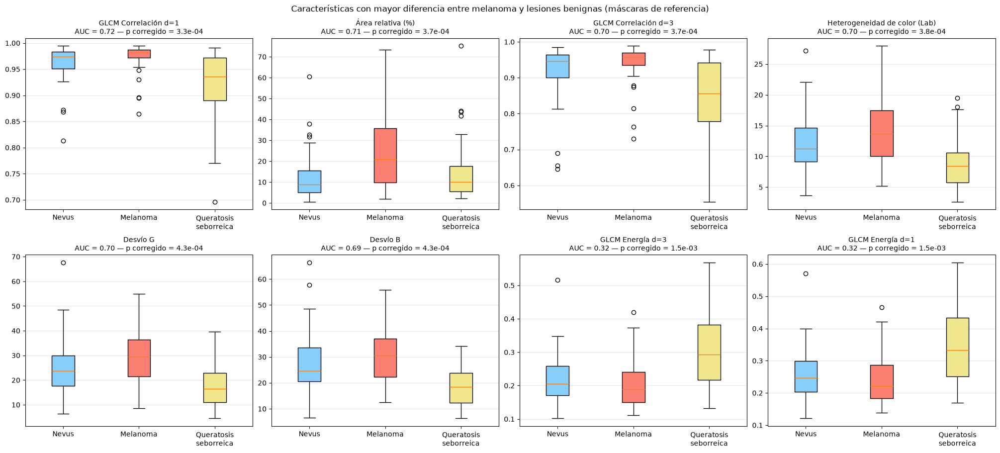

In [51]:
# Diagramas de caja de las 8 características que mejor distinguen melanoma
principales = comparacion_referencia.index[:8]
colores_diagnostico = ["lightskyblue", "salmon", "khaki"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9), constrained_layout=True)

for ax, caracteristica in zip(axes.ravel(), principales):
    valores = [
        referencia_tabla.loc[referencia_tabla["Diagnóstico"] == d, caracteristica]
        for d in diagnosticos
    ]
    cajas = ax.boxplot(valores, patch_artist=True)
    for caja, color in zip(cajas["boxes"], colores_diagnostico):
        caja.set_facecolor(color)

    auc = comparacion_referencia.loc[caracteristica, "AUC melanoma vs benignas"]
    p = comparacion_referencia.loc[caracteristica, "p M–W corregido"]
    ax.set_title(f"{caracteristica}\nAUC = {auc:.2f} — p corregido = {p:.1e}", fontsize=10)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Nevus", "Melanoma", "Queratosis\nseborreica"])
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Características con mayor diferencia entre melanoma y lesiones benignas (máscaras de referencia)")
plt.show()

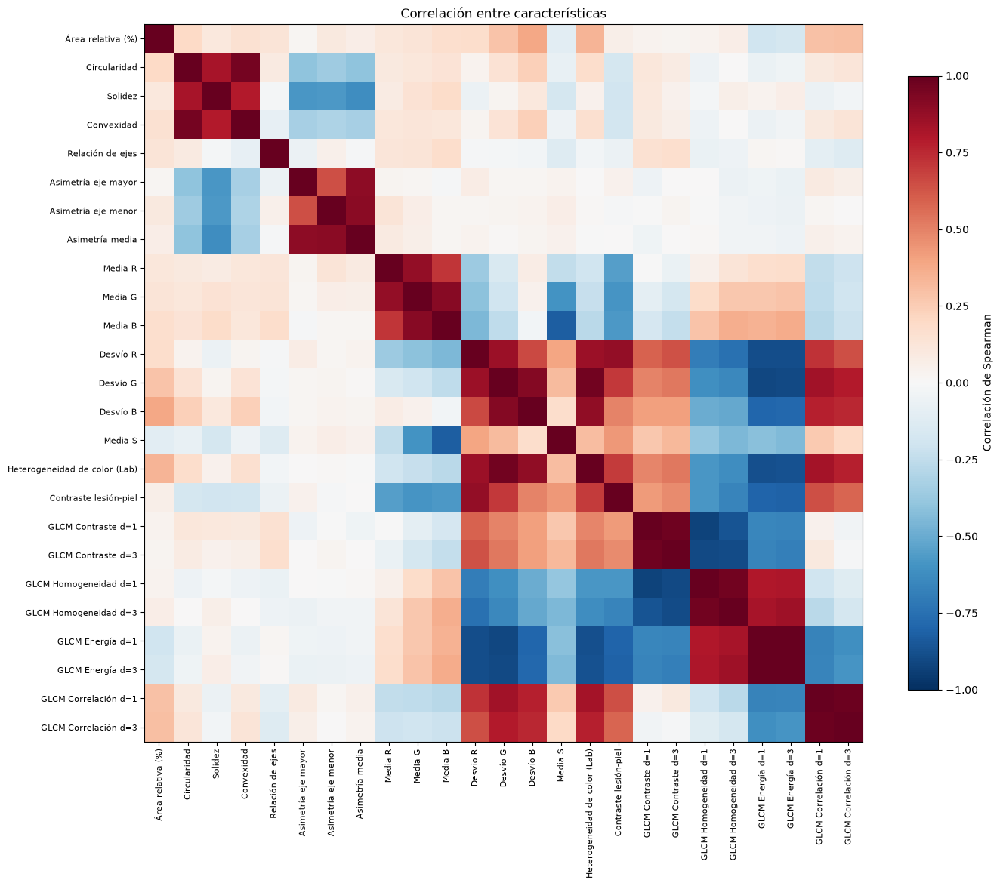

Pares con |ρ| ≥ 0,9:
  GLCM Energía d=1 — GLCM Energía d=3: 1.00
  GLCM Correlación d=1 — GLCM Correlación d=3: 0.98
  GLCM Contraste d=1 — GLCM Contraste d=3: 0.97
  GLCM Homogeneidad d=1 — GLCM Homogeneidad d=3: 0.97
  Desvío G — Heterogeneidad de color (Lab): 0.97
  Circularidad — Convexidad: 0.96
  GLCM Contraste d=1 — GLCM Homogeneidad d=1: -0.93
  Desvío G — Desvío B: 0.92
  Media G — Media B: 0.91
  Desvío G — GLCM Energía d=1: -0.91
  GLCM Contraste d=3 — GLCM Homogeneidad d=1: -0.91
  Asimetría eje menor — Asimetría media: 0.90
  Desvío G — GLCM Energía d=3: -0.90


In [52]:
# Correlación de Spearman entre características (máscaras de referencia).
# Permite identificar características redundantes, que miden lo mismo
correlacion = referencia_tabla[nombres_caracteristicas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12))
imagen = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(nombres_caracteristicas)))
ax.set_xticklabels(nombres_caracteristicas, rotation=90, fontsize=8)
ax.set_yticks(range(len(nombres_caracteristicas)))
ax.set_yticklabels(nombres_caracteristicas, fontsize=8)
fig.colorbar(imagen, ax=ax, shrink=0.8, label="Correlación de Spearman")
ax.set_title("Correlación entre características")
plt.tight_layout()
plt.show()

# Pares de características muy correlacionadas (|ρ| ≥ 0,9)
pares = [
    (a, b, correlacion.loc[a, b])
    for i, a in enumerate(nombres_caracteristicas)
    for b in nombres_caracteristicas[i + 1:]
    if abs(correlacion.loc[a, b]) >= 0.9
]
print("Pares con |ρ| ≥ 0,9:")
for a, b, rho in sorted(pares, key=lambda x: -abs(x[2])):
    print(f"  {a} — {b}: {rho:.2f}")

### Resultado del análisis estadístico

Con las máscaras de referencia, 14 de las 25 características presentan
diferencias significativas entre melanoma y lesiones benignas (p
corregido < 0,05). Ninguna separa los grupos por sí sola: los AUC se
encuentran entre 0,6 y 0,72 (o entre 0,28 y 0,4 para las características
con menores valores en melanoma), y los rangos intercuartílicos se
superponen ampliamente.

- **Color:** Las características de dispersión del color presentan las
  mayores diferencias: la heterogeneidad de color en CIELAB (mediana de
  13,7 en melanoma, frente a 11,3 en nevus y 8,4 en queratosis
  seborreica; AUC = 0,70) y los desvíos de los canales G y B
  (AUC ≈ 0,70). Las medias de color, en cambio, distinguen poco los
  grupos, ya que dependen de la iluminación y de la piel de cada paciente.
- **Textura:** El melanoma presenta mayor correlación (AUC = 0,72) y
  menor energía (AUC = 0,32) en la GLCM. La queratosis seborreica
  presenta la mayor energía y la menor correlación, lo que refleja una
  textura más uniforme con variaciones locales finas. El contraste y la
  homogeneidad de la GLCM no muestran diferencias significativas.
- **Forma:** El melanoma es más asimétrico (asimetría media de 0,081,
  frente a 0,064 en nevus; AUC = 0,65), en concordancia con el criterio
  A de la regla ABCD. En cambio, la circularidad y la convexidad no
  difieren entre diagnósticos. Una posible explicación es que las
  máscaras de referencia de ISIC tienen bordes suavizados o poligonales,
  por lo que no conservan las irregularidades finas del borde que estas
  medidas buscan captar.
- **Tamaño:** El área relativa es mayor en melanoma (mediana de 21 %,
  frente a 9–10 %), pero depende del encuadre y de la ampliación de cada
  imagen, por lo que no puede interpretarse como diferencia de tamaño real.

En el color y la textura, los valores de la queratosis seborreica se
apartan más que los del melanoma, por lo que parte de estas diferencias
podría deberse a la queratosis seborreica y a su origen. Esto se evalúa
en el análisis de sensibilidad.

La matriz de correlación muestra redundancias: los parámetros de la GLCM
a distancias 1 y 3 están casi perfectamente correlacionados
(|ρ| ≥ 0,97), al igual que la heterogeneidad de color y el desvío del
canal G (ρ = 0,97), y la circularidad y la convexidad (ρ = 0,96). En un
eventual clasificador bastaría con una característica de cada grupo.

### Análisis de sensibilidad: origen de las imágenes

Para comprobar si las diferencias encontradas se deben a las lesiones o
al origen de las imágenes, se repite la comparación del melanoma de dos
formas adicionales:

- **Con las lesiones benignas, solo en las imágenes de alta resolución**
  (26 melanomas, 31 nevus y 49 queratosis seborreicas), donde los tres
  diagnósticos provienen de las mismas fuentes.
- **Solo con los nevus, en las 150 imágenes.** Melanomas y nevus se
  reparten entre las fuentes en proporciones similares, por lo que el
  origen afecta a ambos grupos por igual. 

En ambos casos se utilizan la prueba de Mann–Whitney, el AUC y la
corrección de Benjamini–Hochberg. Como las submuestras son más chicas,
la potencia estadística es menor, por lo que se compara principalmente
si el AUC se mantiene.

In [53]:
def comparar_melanoma(tabla, grupo_comparacion):
    """
    Compara el melanoma con otro grupo mediante la prueba U de
    Mann–Whitney, para todas las características. Devuelve el AUC y el
    valor p corregido por Benjamini–Hochberg.
    grupo_comparacion: lista de diagnósticos con los que se compara
    """
    filas = []

    for caracteristica in nombres_caracteristicas:
        # Se excluyen los valores no definidos
        definidos = tabla[caracteristica].notna()
        valores = tabla.loc[definidos, caracteristica]
        diagnostico_valores = tabla.loc[definidos, "Diagnóstico"]

        melanoma = valores[diagnostico_valores == "Melanoma"]
        otros = valores[diagnostico_valores.isin(grupo_comparacion)]

        prueba = mannwhitneyu(melanoma, otros, alternative="two-sided")
        filas.append({
            "Característica": caracteristica,
            # AUC a partir del estadístico U, igual que en el análisis principal
            "AUC": prueba.statistic / (len(melanoma) * len(otros)),
            "p": prueba.pvalue,
        })

    resultado = pd.DataFrame(filas).set_index("Característica")
    resultado["p corregido"] = false_discovery_control(resultado["p"])
    return resultado[["AUC", "p corregido"]]


# Submuestra de alta resolución, con máscaras de referencia
alta_tabla = referencia_tabla[referencia_tabla["Alta resolución"]]
print("Lesiones de alta resolución por diagnóstico:")
display(alta_tabla["Diagnóstico"].value_counts())

# Tres comparaciones del melanoma:
# 1) con las lesiones benignas, en las 150 imágenes (análisis principal)
# 2) con las lesiones benignas, solo en las imágenes de alta resolución
# 3) solo con los nevus, en las 150 imágenes (sin queratosis seborreicas)
benignas = ["Nevus", "Queratosis seborreica"]
sensibilidad = pd.concat({
    "Mel vs benignas (150)": comparar_melanoma(referencia_tabla, benignas),
    "Mel vs benignas (alta resolución)": comparar_melanoma(alta_tabla, benignas),
    "Mel vs nevus (150)": comparar_melanoma(referencia_tabla, ["Nevus"]),
}, axis=1)

# Mismo orden que la tabla del análisis principal
sensibilidad = sensibilidad.loc[comparacion_referencia.index]

with pd.option_context("display.width", 250):
    display(sensibilidad.round(3))

# Medianas de algunas características por diagnóstico, en la submuestra
# de alta resolución
print("Medianas en las imágenes de alta resolución:")
display(
    alta_tabla.groupby("Diagnóstico")[
        ["Heterogeneidad de color (Lab)", "Desvío G", "GLCM Correlación d=1", "Asimetría media"]
    ].median().loc[diagnosticos].round(3)
)

Lesiones de alta resolución por diagnóstico:


Diagnóstico
Queratosis seborreica    49
Nevus                    31
Melanoma                 26
Name: count, dtype: int64

Mel vs benignas (150)             Mel vs benignas (alta resolución)             Mel vs nevus (150)            
                                                AUC p corregido                               AUC p corregido                AUC p corregido
Característica                                                                                                                              
GLCM Correlación d=1                          0.719       0.000                             0.692       0.043              0.627       0.146
Área relativa (%)                             0.707       0.000                             0.625       0.103              0.722       0.003
GLCM Correlación d=3                          0.705       0.000                             0.692       0.043              0.604       0.217
Heterogeneidad de color (Lab)                 0.701       0.000                             0.659       0.053              0.609       0.217
Desvío G                                      0.696       0.000                             0.663       0.053              0.600       0.217
Desvío B                                      0.695       0.000                             0.660       0.053              0.584       0.318
GLCM Energía d=3                              0.323       0.001                             0.351       0.059              0.417       0.318
GLCM Energía d=1                              0.324       0.001                             0.355       0.062              0.424       0.342
Desvío R                                      0.664       0.003                             0.634       0.085              0.602       0.217
Asimetría media                               0.652       0.006                             0.674       0.053              0.698       0.008
Contraste lesión-piel                         0.637       0.014                             0.568       0.407              0.567       0.406
Asimetría eje menor                           0.631       0.019                             0.659       0.053              0.673       0.018
Asimetría eje mayor                           0.629       0.019                             0.651       0.058              0.683       0.014
Solidez                                       0.388       0.047                             0.429       0.407              0.379       0.157
Media G                                       0.391       0.051                             0.424       0.387              0.423       0.342
Relación de ejes                              0.393       0.052                             0.343       0.053              0.450       0.575
Media B                                       0.395       0.055                             0.405       0.248              0.458       0.626
Media S                                       0.598       0.071                             0.625       0.103              0.504       0.992
GLCM Homogeneidad d=3                         0.421       0.150                             0.454       0.610              0.481       0.851
Media R                                       0.432       0.223                             0.486       0.881              0.434       0.406
GLCM Homogeneidad d=1                         0.441       0.282                             0.473       0.777              0.499       0.992
GLCM Contraste d=3                            0.546       0.409                             0.501       0.991              0.523       0.824
GLCM Contraste d=1                            0.522       0.720                             0.487       0.881              0.498       0.992
Convexidad                                    0.515       0.794                             0.567       0.407              0.468       0.729
Circularidad                                  0.502       0.970                             0.543       0.614              0.452       0.575

Medianas en las imágenes de alta resolución:


,Heterogeneidad de color (Lab),Desvío G,GLCM Correlación d=1,Asimetría media
Diagnóstico,,,,
Nevus,10.162,22.136,0.971,0.062
Melanoma,10.342,22.108,0.973,0.093
Queratosis seborreica,8.323,15.970,0.936,0.068


#### Resultado del análisis de sensibilidad

**La asimetría es la característica más robusta:** Distingue el melanoma
de forma consistente en los tres análisis: AUC de 0,65 frente a las
lesiones benignas en las 150 imágenes, 0,67 en las imágenes de alta
resolución y 0,70 frente a los nevus (p corregido = 0,008). Además, no
depende del origen de las imágenes. Este resultado es coherente con el
criterio A de la regla ABCD.

**La dispersión del color y la textura distinguen principalmente a la
queratosis seborreica, no al melanoma:** En las imágenes de alta
resolución, el melanoma y el nevus presentan prácticamente la misma
heterogeneidad de color (medianas de 10,3 y 10,2), el mismo desvío del
canal G (22,1 en ambos) y la misma correlación de la GLCM (0,973 y
0,971), mientras que la queratosis seborreica presenta valores menores
(8,3; 16,0 y 0,936). Por eso estas características mantienen su AUC
frente al conjunto de lesiones benignas (0,66–0,69 en alta resolución),
pero frente a los nevus su capacidad de distinción es baja y no
significativa (AUC de 0,60–0,63; p corregido ≥ 0,15). Es decir, reflejan
sobre todo la diferencia entre la queratosis seborreica, una lesión no
melanocítica, y las lesiones melanocíticas.

El área relativa es mayor en el melanoma también frente a los nevus
(AUC = 0,72), pero, como se indicó, depende del encuadre de cada imagen.

En las imágenes de alta resolución, la mayoría de los valores p
corregidos se ubican cerca de 0,05, lo que es esperable por el menor
tamaño de la muestra (106 imágenes). Por lo tanto, la conclusión se basa
principalmente en la estabilidad de los AUC.

En síntesis, controlando el origen de las imágenes, la característica que
distingue al melanoma de las lesiones benignas, y en particular de los
nevus, es la asimetría. Las diferencias de color y textura entre melanoma
y lesiones benignas observadas en el análisis principal se explican
principalmente por la queratosis seborreica y deben interpretarse con
cautela.

### Efecto de la segmentación sobre las características

Se comparan las características obtenidas con la máscara automática y con la de referencia en las mismas lesiones. Para cada característica se calculan:

- **Correlación de Spearman** entre ambos valores: indica si la máscara automática conserva el orden de las lesiones (por ejemplo, si las lesiones más asimétricas según la referencia también lo son según la segmentación automática).
- **Diferencia relativa mediana:** mediana de |automática − referencia| / |referencia|, que cuantifica el error de medición típico.
- **AUC con cada máscara:** permite evaluar si la capacidad de distinguir melanoma se mantiene al utilizar la segmentación automática.

Lesiones con ambas máscaras: 147


,ρ Spearman (auto vs ref),Diferencia relativa mediana (%),AUC referencia,AUC automática,p M–W corregido (auto)
Característica,,,,,
GLCM Correlación d=1,0.878,0.791,0.719,0.692,0.003
Área relativa (%),0.510,22.611,0.707,0.612,0.049
GLCM Correlación d=3,0.857,1.872,0.705,0.678,0.003
Heterogeneidad de color (Lab),0.839,12.195,0.701,0.656,0.007
Desvío G,0.873,13.938,0.696,0.671,0.003
Desvío B,0.762,15.973,0.695,0.631,0.019
GLCM Energía d=3,0.843,7.164,0.323,0.350,0.009
GLCM Energía d=1,0.847,7.370,0.324,0.355,0.010
Desvío R,0.900,9.619,0.664,0.648,0.009


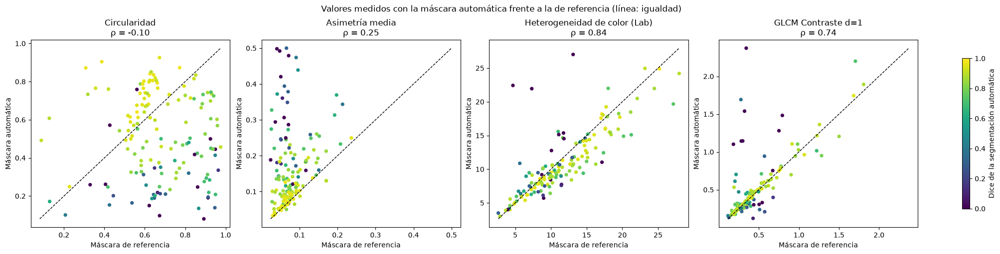

In [54]:
# Emparejar los valores de cada lesión con ambas máscaras
pares_mascaras = (
    caracteristicas_lesiones
    .pivot(index="image_id", columns="Máscara", values=nombres_caracteristicas)
    .dropna()
)

automatica_tabla = caracteristicas_lesiones[caracteristicas_lesiones["Máscara"] == "Automática"]
comparacion_automatica = comparar_diagnosticos(automatica_tabla)

filas_efecto = []
for caracteristica in nombres_caracteristicas:
    referencia_valores = pares_mascaras[(caracteristica, "Referencia")]
    automatica_valores = pares_mascaras[(caracteristica, "Automática")]
    diferencia_relativa = (
        (automatica_valores - referencia_valores).abs() / referencia_valores.abs()
    )
    filas_efecto.append({
        "Característica": caracteristica,
        "ρ Spearman (auto vs ref)": referencia_valores.corr(automatica_valores, method="spearman"),
        "Diferencia relativa mediana (%)": 100 * diferencia_relativa.median(),
        "AUC referencia": comparacion_referencia.loc[caracteristica, "AUC melanoma vs benignas"],
        "AUC automática": comparacion_automatica.loc[caracteristica, "AUC melanoma vs benignas"],
        "p M–W corregido (auto)": comparacion_automatica.loc[caracteristica, "p M–W corregido"],
    })

efecto_segmentacion = pd.DataFrame(filas_efecto).set_index("Característica")
print(f"Lesiones con ambas máscaras: {len(pares_mascaras)}")
display(efecto_segmentacion.loc[comparacion_referencia.index].round(3))

# Dispersión automática vs referencia para cuatro características representativas
seleccion = ["Circularidad", "Asimetría media", "Heterogeneidad de color (Lab)", "GLCM Contraste d=1"]
dice_final = (
    resultados_metodos[resultados_metodos["Método"] == metodo_final]
    .set_index("image_id")["Dice"]
    .reindex(pares_mascaras.index)
)

fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
for ax, caracteristica in zip(axes, seleccion):
    x = pares_mascaras[(caracteristica, "Referencia")]
    y = pares_mascaras[(caracteristica, "Automática")]
    puntos = ax.scatter(x, y, c=dice_final, cmap="viridis", vmin=0, vmax=1, s=18)
    limites = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(limites, limites, "k--", linewidth=1)
    ax.set_xlabel("Máscara de referencia")
    ax.set_ylabel("Máscara automática")
    rho = efecto_segmentacion.loc[caracteristica, "ρ Spearman (auto vs ref)"]
    ax.set_title(f"{caracteristica}\nρ = {rho:.2f}")
fig.colorbar(puntos, ax=axes, shrink=0.8, label="Dice de la segmentación automática")
fig.suptitle("Valores medidos con la máscara automática frente a la de referencia (línea: igualdad)")
plt.show()

### Resultado del efecto de la segmentación

Se compararon 147 lesiones; en las otras 3, la máscara automática abarca toda la imagen y no puede definirse la piel perilesional.

Las características de **color y textura** son robustas a la segmentación: la correlación entre los valores obtenidos con ambas máscaras es alta (ρ entre 0,71 y 0,90) y su diferencia relativa mediana es, en general, menor que el 15 %. En consecuencia, conservan su capacidad para distinguir el melanoma: por ejemplo, la heterogeneidad de color pasa de un AUC de 0,70 a 0,66 y la correlación de la GLCM, de 0,72 a 0,69, y ambas siguen siendo significativas. Esto se debe a que dependen del contenido de la región y no de la posición exacta de su borde: mientras la máscara cubra la mayor parte de la lesión, el promedio y la dispersión de sus píxeles cambian poco.

Las características de **forma**, en cambio, son muy sensibles a la segmentación. La asimetría presenta una correlación de 0,25 entre ambas máscaras y una diferencia relativa mediana superior al 50 %; la solidez, la circularidad y la convexidad prácticamente no se correlacionan (|ρ| < 0,1). Con la máscara automática, la asimetría deja de distinguir el melanoma (AUC de 0,65 a 0,46). Estas medidas dependen directamente del contorno: un error de pocos píxeles en el borde o la inclusión de una región vecina modifica la forma de la lesión aunque el Dice siga siendo alto. Además, las máscaras de referencia tienen bordes suaves, mientras que las automáticas siguen los cambios locales de pigmentación y presentan contornos más irregulares. Por eso la circularidad medida con la máscara automática suele ser menor que la de referencia.

Por lo tanto, la calidad de la segmentación condiciona sobre todo el análisis morfológico. Para utilizar la asimetría o la irregularidad del borde en un sistema automático se requeriría una segmentación más precisa del contorno que la obtenida con los métodos clásicos evaluados.

## Compresión y descompresión de las imágenes

Las imágenes médicas suelen almacenarse y transmitirse comprimidas. Existen dos tipos de compresión:

- **Sin pérdida (por ejemplo, PNG):** la imagen descomprimida es idéntica a la original. Reduce el tamaño eliminando redundancias en la codificación, pero la reducción es limitada.
- **Con pérdida (por ejemplo, JPEG):** la imagen se divide en bloques de 8 × 8 píxeles y cada bloque se transforma mediante la transformada discreta del coseno (DCT), que lo descompone en componentes de distintas frecuencias espaciales. Luego, los coeficientes se dividen por una tabla de cuantificación y se redondean. Como el ojo es menos sensible a las altas frecuencias (detalles finos), estas se cuantifican con mayor agresividad y muchas se anulan. Al descomprimir, la imagen se reconstruye con la DCT inversa a partir de los coeficientes cuantificados, por lo que el resultado es una aproximación de la original. El parámetro de **calidad** (1 a 100) escala la tabla de cuantificación: a menor calidad, mayor compresión y mayor pérdida.

A calidades bajas, JPEG produce **artefactos de bloque** (discontinuidades en los bordes de los bloques de 8 × 8) y pérdida de detalles finos, que podrían afectar la segmentación y, en especial, las características de textura.

Las imágenes de ISIC 2017 ya se distribuyen en formato JPEG. En esta sección se estudia:

1. **La compresión original del dataset:** se estima la calidad JPEG de cada imagen a partir de su tabla de cuantificación, que se guarda en el encabezado del archivo.
2. **El efecto de una compresión adicional:** las 150 imágenes de la muestra, a la resolución de trabajo, se comprimen y descomprimen en PNG y en JPEG con calidades de 95, 75, 50, 25 y 10. Para cada variante se mide la **tasa de compresión**, la **calidad de la imagen reconstruida** (PSNR y SSIM) y el efecto sobre la **segmentación** y las **características de color y textura**.

La segmentación se evalúa con Otsu sobre el canal S y el refinamiento final, en lugar de Chan–Vese: ambos métodos obtuvieron un desempeño similar y Otsu es mucho más rápido, lo que permite repetir el pipeline para las seis variantes. Las características de color y textura se miden con la máscara de referencia, para aislar el efecto de la compresión del de la segmentación. Las características de forma no se analizan, porque con la máscara de referencia no dependen de la imagen.

In [55]:
from PIL import Image
from skimage.metrics import structural_similarity

# Tabla estándar de cuantificación de luminancia de JPEG (norma ITU-T T.81,
# Anexo K), que corresponde a la calidad 50
TABLA_LUMINANCIA_ESTANDAR = np.array([
    16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55,
    14, 13, 16, 24, 40, 57, 69, 56, 14, 17, 22, 29, 51, 87, 80, 62,
    18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
    49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99,
])


def estimar_calidad_jpeg(archivo):
    """
    Estima la calidad JPEG con la que se guardó una imagen.
    El codificador estándar (libjpeg) obtiene la tabla de cuantificación
    escalando la tabla estándar: escala = 5000 / calidad si calidad < 50, y
    escala = 200 - 2 · calidad si no. Se estima la escala y se invierte la
    fórmula. archivo: ruta o datos en memoria (BytesIO).
    La escala se estima como la mediana del cociente entre cada valor de la
    tabla del archivo y el de la tabla estándar. Se excluyen los valores
    saturados (1 y 255), que el codificador recorta y no reflejan la escala.
    """
    with Image.open(archivo) as imagen:
        # Pillow devuelve la tabla en el mismo orden que la tabla estándar
        tabla = np.array(imagen.quantization[0], dtype=float)

    validos = (tabla > 1) & (tabla < 255)
    if not validos.any():
        # Todos los valores en 1: calidad máxima
        return 100.0

    escala = np.median(100 * tabla[validos] / TABLA_LUMINANCIA_ESTANDAR[validos])
    calidad = 5000 / escala if escala > 100 else (200 - escala) / 2
    return float(np.clip(calidad, 1, 100))


# Verificación: comprimir una imagen con calidades conocidas y estimarlas
from io import BytesIO

ejemplo_bgr = cv2.cvtColor(imagenes_trabajo[df_muestra["image_id"].iloc[0]], cv2.COLOR_RGB2BGR)
verificacion = {}
for calidad in [95, 75, 50, 25, 10]:
    _, datos_jpeg = cv2.imencode(".jpg", ejemplo_bgr, [cv2.IMWRITE_JPEG_QUALITY, calidad])
    verificacion[calidad] = round(estimar_calidad_jpeg(BytesIO(datos_jpeg.tobytes())), 1)
print("Calidad usada → calidad estimada:", verificacion)

# Calidad estimada de los archivos originales de la muestra
calidad_original = pd.DataFrame([
    {
        "image_id": registro["image_id"],
        "Diagnóstico": registro["diagnostico"],
        "Calidad JPEG estimada": estimar_calidad_jpeg(rutas[registro["image_id"]]),
    }
    for _, registro in df_muestra.iterrows()
])
calidad_original["Lado mayor original (px)"] = calidad_original["image_id"].map(
    caracteristicas.set_index("image_id")["Lado mayor (px)"]
)
calidad_original["Resolución original"] = np.where(
    calidad_original["Lado mayor original (px)"] > 2000, "> 2000 px", "≤ 2000 px"
)

print("\nCalidad JPEG estimada de los archivos originales (150 imágenes):")
display(
    calidad_original
    .groupby(["Resolución original", "Diagnóstico"])["Calidad JPEG estimada"]
    .describe()[["count", "min", "50%", "max"]]
    .rename(columns={"count": "Cantidad", "min": "Mínima", "50%": "Mediana", "max": "Máxima"})
    .round(1)
)

Calidad usada → calidad estimada: {95: 95.0, 75: 75.0, 50: 50.0, 25: 25.0, 10: 10.0}

Calidad JPEG estimada de los archivos originales (150 imágenes):


Cantidad  Mínima  Mediana  Máxima
Resolución original Diagnóstico                                             
> 2000 px           Melanoma                   26.0    75.0     98.5   100.0
                    Nevus                      31.0    85.0    100.0   100.0
                    Queratosis seborreica      49.0    80.0    100.0   100.0
≤ 2000 px           Melanoma                   24.0    70.0     94.0   100.0
                    Nevus                      19.0    75.0     95.0    98.1
                    Queratosis seborreica       1.0   100.0    100.0   100.0

#### Resultado de la compresión original del dataset

La verificación confirma que el método recupera la calidad usada al comprimir (95, 75, 50, 25 y 10). En los archivos originales, la calidad estimada es alta: mediana de 100 en las imágenes de alta resolución y de 95 en las de baja resolución, con mínimos de 70–85. Es decir, las imágenes del dataset tienen una compresión leve, algo mayor en la fuente de baja resolución. La estimación supone que el equipo usó las tablas estándar de JPEG; si utilizó tablas propias, el valor es aproximado.

### Compresión adicional: tasa de compresión, calidad de reconstrucción y efecto sobre el pipeline

Cada imagen de la muestra, a la resolución de trabajo, se comprime en memoria y se descomprime con cada variante. Sobre la imagen reconstruida se repite el pipeline: corrección de artefactos, canal S, Otsu con el refinamiento final, y extracción de las características de color y textura dentro de la máscara de referencia. Se registran:

- **Tasa de compresión:** tamaño de la imagen sin comprimir (alto × ancho × 3 bytes) dividido por el tamaño del archivo comprimido. Una tasa de 10 significa que el archivo ocupa la décima parte. También se informan los **bits por píxel** (bpp); la imagen sin comprimir usa 24 bpp.
- **PSNR** (relación señal-ruido de pico): mide el error cuadrático medio entre la imagen reconstruida y la original, en decibeles. Valores mayores indican menor error; por encima de 40 dB las diferencias suelen ser imperceptibles.
- **SSIM** (índice de similitud estructural): compara luminancia, contraste y estructura local entre ambas imágenes en escala de grises. Vale 1 si son idénticas y se aproxima mejor que el PSNR a la calidad percibida.
- **Dice respecto de la referencia** de la segmentación obtenida sobre la imagen reconstruida, y **Dice respecto de la segmentación de la imagen sin recomprimir**, que mide cuánto cambia la máscara solo por la compresión.
- **Características de color y textura** medidas sobre la imagen reconstruida.

La variante "Sin recomprimir" corresponde a la imagen tal como se utilizó en el resto del trabajo y sirve como referencia.

In [56]:
# Variantes de compresión: nombre → (extensión, parámetros de cv2.imencode)
variantes_compresion = {
    "PNG": (".png", [cv2.IMWRITE_PNG_COMPRESSION, 9]),
    "JPEG 95": (".jpg", [cv2.IMWRITE_JPEG_QUALITY, 95]),
    "JPEG 75": (".jpg", [cv2.IMWRITE_JPEG_QUALITY, 75]),
    "JPEG 50": (".jpg", [cv2.IMWRITE_JPEG_QUALITY, 50]),
    "JPEG 25": (".jpg", [cv2.IMWRITE_JPEG_QUALITY, 25]),
    "JPEG 10": (".jpg", [cv2.IMWRITE_JPEG_QUALITY, 10]),
}
orden_compresion = ["Sin recomprimir"] + list(variantes_compresion)


def comprimir_y_descomprimir(rgb, extension, parametros):
    """
    Comprime la imagen en memoria con cv2.imencode y la reconstruye con
    cv2.imdecode. Devuelve la imagen reconstruida (RGB) y el tamaño del
    archivo comprimido en bytes.
    """
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    exito, datos = cv2.imencode(extension, bgr, parametros)
    if not exito:
        raise ValueError(f"No se pudo comprimir en {extension}")
    reconstruida = cv2.imdecode(datos, cv2.IMREAD_COLOR)
    return cv2.cvtColor(reconstruida, cv2.COLOR_BGR2RGB), datos.size


def segmentar_otsu_s(rgb):
    """Pipeline de segmentación: corrección de artefactos, canal S, Otsu y refinamiento."""
    corregida, _ = corregir_artefactos(
        rgb, tamanio_kernel=tamanio_elegido, umbral=umbral_elegido,
        refinamiento="Solo cierre", lado_trabajo=lado_trabajo
    )
    canal_s = cv2.cvtColor(corregida, cv2.COLOR_RGB2HSV)[:, :, 1]
    return seleccionar_lesion(otsu(canal_s, invertir=False)[1])


filas_compresion = []
reconstrucciones_ejemplo = {}

for numero, (image_id, datos) in enumerate(datos_segmentacion.items(), start=1):
    original = imagenes_trabajo[image_id]
    referencia = datos["Referencia"]
    alto, ancho = original.shape[:2]
    gris_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Segmentación de la imagen sin recomprimir, para medir cuánto cambia
    # la máscara por efecto de la compresión
    mascara_original = segmentar_otsu_s(original)

    for nombre in orden_compresion:
        if nombre == "Sin recomprimir":
            reconstruida, tamanio = original, alto * ancho * 3
        else:
            reconstruida, tamanio = comprimir_y_descomprimir(original, *variantes_compresion[nombre])

        gris = cv2.cvtColor(reconstruida, cv2.COLOR_RGB2GRAY)
        mascara = mascara_original if nombre == "Sin recomprimir" else segmentar_otsu_s(reconstruida)

        filas_compresion.append({
            "image_id": image_id,
            "Diagnóstico": datos["Diagnóstico"],
            "Variante": nombre,
            "Tasa de compresión": alto * ancho * 3 / tamanio,
            "Bits por píxel": 8 * tamanio / (alto * ancho),
            # El PSNR de imágenes idénticas es infinito
            "PSNR (dB)": np.inf if np.array_equal(reconstruida, original) else cv2.PSNR(original, reconstruida),
            "SSIM": structural_similarity(gris_original, gris, data_range=255),
            "Dice vs referencia": calcular_dice_jaccard(mascara, referencia)[0],
            "Dice vs sin recomprimir": calcular_dice_jaccard(mascara, mascara_original)[0],
            **caracteristicas_color(reconstruida, referencia),
            **caracteristicas_textura(reconstruida, referencia),
        })

        # Guardar las reconstrucciones del ejemplo de melanoma para la figura
        if image_id == ejemplos["image_id"].iloc[0]:
            reconstrucciones_ejemplo[nombre] = reconstruida

    if numero % 50 == 0:
        print(f"Procesadas {numero}/{len(datos_segmentacion)} imágenes", flush=True)

resultados_compresion = pd.DataFrame(filas_compresion)

# Resumen por variante (150 imágenes cada una)
resumen_compresion = (
    resultados_compresion
    .replace({"PSNR (dB)": {np.inf: np.nan}})
    .groupby("Variante")
    .agg(
        Tasa_mediana=("Tasa de compresión", "median"),
        Bits_por_pixel=("Bits por píxel", "median"),
        PSNR_medio_dB=("PSNR (dB)", "mean"),
        SSIM_medio=("SSIM", "mean"),
        Dice_medio=("Dice vs referencia", "mean"),
        Dice_mediano=("Dice vs referencia", "median"),
        Dice_vs_sin_recomprimir=("Dice vs sin recomprimir", "median"),
    )
    .reindex(orden_compresion)
)
display(resumen_compresion.round(3))

# Comparación pareada del Dice de cada variante con la imagen sin recomprimir
dice_compresion = resultados_compresion.pivot(index="image_id", columns="Variante", values="Dice vs referencia")
filas_pareadas_compresion = []
for nombre in variantes_compresion:
    diferencia = dice_compresion[nombre] - dice_compresion["Sin recomprimir"]
    cambiadas = diferencia.abs() > 0.01
    filas_pareadas_compresion.append({
        "Variante": nombre,
        "Mejora (>0,01)": int((diferencia > 0.01).sum()),
        "Empeora (<-0,01)": int((diferencia < -0.01).sum()),
        "Diferencia media": diferencia.mean(),
        # Wilcoxon no admite diferencias todas nulas
        "p (Wilcoxon)": wilcoxon(dice_compresion[nombre], dice_compresion["Sin recomprimir"]).pvalue
        if cambiadas.any() else np.nan,
    })
display(pd.DataFrame(filas_pareadas_compresion).set_index("Variante").round(4))

Procesadas 50/150 imágenes
Procesadas 100/150 imágenes
Procesadas 150/150 imágenes


,Tasa_mediana,Bits_por_pixel,PSNR_medio_dB,SSIM_medio,Dice_medio,Dice_mediano,Dice_vs_sin_recomprimir
Variante,,,,,,,
Sin recomprimir,1.000,24.000,NaN,1.000,0.690,0.839,1.000
PNG,2.586,9.279,NaN,1.000,0.690,0.839,1.000
JPEG 95,13.101,1.832,46.494,0.991,0.694,0.837,0.990
JPEG 75,39.970,0.600,40.962,0.969,0.696,0.843,0.983
JPEG 50,66.064,0.363,38.376,0.951,0.693,0.847,0.977
JPEG 25,103.954,0.231,35.936,0.922,0.696,0.847,0.962
JPEG 10,150.664,0.159,31.585,0.860,0.630,0.776,0.920


,"Mejora (>0,01)","Empeora (<-0,01)",Diferencia media,p (Wilcoxon)
Variante,,,,
PNG,0,0,0.0000,NaN
JPEG 95,25,14,0.0041,0.5665
JPEG 75,26,24,0.0058,0.2217
JPEG 50,29,30,0.0024,0.2543
JPEG 25,30,37,0.0056,0.2339
JPEG 10,34,81,-0.0601,0.0000


In [57]:
# Cambio de las características de color y textura respecto de la imagen
# sin recomprimir, imagen por imagen
# Nombres de las características: se toman de la lista general del
# análisis, quitando las de forma (no dependen de la imagen)
nombres_forma = list(caracteristicas_morfologicas(circulo))
nombres_color_textura = [c for c in nombres_caracteristicas if c not in nombres_forma]

base = resultados_compresion[resultados_compresion["Variante"] == "Sin recomprimir"].set_index("image_id")

filas_cambio = []
for nombre in variantes_compresion:
    variante = resultados_compresion[resultados_compresion["Variante"] == nombre].set_index("image_id")
    for caracteristica in nombres_color_textura:
        cambio_relativo = (
            (variante[caracteristica] - base[caracteristica]).abs() / base[caracteristica].abs()
        )
        filas_cambio.append({
            "Característica": caracteristica,
            "Variante": nombre,
            "Cambio relativo mediano (%)": 100 * cambio_relativo.median(),
        })

cambio_caracteristicas = (
    pd.DataFrame(filas_cambio)
    .pivot(index="Característica", columns="Variante", values="Cambio relativo mediano (%)")
    .reindex(index=nombres_color_textura, columns=list(variantes_compresion))
)
print("Cambio relativo mediano respecto de la imagen sin recomprimir (%):")
display(cambio_caracteristicas.round(2))

# ¿Se mantienen las diferencias entre diagnósticos? AUC del melanoma frente
# a las lesiones benignas para las características destacadas del análisis
# estadístico, en cada variante
destacadas = ["Heterogeneidad de color (Lab)", "Desvío G", "GLCM Correlación d=1", "GLCM Energía d=1", "GLCM Contraste d=1"]
filas_auc = []
for nombre in orden_compresion:
    variante = resultados_compresion[resultados_compresion["Variante"] == nombre]
    es_melanoma = variante["Diagnóstico"] == "Melanoma"
    fila = {"Variante": nombre}
    for caracteristica in destacadas:
        melanoma, benignas = variante.loc[es_melanoma, caracteristica], variante.loc[~es_melanoma, caracteristica]
        fila[caracteristica] = mannwhitneyu(melanoma, benignas).statistic / (len(melanoma) * len(benignas))
    filas_auc.append(fila)

print("AUC del melanoma frente a las lesiones benignas en cada variante:")
display(pd.DataFrame(filas_auc).set_index("Variante").round(3))

Cambio relativo mediano respecto de la imagen sin recomprimir (%):


Variante,PNG,JPEG 95,JPEG 75,JPEG 50,JPEG 25,JPEG 10
Característica,,,,,,
Media R,0.0,0.02,0.02,0.06,0.10,0.35
Media G,0.0,0.01,0.02,0.05,0.12,0.26
Media B,0.0,0.02,0.06,0.15,0.43,0.84
Desvío R,0.0,0.29,0.72,1.28,1.98,6.15
Desvío G,0.0,0.08,0.23,0.38,0.56,1.07
Desvío B,0.0,0.28,0.56,0.86,1.07,3.01
Media S,0.0,0.05,0.10,0.22,0.56,1.44
Heterogeneidad de color (Lab),0.0,0.56,0.74,0.71,0.78,5.24
Contraste lesión-piel,0.0,0.12,0.31,0.87,1.43,6.22


AUC del melanoma frente a las lesiones benignas en cada variante:


,Heterogeneidad de color (Lab),Desvío G,GLCM Correlación d=1,GLCM Energía d=1,GLCM Contraste d=1
Variante,,,,,
Sin recomprimir,0.701,0.696,0.719,0.324,0.522
PNG,0.701,0.696,0.719,0.324,0.522
JPEG 95,0.701,0.697,0.717,0.324,0.521
JPEG 75,0.700,0.697,0.720,0.328,0.528
JPEG 50,0.702,0.698,0.701,0.321,0.545
JPEG 25,0.703,0.697,0.704,0.321,0.545
JPEG 10,0.701,0.698,0.699,0.327,0.560


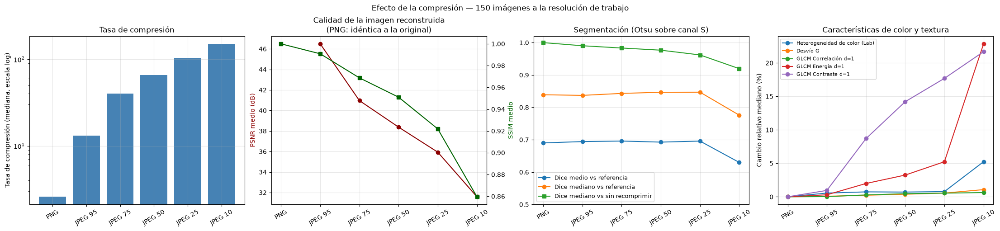

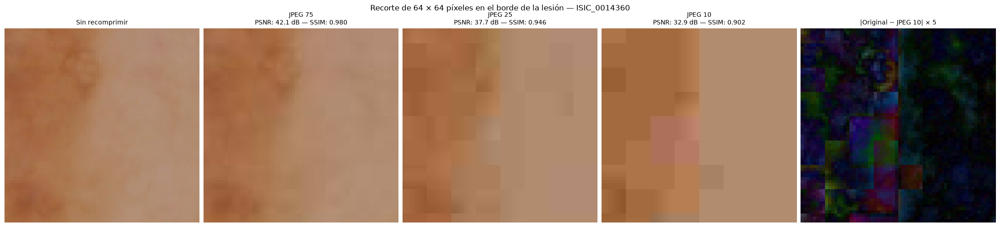

In [58]:
# Figura 1: tasa de compresión, calidad de reconstrucción, segmentación y
# características en función de la variante
variantes_grafico = list(variantes_compresion)
posiciones = np.arange(len(variantes_grafico))
resumen = resumen_compresion.loc[variantes_grafico]

fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)

axes[0].bar(posiciones, resumen["Tasa_mediana"], color="steelblue")
axes[0].set_yscale("log")
axes[0].set_ylabel("Tasa de compresión (mediana, escala log)")
axes[0].set_title("Tasa de compresión")

axes[1].plot(posiciones, resumen["PSNR_medio_dB"], marker="o", color="darkred", label="PSNR")
axes[1].set_ylabel("PSNR medio (dB)", color="darkred")
eje_ssim = axes[1].twinx()
eje_ssim.plot(posiciones, resumen["SSIM_medio"], marker="s", color="darkgreen", label="SSIM")
eje_ssim.set_ylabel("SSIM medio", color="darkgreen")
axes[1].set_title("Calidad de la imagen reconstruida\n(PNG: idéntica a la original)")

axes[2].plot(posiciones, resumen["Dice_medio"], marker="o", label="Dice medio vs referencia")
axes[2].plot(posiciones, resumen["Dice_mediano"], marker="o", label="Dice mediano vs referencia")
axes[2].plot(posiciones, resumen["Dice_vs_sin_recomprimir"], marker="s", label="Dice mediano vs sin recomprimir")
axes[2].set_ylim(0.5, 1.02)
axes[2].set_title("Segmentación (Otsu sobre canal S)")
axes[2].legend(fontsize=9)

for caracteristica in destacadas:
    axes[3].plot(posiciones, cambio_caracteristicas.loc[caracteristica, variantes_grafico], marker="o", label=caracteristica)
axes[3].set_ylabel("Cambio relativo mediano (%)")
axes[3].set_title("Características de color y textura")
axes[3].legend(fontsize=8)

for ax in axes:
    ax.set_xticks(posiciones)
    ax.set_xticklabels(variantes_grafico, rotation=30)
    ax.grid(alpha=0.3)

fig.suptitle("Efecto de la compresión — 150 imágenes a la resolución de trabajo")
plt.show()

# Figura 2: recorte ampliado en el borde de la lesión del ejemplo de
# melanoma, para observar los artefactos de bloque
id_ejemplo_compresion = ejemplos["image_id"].iloc[0]
referencia_ejemplo = datos_segmentacion[id_ejemplo_compresion]["Referencia"]

# Centro del recorte: el punto del contorno de la lesión más a la derecha
contornos, _ = cv2.findContours(referencia_ejemplo, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
puntos = np.vstack(contornos)[:, 0, :]
cx, cy = puntos[np.argmax(puntos[:, 0])]
lado_recorte = 64
alto, ancho = referencia_ejemplo.shape
x0 = int(np.clip(cx - lado_recorte // 2, 0, ancho - lado_recorte))
y0 = int(np.clip(cy - lado_recorte // 2, 0, alto - lado_recorte))


def recorte(imagen):
    return imagen[y0:y0 + lado_recorte, x0:x0 + lado_recorte]


paneles = ["Sin recomprimir", "JPEG 75", "JPEG 25", "JPEG 10"]
fig, axes = plt.subplots(1, len(paneles) + 1, figsize=(22, 5), constrained_layout=True)

for ax, nombre in zip(axes, paneles):
    ax.imshow(recorte(reconstrucciones_ejemplo[nombre]), interpolation="nearest")
    fila = resultados_compresion[
        (resultados_compresion["image_id"] == id_ejemplo_compresion)
        & (resultados_compresion["Variante"] == nombre)
    ].iloc[0]
    detalle = "" if nombre == "Sin recomprimir" else f"\nPSNR: {fila['PSNR (dB)']:.1f} dB — SSIM: {fila['SSIM']:.3f}"
    ax.set_title(f"{nombre}{detalle}", fontsize=10)

# Diferencia absoluta entre la original y JPEG 10, amplificada x5 para que sea visible
diferencia = cv2.absdiff(reconstrucciones_ejemplo["Sin recomprimir"], reconstrucciones_ejemplo["JPEG 10"])
axes[-1].imshow(np.clip(recorte(diferencia).astype(int) * 5, 0, 255).astype(np.uint8), interpolation="nearest")
axes[-1].set_title("|Original − JPEG 10| × 5", fontsize=10)

for ax in axes:
    ax.axis("off")

fig.suptitle(f"Recorte de {lado_recorte} × {lado_recorte} píxeles en el borde de la lesión — {id_ejemplo_compresion}")
plt.show()

#### Resultado del efecto de la compresión

**PNG (sin pérdida):** El archivo queda 2,6 veces más chico (9,3 bits por píxel) y la imagen reconstruida es exactamente igual a la original. Por eso la segmentación y todas las características dan los mismos valores.

**JPEG (con pérdida):** El archivo queda 13 veces más chico con calidad 95, 40 veces con calidad 75 y 151 veces con calidad 10. A cambio, la imagen se aleja cada vez más de la original. El PSNR medio pasa de 46,5 dB (calidad 95) a 41,0 dB (75), 35,9 dB (25) y 31,6 dB (10), y el SSIM medio, de 0,991 a 0,969, 0,922 y 0,860.

En el recorte ampliado, con calidad 75 no se ven diferencias con la original. Con calidad 25 y 10 aparecen bloques de color uniforme y se pierden los detalles del borde de la lesión. Estos bloques miden 16 × 16 píxeles y no 8 × 8 porque JPEG guarda los canales de color con la mitad de resolución que el brillo (submuestreo de croma), ya que el ojo es menos sensible a los cambios de color.

**Segmentación:** Hasta calidad 25, la segmentación prácticamente no cambia: el Dice medio se mantiene entre 0,690 y 0,696 y la diferencia con la imagen sin recomprimir no es significativa (Wilcoxon, p ≥ 0,22). Las máscaras obtenidas son casi iguales a las de la imagen original (Dice mediano entre ambas de 0,99 con calidad 95 y 0,96 con calidad 25). Recién con calidad 10 el Dice medio baja a 0,630 y empeora en 81 de las 150 imágenes (p < 0,001), porque los bloques deforman el borde de la lesión.

Que la segmentación resista tanto tiene sentido, ya que para separar la lesión de la piel alcanza con la diferencia de saturación entre ambas, que es una variación grande (de baja frecuencia). JPEG conserva este tipo de variaciones y descarta sobre todo los detalles finos.

**Características:** El color casi no se ve afectado: cambia menos del 2 % hasta calidad 25 y menos del 7 % con calidad 10. Esto se debe a que las características de color son promedios y dispersiones de toda la lesión, y los detalles finos que elimina JPEG apenas los modifican.

La textura es lo que más cambia. El contraste de la GLCM (d = 1) baja un 9 % con calidad 75, un 18 % con calidad 25 y un 21 % con calidad 10, mientras que la energía y la homogeneidad suben. Es decir, la lesión queda con una textura más lisa, porque la GLCM mide justamente las diferencias entre píxeles vecinos, que son los detalles que JPEG elimina.

Aun así, la compresión afecta a todos los diagnósticos por igual, por lo que las diferencias entre grupos se mantienen. El AUC de la heterogeneidad de color para distinguir melanoma de lesiones benignas es 0,70 en todas las variantes, y el de la correlación de la GLCM se mantiene entre 0,70 y 0,72.

**Relación con el origen de las imágenes:** Las imágenes de baja resolución tienen una compresión original un poco mayor (calidad mediana de 95, contra 100 en las de alta resolución). Pero con calidad 95 la textura cambia menos del 1 %, así que la compresión por sí sola no alcanza para explicar las diferencias de textura entre fuentes que se vieron en la sección de origen de las imágenes.

**Conclusión:** Para este pipeline, comprimir en JPEG con calidad 75 reduce el tamaño de las imágenes unas 40 veces sin afectar la segmentación ni el color. Si se quiere analizar la textura, conviene usar calidad 95 o más, o compresión sin pérdida, porque la GLCM es sensible a la pérdida de detalles finos. Con calidades muy bajas (10), también se degrada la segmentación.

## Conclusiones generales

- **Caracterización:** Las 2000 imágenes de ISIC 2017 comparten formato
  (JPEG, RGB, 8 bits), pero presentan 162 resoluciones distintas,
  provienen de distintas fuentes de adquisición y su resolución depende
  del diagnóstico. Por ello, se trabajó a una resolución común de 1024
  píxeles de lado mayor, se priorizaron características adimensionales y
  se controló el origen de las imágenes en el análisis estadístico.
- **Preprocesamiento:** El canal S separa la lesión del fondo mejor que
  la escala de grises, y la elección del canal tiene más efecto que la
  mejora de contraste. La ecualización global y CLAHE empeoran la
  segmentación, porque realzan la textura de la piel y los artefactos.
  La eliminación de pelos mediante black-hat y su reconstrucción por inpainting, aplicada a una resolución de trabajo, mejora la segmentación con Otsu.
- **Segmentación:** Con el canal S, la corrección de artefactos y el
  refinamiento morfológico (selección de componentes y relleno de
  huecos), Chan–Vese y Otsu alcanzan un Dice mediano de 0,85 y 0,84
  respecto de las máscaras de los especialistas. Chan–Vese es más
  robusto en queratosis seborreica y Otsu es mucho más rápido. El umbral
  fijo, el crecimiento de regiones y Canny presentan un desempeño
  inferior. Cerca del 20 % de las imágenes sigue presentando segmentaciones deficientes (Dice < 0,5), principalmente cuando la región de mayor área no corresponde a la lesión (manchas pigmentadas vecinas o esquinas oscuras del dermatoscopio), cuando la lesión queda fragmentada o cuando la máscara abarca toda la imagen.
- **Características:** La asimetría es la característica que distingue
  al melanoma de forma más robusta, tanto frente al conjunto de lesiones
  benignas como frente a los nevus, y no depende del origen de las
  imágenes, en línea con el criterio A de la regla ABCD. La dispersión
  del color y la textura (correlación y energía de la GLCM) presentan
  diferencias significativas frente a las lesiones benignas, pero estas
  se deben principalmente a la queratosis seborreica: entre melanoma y
  nevus, sus valores son similares. Ninguna característica separa los
  grupos por sí sola (AUC ≤ 0,72).
- **Efecto de la segmentación:** Las características de color y textura
  se mantienen con la segmentación automática, mientras que las de forma
  se degradan marcadamente. Como la asimetría es la característica más
  robusta para distinguir el melanoma, la precisión del contorno es la
  principal limitación del sistema automático.
- **Compresión:** Las imágenes del dataset tienen una compresión JPEG leve (calidad mediana de 95 a 100). Una compresión adicional con calidad 75 reduce el tamaño unas 40 veces sin afectar la segmentación ni las características de color, mientras que la textura (GLCM) es la más sensible a la pérdida de detalles finos. La segmentación solo se degrada con calidades muy bajas (10).

**Limitaciones:** La muestra de evaluación es de 150 imágenes (50 por
diagnóstico) y no se conoce la escala física de las imágenes. Las
imágenes provienen de distintas fuentes de adquisición, que el dataset
no identifica; la resolución original se utilizó como aproximación, y
casi todas las queratosis seborreicas provienen de una misma fuente, lo
que limita las conclusiones sobre esta clase. Los parámetros se
ajustaron con un conjunto de 30 imágenes. Las pruebas estadísticas
describen diferencias entre grupos y no evalúan el desempeño diagnóstico. El análisis de compresión se realizó sobre imágenes que ya estaban comprimidas en JPEG, recomprimiéndolas a la resolución de trabajo y segmentando con Otsu en lugar de Chan–Vese; además, la estimación de la calidad original supone que los equipos usaron las tablas de cuantificación estándar.

**Trabajo futuro:** Ampliar la muestra para aumentar la potencia de los
análisis estratificados por fuente; normalizar el color entre equipos de
adquisición (por ejemplo, mediante técnicas de constancia de color);
combinar las características robustas en un clasificador evaluado con
validación cruzada sobre las 2000 imágenes; y comparar los resultados
con métodos de segmentación basados en aprendizaje profundo, como U-Net,
que constituyen el estado del arte en el desafío ISIC y podrían mejorar
la precisión del contorno.